## 1. Business Understanding

### Problem Statement
Kenyan households and small-scale food vendors experience uncertainty due to fluctuations in the prices of essential food commodities across different markets. This makes household budget planning and vendor purchasing decisions difficult.

Although historical food-price information exists, it is not always presented in an accessible and actionable format.

FoodWatch Kenya aims to bridge this information gap by transforming historical food-price data into understandable insights that support better-informed decisions.

### Project Objectives
1. Analyse historical food-price trends across selected commodities and markets.
2. Forecast possible future food prices.
3. Classify expected price movements as increasing, decreasing, or stable.
4. Detect unusual price movements that may require further investigation.
5. Present insights through an interactive dashboard.

### Target Users
- **Kenyan households:** To support food budgeting and spending decisions.
- **Small-scale food vendors:** To support purchasing and stock-planning decisions.
- **Community organizations and researchers:** To understand food-price trends.

### Proposed Solution
FoodWatch Kenya uses data analysis and machine learning to provide four core capabilities:

- **Price Forecasting:** Estimates possible future food prices using historical observations.
- **Price Movement Classification:** Predicts whether prices may increase, decrease, or remain relatively stable.
- **Anomaly Detection:** Flags unusual price movements for further investigation.
- **Interactive Dashboard:** Communicates historical trends, forecasts, market comparisons, and anomalies.

### Expected Business Value
- Better-informed household food-budget planning.
- Improved purchasing and stock-planning decisions for vendors.
- Greater access to understandable food-price information.
- Identification of unusual price movements.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (RandomForestRegressor,RandomForestClassifier,IsolationForest)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (mean_absolute_error,mean_squared_error,accuracy_score,classification_report,confusion_matrix)
from xgboost import XGBRegressor, XGBClassifier
import joblib
import os
import warnings
warnings.filterwarnings("ignore")
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, f1_score,classification_report, confusion_matrix)
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier, ExtraTreesRegressor
from sklearn.base import clone
from sklearn.metrics import r2_score, precision_recall_fscore_support, ConfusionMatrixDisplay

In [3]:
# load dataset
df = pd.read_csv('wfp_food_prices_ken.csv')
print(df.shape)
df.head()

(28463, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22
1,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,1480.00,20.58
2,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,33.63,0.47
3,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,3246.00,45.15
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.00,0.24


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28463 entries, 0 to 28462
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          28463 non-null  object 
 1   admin1        28395 non-null  object 
 2   admin2        28395 non-null  object 
 3   market        28463 non-null  object 
 4   market_id     28463 non-null  int64  
 5   latitude      28395 non-null  float64
 6   longitude     28395 non-null  float64
 7   category      28463 non-null  object 
 8   commodity     28463 non-null  object 
 9   commodity_id  28463 non-null  int64  
 10  unit          28463 non-null  object 
 11  priceflag     28463 non-null  object 
 12  pricetype     28463 non-null  object 
 13  currency      28463 non-null  object 
 14  price         28463 non-null  float64
 15  usdprice      28463 non-null  float64
dtypes: float64(4), int64(2), object(10)
memory usage: 3.5+ MB


In [5]:
df.describe()

,market_id,latitude,longitude,commodity_id,price,usdprice
count,28463.000000,28395.000000,28395.000000,28463.000000,28463.000000,28463.000000
mean,4075.483364,0.794449,36.998718,299.766153,1302.319155,11.904232
std,3129.674204,2.289820,2.055976,295.443053,2571.175951,22.864866
min,184.000000,-4.660000,34.360000,50.000000,5.000000,0.039000
25%,1854.000000,-1.270000,34.850000,67.000000,70.000000,0.610000
50%,3254.000000,0.460000,36.780000,148.000000,130.000000,1.030000
75%,5670.000000,3.560000,39.020000,451.000000,1000.000000,9.180000
max,10509.000000,4.620000,41.860000,937.000000,19800.000000,184.820000


In [6]:
df.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,28463,249,2024-03-15,1508,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin1,28395,7,Rift Valley,12635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin2,28395,27,Turkana,8136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market,28463,226,Nairobi,1762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market_id,28463.0,NaN,NaN,NaN,4075.483364,3129.674204,184.0,1854.0,3254.0,5670.0,10509.0
latitude,28395.0,NaN,NaN,NaN,0.794449,2.28982,-4.66,-1.27,0.46,3.56,4.62
longitude,28395.0,NaN,NaN,NaN,36.998718,2.055976,34.36,34.85,36.78,39.02,41.86
category,28463,8,cereals and tubers,12566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity,28463,51,Beans (dry),1878,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity_id,28463.0,NaN,NaN,NaN,299.766153,295.443053,50.0,67.0,148.0,451.0,937.0


In [7]:
# convert data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["usdprice"] = pd.to_numeric(df["usdprice"], errors="coerce")

print(df.dtypes)

date            datetime64[ns]
admin1                  object
admin2                  object
market                  object
market_id                int64
latitude               float64
longitude              float64
category                object
commodity               object
commodity_id             int64
unit                    object
priceflag               object
pricetype               object
currency                object
price                  float64
usdprice               float64
dtype: object


In [8]:
print("Number of markets:", df["market"].nunique())
print("Number of commodities:", df["commodity"].nunique())
print("Number of regions:", df["admin1"].nunique())
print("Currencies:", df["currency"].unique())
print("Price types:", df["pricetype"].value_counts())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nPrice flags:")
print(df["priceflag"].value_counts())

Number of markets: 226
Number of commodities: 51
Number of regions: 7
Currencies: ['KES']
Price types: pricetype
Retail       19081
Wholesale     9382
Name: count, dtype: int64

Date range:
2006-01-15 00:00:00 to 2026-09-15 00:00:00

Price flags:
priceflag
actual              18737
aggregate            9468
actual,aggregate      258
Name: count, dtype: int64


In [9]:
df.isnull().sum()

date             0
admin1          68
admin2          68
market           0
market_id        0
latitude        68
longitude       68
category         0
commodity        0
commodity_id     0
unit             0
priceflag        0
pricetype        0
currency         0
price            0
usdprice         0
dtype: int64

In [10]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
admin1,68,0.238907
admin2,68,0.238907
latitude,68,0.238907
longitude,68,0.238907
date,0,0.000000
market,0,0.000000
market_id,0,0.000000
category,0,0.000000
commodity,0,0.000000
commodity_id,0,0.000000


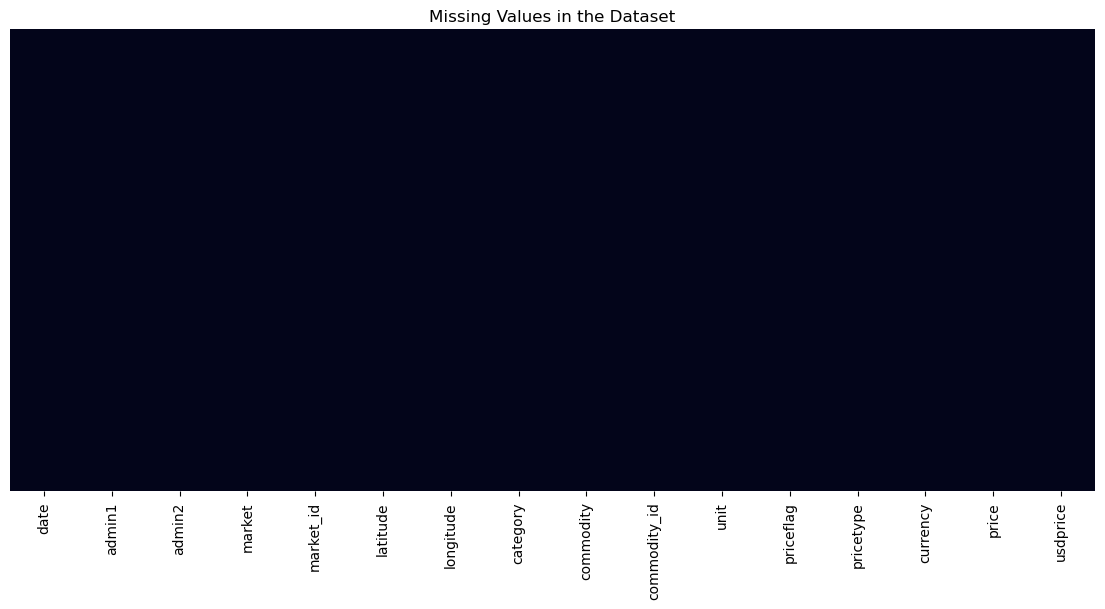

In [11]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in the Dataset")
plt.show()

In [12]:
print("Exact duplicate rows:", df.duplicated().sum())

duplicate_columns = [
    "date", "market", "commodity",
    "unit", "pricetype", "price"
]

print(
    "Duplicate observations using selected columns:",
    df.duplicated(subset=duplicate_columns).sum()
)

Exact duplicate rows: 0
Duplicate observations using selected columns: 0


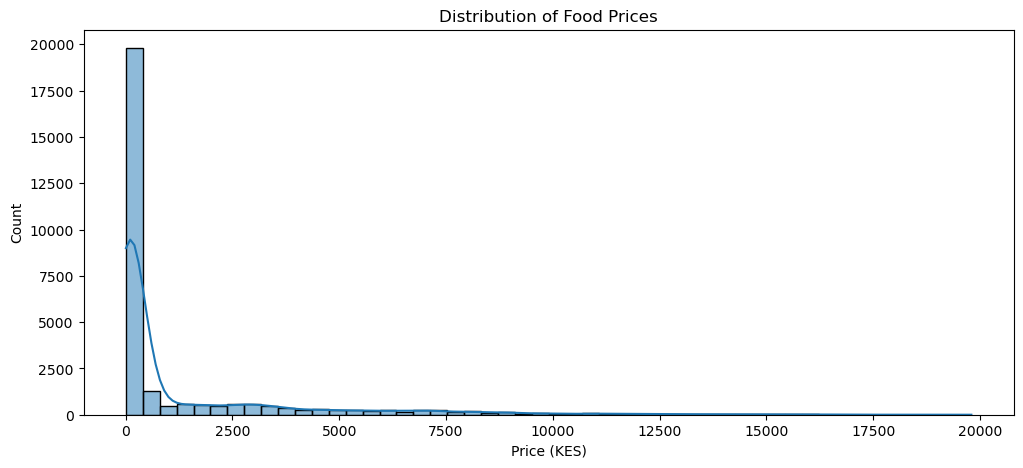

In [13]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["price"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Food Prices")
plt.xlabel("Price (KES)")
plt.show()

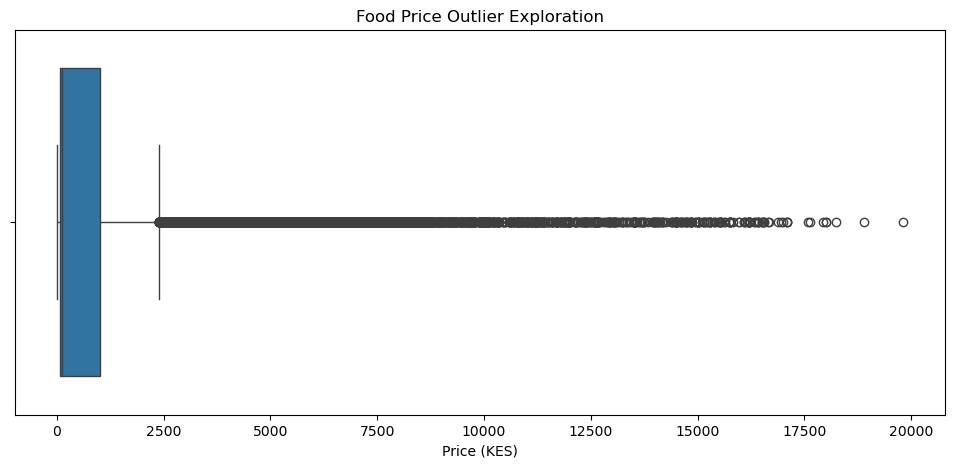

In [14]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df["price"])

plt.title("Food Price Outlier Exploration")
plt.xlabel("Price (KES)")
plt.show()

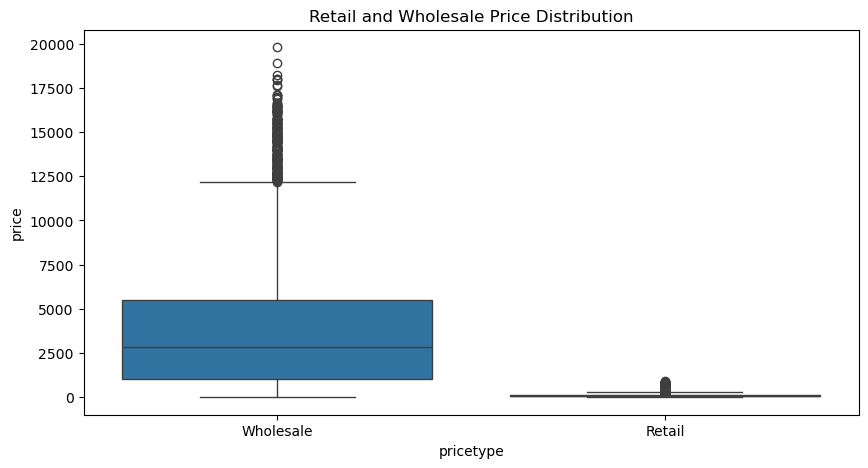

In [15]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="pricetype",
    y="price"
)

plt.title("Retail and Wholesale Price Distribution")
plt.show()

In [16]:
price_data = df["price"].dropna()

Q1 = price_data.quantile(0.25)
Q3 = price_data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))

Lower bound: -1325.0
Upper bound: 2395.0
Potential outliers: 5331


In [17]:
normality_sample = df["price"].dropna()

if len(normality_sample) > 5000:
    normality_sample = normality_sample.sample(
        5000,
        random_state= 42
    )

statistic, p_value = stats.shapiro(normality_sample)

print("Shapiro-Wilk statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: the sampled price distribution is not normal.")
else:
    print("Fail to reject H0: insufficient evidence against normality.")

Shapiro-Wilk statistic: 0.5606091070462287
P-value: 2.2201920372749528e-77
Reject H0: the sampled price distribution is not normal.


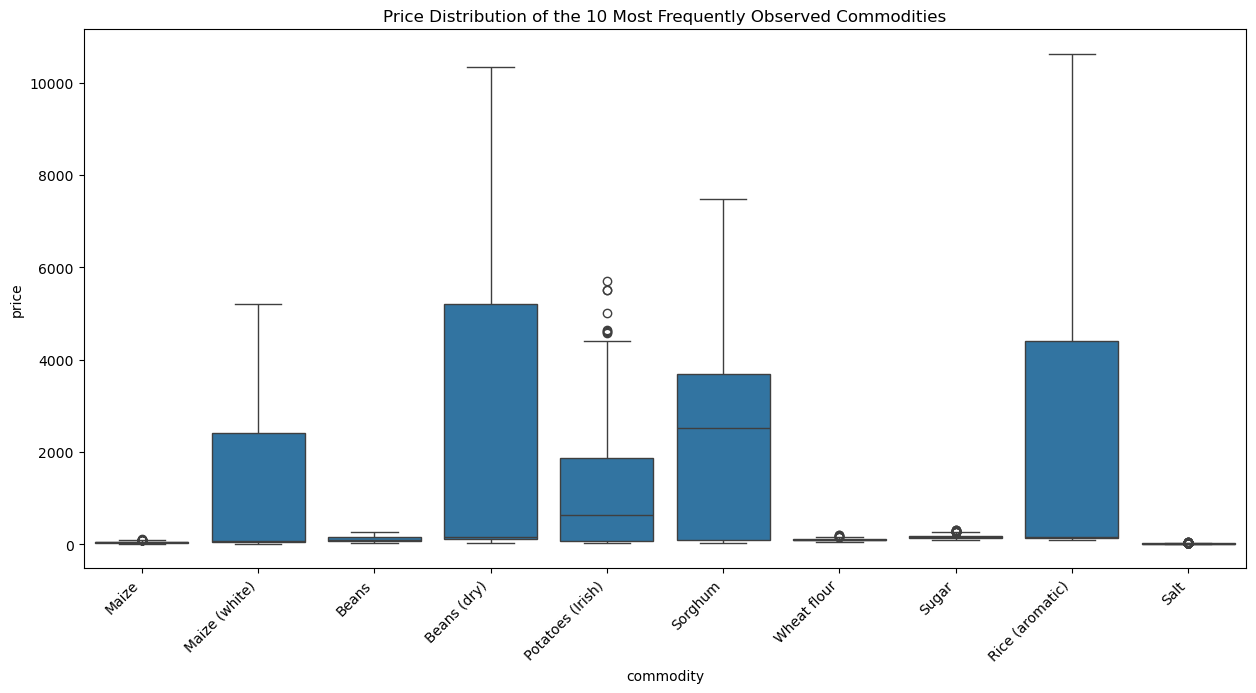

In [18]:
top_commodities = (
    df.groupby("commodity")["price"]
    .count()
    .sort_values(ascending=False)
    .head(10)
    .index
)

commodity_df = df[df["commodity"].isin(top_commodities)]

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=commodity_df,
    x="commodity",
    y="price"
)

plt.xticks(rotation=45, ha="right")
plt.title("Price Distribution of the 10 Most Frequently Observed Commodities")
plt.show()

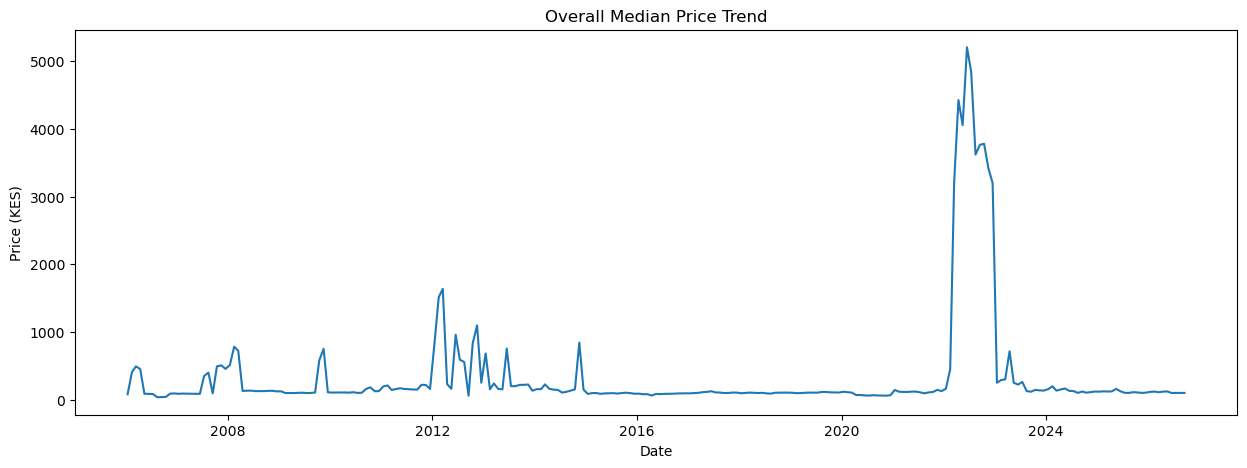

In [19]:
trend_df = df.dropna(subset=["date", "price"]).copy()

overall_trend = (
    trend_df.groupby("date")["price"]
    .median()
    .reset_index()
)

plt.figure(figsize=(15, 5))

plt.plot(
    overall_trend["date"],
    overall_trend["price"]
)

plt.title("Overall Median Price Trend")
plt.xlabel("Date")
plt.ylabel("Price (KES)")
plt.show()

In [20]:
market_coverage = (
    df.groupby("market")
    .agg(
        observations=("price", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        commodities=("commodity", "nunique")
    )
    .sort_values("observations", ascending=False)
)

display(market_coverage.head(20))

,observations,first_date,last_date,commodities
market,,,,
Nairobi,1762,2006-01-15,2022-03-15,23
Eldoret town (Uasin Gishu),1446,2006-01-15,2026-08-15,27
Kisumu,975,2006-01-15,2022-02-15,6
IFO (Daadab),828,2021-03-15,2026-09-15,26
Kakuma 3,810,2021-02-15,2026-08-15,27
Hagadera (Daadab),778,2021-01-15,2026-08-15,26
Kakuma 4,706,2021-02-15,2026-08-15,26
Kalobeyei (Village 1),702,2021-01-15,2026-08-15,27
Dagahaley (Daadab),695,2018-12-15,2026-08-15,27


In [21]:
commodity_coverage = (
    df.groupby(["commodity", "unit"])
    .agg(
        observations=("price", "count"),
        markets=("market", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .sort_values("observations", ascending=False)
)

display(commodity_coverage.head(20))

,,observations,markets,first_date,last_date
commodity,unit,,,,
Maize,KG,1548,35,2006-01-15,2026-09-15
Sugar,KG,1436,200,2018-12-15,2026-09-15
Wheat flour,KG,1420,200,2018-12-15,2026-09-15
Salt,200 G,1399,196,2018-12-15,2026-09-15
Beans,KG,1391,180,2006-01-15,2026-03-15
Beans (dry),KG,1145,36,2006-01-15,2026-09-15
Maize (white),KG,1052,9,2006-01-15,2020-12-15
Oil (vegetable),L,935,32,2006-01-15,2026-09-15
Rice,KG,758,32,2018-12-15,2026-09-15


In [22]:
price_change_df = df.sort_values("date").copy()

price_change_df["price_change"] = (
    price_change_df.groupby(
        ["market", "commodity", "unit", "pricetype"]
    )["price"].diff()
)

price_change_df["percentage_change"] = (
    price_change_df.groupby(
        ["market", "commodity", "unit", "pricetype"]
    )["price"].pct_change() * 100
)

display(price_change_df.head())

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,price_change,percentage_change
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22,NaN,NaN
29,2006-01-15,Rift Valley,Uasin Gishu,Eldoret town (Uasin Gishu),185,0.52,35.28,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,2799.00,38.93,NaN,NaN
28,2006-01-15,Rift Valley,Uasin Gishu,Eldoret town (Uasin Gishu),185,0.52,35.28,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,45.85,0.64,NaN,NaN
27,2006-01-15,Rift Valley,Uasin Gishu,Eldoret town (Uasin Gishu),185,0.52,35.28,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,1192.00,16.58,NaN,NaN
26,2006-01-15,Rift Valley,Uasin Gishu,Eldoret town (Uasin Gishu),185,0.52,35.28,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,12.96,0.18,NaN,NaN


In [23]:
def run_adf(series, name="Series"):
    series = series.dropna()

    if len(series) < 20:
        print(f"{name}: insufficient observations for ADF.")
        return None

    result = adfuller(series, autolag="AIC")

    print(f"\n{name}")
    print("ADF statistic:", result[0])
    print("P-value:", result[1])
    print("Critical values:", result[4])

    if result[1] < 0.05:
        print("Reject H0: evidence that the series is stationary.")
    else:
        print("Fail to reject H0: evidence of non-stationarity is insufficient.")

    return result

In [24]:
comparison_df = df[
    (df["commodity"] == "Maize (white)") &
    (df["unit"] == "KG") &
    (df["pricetype"] == "Retail") &
    (df["market"].isin(["Kitui", "Mandera"]))
].dropna(subset=["price"])

kitui_prices = comparison_df.loc[
    comparison_df["market"] == "Kitui", "price"
]

mandera_prices = comparison_df.loc[
    comparison_df["market"] == "Mandera", "price"
]

print("Kitui observations:", len(kitui_prices))
print("Mandera observations:", len(mandera_prices))

if len(kitui_prices) >= 2 and len(mandera_prices) >= 2:
    statistic, p_value = stats.mannwhitneyu(
        kitui_prices,
        mandera_prices,
        alternative="two-sided"
    )

    print("Mann-Whitney statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Reject H0: evidence of a difference in distributions.")
    else:
        print("Fail to reject H0: insufficient evidence of a difference.")

Kitui observations: 180
Mandera observations: 179
Mann-Whitney statistic: 4878.5
P-value: 3.044289993578084e-30
Reject H0: evidence of a difference in distributions.


In [25]:
# Compare several markets using Kruskal-Wallis
market_groups = []

maize_df = df[
    (df["commodity"] == "Maize (white)") &
    (df["unit"] == "KG") &
    (df["pricetype"] == "Retail")
]

for market, group in maize_df.groupby("market"):
    values = group["price"].dropna()

    if len(values) >= 10:
        market_groups.append(values)

if len(market_groups) >= 3:
    statistic, p_value = stats.kruskal(*market_groups)

    print("Kruskal-Wallis statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Reject H0: at least one market distribution differs.")
    else:
        print("Fail to reject H0: insufficient evidence of differences.")
else:
    print("Not enough markets with sufficient observations.")

Kruskal-Wallis statistic: 402.5301933924746
P-value: 5.386698205120496e-82
Reject H0: at least one market distribution differs.


In [26]:
# ============ 5. SERIES SELECTION AND MONTHLY PREPARATION ============
# Retail prices only. The price flag is NOT filtered: after 2020 most settlement-market prices are
# flagged "aggregate", and dropping them removes 2021-2022 and most recent months.
food_df = df[df["pricetype"] == "Retail"].copy()

food_df = food_df.dropna(
    subset=["date", "market", "commodity", "unit", "price"]
)

food_df = food_df[
    (food_df["price"] > 0)
].copy()

food_df = food_df.sort_values("date")

print("Filtered dataset shape:", food_df.shape)
display(food_df.head())

Filtered dataset shape: (19081, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.0,0.24
7,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,pulses and nuts,Beans (dry),262,KG,actual,Retail,KES,39.0,0.54
8,2006-01-15,Eastern,Marsabit,Marsabit,190,2.33,37.98,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,21.0,0.29
9,2006-01-15,Nairobi,Nairobi,Nairobi,184,-1.28,36.82,cereals and tubers,Bread,55,400 G,actual,Retail,KES,26.0,0.36
14,2006-01-15,Nairobi,Nairobi,Nairobi,184,-1.28,36.82,milk and dairy,"Milk (cow, pasteurized)",472,500 ML,actual,Retail,KES,22.0,0.31


In [27]:
# Create monthly dates
food_df["month"] = food_df["date"].dt.to_period("M").dt.to_timestamp()

food_df["year"] = food_df["date"].dt.year
food_df["month_number"] = food_df["date"].dt.month

display(food_df.head())

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,month,year,month_number
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.0,0.24,2006-01-01,2006,1
7,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,pulses and nuts,Beans (dry),262,KG,actual,Retail,KES,39.0,0.54,2006-01-01,2006,1
8,2006-01-15,Eastern,Marsabit,Marsabit,190,2.33,37.98,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,21.0,0.29,2006-01-01,2006,1
9,2006-01-15,Nairobi,Nairobi,Nairobi,184,-1.28,36.82,cereals and tubers,Bread,55,400 G,actual,Retail,KES,26.0,0.36,2006-01-01,2006,1
14,2006-01-15,Nairobi,Nairobi,Nairobi,184,-1.28,36.82,milk and dairy,"Milk (cow, pasteurized)",472,500 ML,actual,Retail,KES,22.0,0.31,2006-01-01,2006,1


In [28]:
food_df.tail()

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,month,year,month_number
28427,2026-09-15,Rift Valley,Turkana,Ethiopia (Kakuma),3253,3.72,34.85,miscellaneous food,Salt,185,200 G,aggregate,Retail,KES,15.0,0.120,2026-09-01,2026,9
28428,2026-09-15,Rift Valley,Turkana,Ethiopia (Kakuma),3253,3.72,34.85,miscellaneous food,Sugar,97,KG,aggregate,Retail,KES,155.0,1.190,2026-09-01,2026,9
28429,2026-09-15,Rift Valley,Turkana,Ethiopia (Kakuma),3253,3.72,34.85,oil and fats,Oil (vegetable),96,L,aggregate,Retail,KES,290.0,2.240,2026-09-01,2026,9
28416,2026-09-15,North Eastern,Garissa,IFO (Daadab),3255,0.11,40.32,vegetables and fruits,Bananas,254,Unit,aggregate,Retail,KES,5.0,0.039,2026-09-01,2026,9
28462,2026-09-15,Rift Valley,Turkana,Mogadishu (Kakuma),3245,3.72,34.85,vegetables and fruits,Bananas,254,Unit,aggregate,Retail,KES,20.0,0.150,2026-09-01,2026,9


In [29]:
# Recent, well-covered staple series for forecasting and anomaly detection
STAPLES = ["Maize flour", "Beans (dry)", "Rice", "Sugar", "Wheat flour"]
series_keys = ["commodity", "unit", "market"]

coverage = (
    food_df.groupby(series_keys)["month"]
    .agg(observations="nunique", first_month="min", last_month="max")
    .reset_index()
)
latest_month = food_df["month"].max()

recent_staples = coverage[
    coverage["commodity"].isin(STAPLES)
    & (coverage["unit"] == "KG")
    & (coverage["observations"] >= 36)
    & (coverage["last_month"] >= latest_month - pd.DateOffset(months=3))
]

# markets that have all five staples, ranked by how much data they have
market_scores = recent_staples.groupby("market").agg(
    staples=("commodity", "nunique"),
    observations=("observations", "sum")
)
market_scores = market_scores[market_scores["staples"] == len(STAPLES)].sort_values(
    "observations", ascending=False
)

selected_series = recent_staples[recent_staples["market"].isin(market_scores.head(3).index)]
print("Latest month in the data:", latest_month.date())
display(selected_series.sort_values(["market", "commodity"]))

Latest month in the data: 2026-09-01


,commodity,unit,market,observations,first_month,last_month
209,Beans (dry),KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
773,Maize flour,KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
1618,Rice,KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
2196,Sugar,KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
2397,Wheat flour,KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
213,Beans (dry),KG,Hagadera (Daadab),53,2021-01-01,2026-08-01
777,Maize flour,KG,Hagadera (Daadab),53,2021-01-01,2026-08-01
1622,Rice,KG,Hagadera (Daadab),53,2021-01-01,2026-08-01
2217,Sugar,KG,Hagadera (Daadab),54,2021-01-01,2026-08-01
2418,Wheat flour,KG,Hagadera (Daadab),54,2021-01-01,2026-08-01


In [30]:
# Filter the selected series
selected = food_df.merge(
    selected_series[series_keys],
    on=series_keys,
    how="inner"
)

print("Selected records:", selected.shape)
print("Selected series:", selected[series_keys].drop_duplicates().shape[0])

display(selected.head())

Selected records: (822, 19)
Selected series: 15


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,month,year,month_number
0,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,cereals and tubers,Rice,52,KG,aggregate,Retail,KES,120.00,1.17,2018-12-01,2018,12
1,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,pulses and nuts,Beans (dry),262,KG,aggregate,Retail,KES,120.00,1.17,2018-12-01,2018,12
2,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,miscellaneous food,Sugar,97,KG,aggregate,Retail,KES,120.00,1.17,2018-12-01,2018,12
3,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,cereals and tubers,Wheat flour,58,KG,aggregate,Retail,KES,102.86,1.00,2018-12-01,2018,12
4,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,cereals and tubers,Maize flour,76,KG,aggregate,Retail,KES,102.86,1.00,2018-12-01,2018,12


In [31]:
# Aggregate to monthly prices
monthly_series = (
    selected.groupby(
        ["month", "commodity", "unit", "market"]
    )["price"]
    .median()
    .reset_index()
)

monthly_series["series"] = (
    monthly_series["commodity"] + " | " +
    monthly_series["unit"] + " | " +
    monthly_series["market"]
)

monthly_df = (
    monthly_series.pivot(
        index="month",
        columns="series",
        values="price"
    )
    .sort_index()
)

monthly_df = monthly_df.asfreq("MS")

print("Monthly dataset shape:", monthly_df.shape)
display(monthly_df.head())

Monthly dataset shape: (94, 15)


series,Beans (dry) | KG | Dagahaley (Daadab),Beans (dry) | KG | Hagadera (Daadab),Beans (dry) | KG | IFO (Daadab),Maize flour | KG | Dagahaley (Daadab),Maize flour | KG | Hagadera (Daadab),Maize flour | KG | IFO (Daadab),Rice | KG | Dagahaley (Daadab),Rice | KG | Hagadera (Daadab),Rice | KG | IFO (Daadab),Sugar | KG | Dagahaley (Daadab),Sugar | KG | Hagadera (Daadab),Sugar | KG | IFO (Daadab),Wheat flour | KG | Dagahaley (Daadab),Wheat flour | KG | Hagadera (Daadab),Wheat flour | KG | IFO (Daadab)
month,,,,,,,,,,,,,,,
2018-12-01,120.0,NaN,NaN,102.86,NaN,NaN,120.0,NaN,NaN,120.0,NaN,NaN,102.86,NaN,NaN
2019-01-01,120.0,NaN,NaN,102.86,NaN,NaN,120.0,NaN,NaN,120.0,NaN,NaN,102.86,NaN,NaN
2019-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-04-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
missing_months = pd.DataFrame({
    "Missing Count": monthly_df.isna().sum(),
    "Missing Percentage": monthly_df.isna().mean() * 100
})

display(missing_months)

,Missing Count,Missing Percentage
series,,
Beans (dry) | KG | Dagahaley (Daadab),38,40.425532
Beans (dry) | KG | Hagadera (Daadab),41,43.617021
Beans (dry) | KG | IFO (Daadab),39,41.489362
Maize flour | KG | Dagahaley (Daadab),38,40.425532
Maize flour | KG | Hagadera (Daadab),41,43.617021
Maize flour | KG | IFO (Daadab),39,41.489362
Rice | KG | Dagahaley (Daadab),38,40.425532
Rice | KG | Hagadera (Daadab),41,43.617021
Rice | KG | IFO (Daadab),39,41.489362


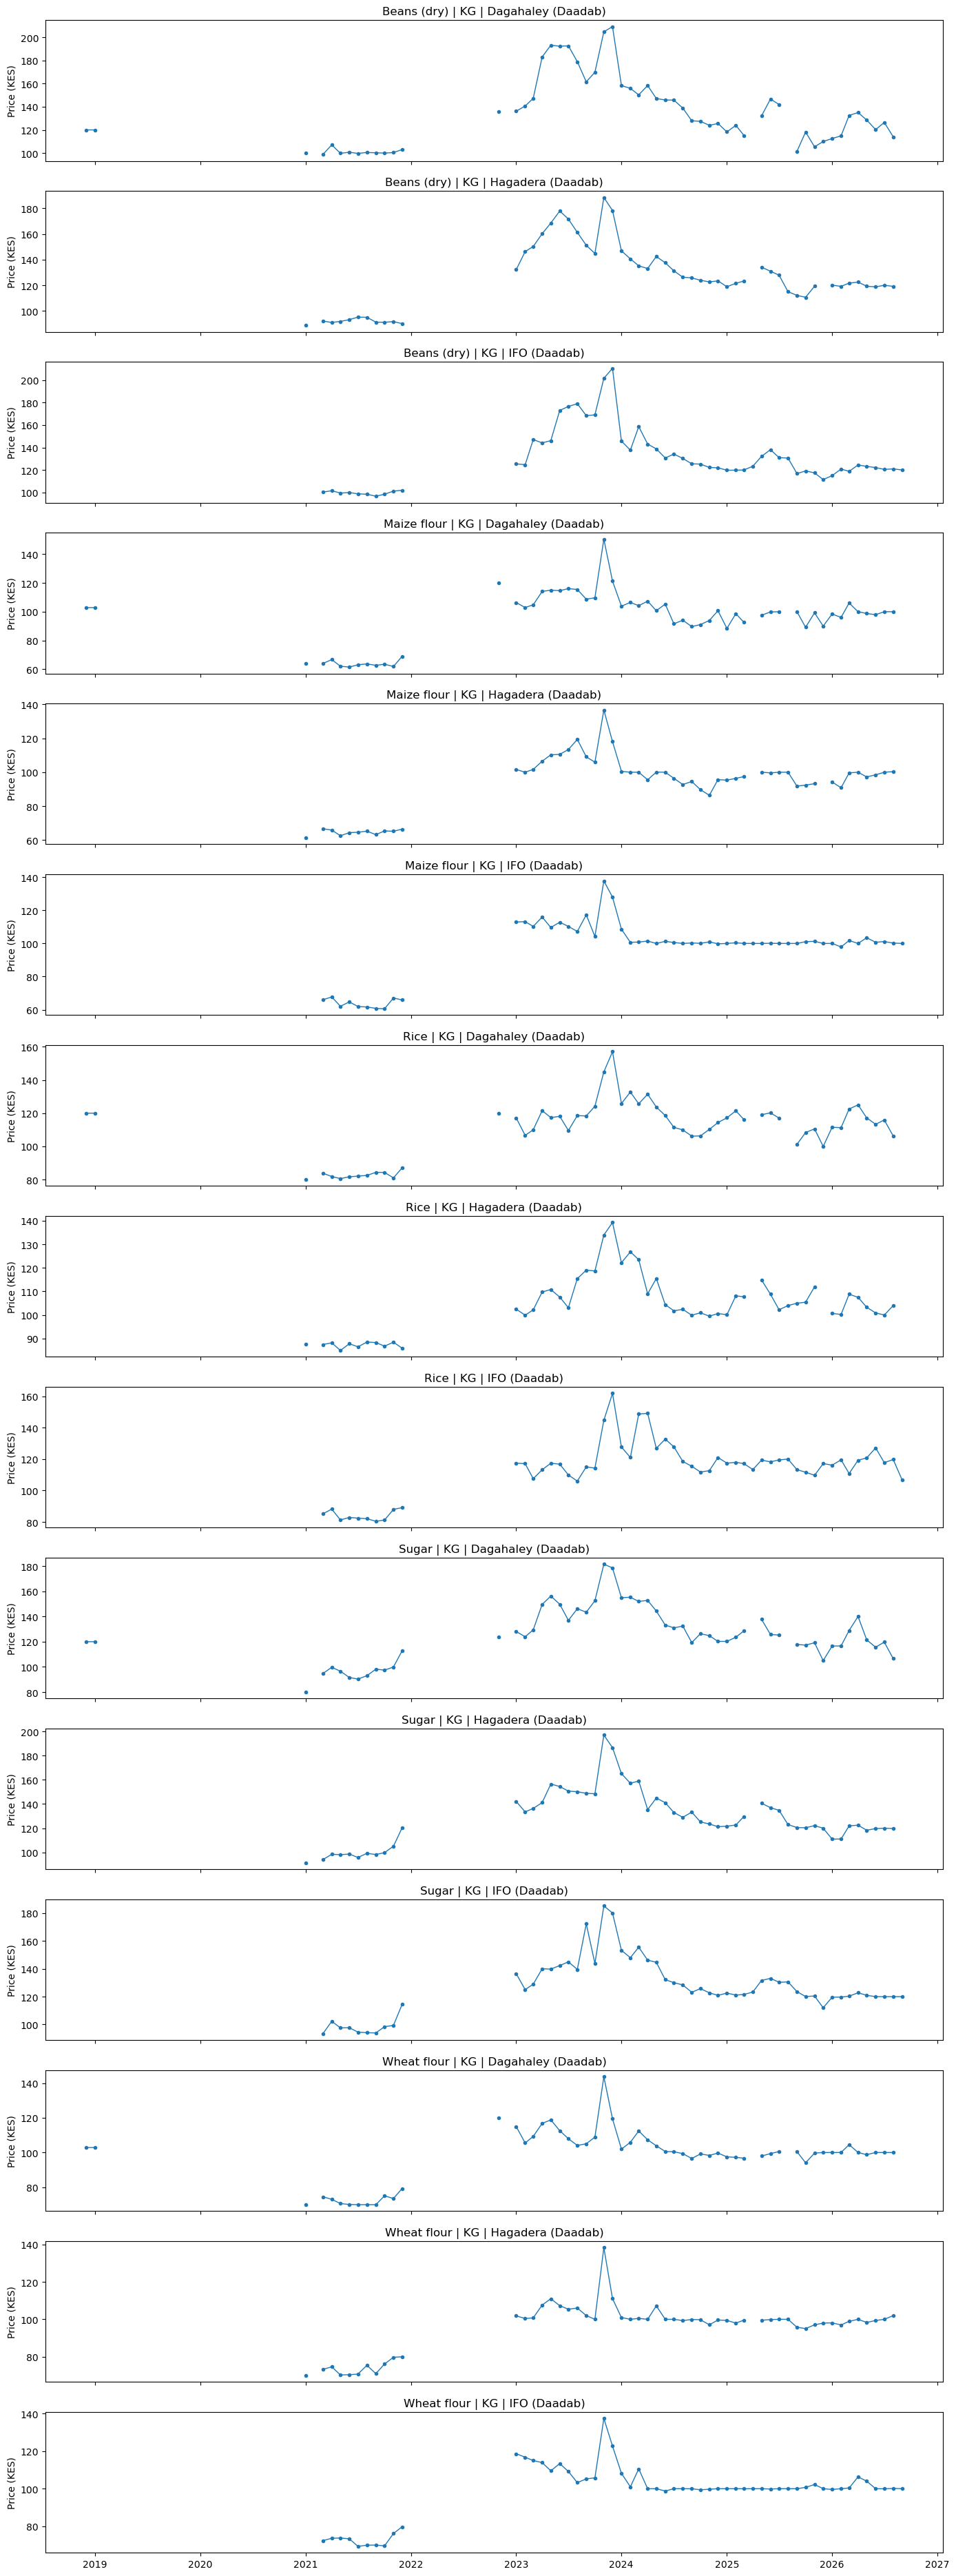

In [33]:
fig, axes = plt.subplots(
    nrows=len(monthly_df.columns),
    ncols=1,
    figsize=(14, 2.5 * len(monthly_df.columns)),
    sharex=True
)

if len(monthly_df.columns) == 1:
    axes = [axes]

for ax, column in zip(axes, monthly_df.columns):
    ax.plot(
        monthly_df.index,
        monthly_df[column],
        marker=".",
        linewidth=1
    )
    ax.set_title(column)
    ax.set_ylabel("Price (KES)")

plt.tight_layout()
plt.show()

In [34]:
# Fill gaps of up to 3 months, then keep each series' latest unbroken run
def latest_unbroken_run(series, max_gap=3):
    s = series.copy()
    first, last = s.first_valid_index(), s.last_valid_index()
    if first is None:
        return s
    s = s.interpolate(method="time", limit=max_gap, limit_area="inside")
    inside = s.loc[first:last]
    nan_pos = np.where(inside.isna().to_numpy())[0]
    if len(nan_pos):
        s.loc[:inside.index[nan_pos[-1]]] = np.nan
    return s


monthly_clean = monthly_df.apply(latest_unbroken_run)

print("Months kept per series after interpolation:")
display(monthly_clean.notna().sum())

Months kept per series after interpolation:


series
Beans (dry) | KG | Dagahaley (Daadab)    46
Beans (dry) | KG | Hagadera (Daadab)     44
Beans (dry) | KG | IFO (Daadab)          45
Maize flour | KG | Dagahaley (Daadab)    46
Maize flour | KG | Hagadera (Daadab)     44
Maize flour | KG | IFO (Daadab)          45
Rice | KG | Dagahaley (Daadab)           46
Rice | KG | Hagadera (Daadab)            44
Rice | KG | IFO (Daadab)                 45
Sugar | KG | Dagahaley (Daadab)          46
Sugar | KG | Hagadera (Daadab)           44
Sugar | KG | IFO (Daadab)                45
Wheat flour | KG | Dagahaley (Daadab)    46
Wheat flour | KG | Hagadera (Daadab)     44
Wheat flour | KG | IFO (Daadab)          45
dtype: int64

In [35]:
for column in monthly_clean.columns:
    series = monthly_clean[column].dropna()

    print(
        column,
        "| Observations:", len(series),
        "| Start:", series.index.min(),
        "| End:", series.index.max()
    )

Beans (dry) | KG | Dagahaley (Daadab) | Observations: 46 | Start: 2022-11-01 00:00:00 | End: 2026-08-01 00:00:00
Beans (dry) | KG | Hagadera (Daadab) | Observations: 44 | Start: 2023-01-01 00:00:00 | End: 2026-08-01 00:00:00
Beans (dry) | KG | IFO (Daadab) | Observations: 45 | Start: 2023-01-01 00:00:00 | End: 2026-09-01 00:00:00
Maize flour | KG | Dagahaley (Daadab) | Observations: 46 | Start: 2022-11-01 00:00:00 | End: 2026-08-01 00:00:00
Maize flour | KG | Hagadera (Daadab) | Observations: 44 | Start: 2023-01-01 00:00:00 | End: 2026-08-01 00:00:00
Maize flour | KG | IFO (Daadab) | Observations: 45 | Start: 2023-01-01 00:00:00 | End: 2026-09-01 00:00:00
Rice | KG | Dagahaley (Daadab) | Observations: 46 | Start: 2022-11-01 00:00:00 | End: 2026-08-01 00:00:00
Rice | KG | Hagadera (Daadab) | Observations: 44 | Start: 2023-01-01 00:00:00 | End: 2026-08-01 00:00:00
Rice | KG | IFO (Daadab) | Observations: 45 | Start: 2023-01-01 00:00:00 | End: 2026-09-01 00:00:00
Sugar | KG | Dagahaley (D

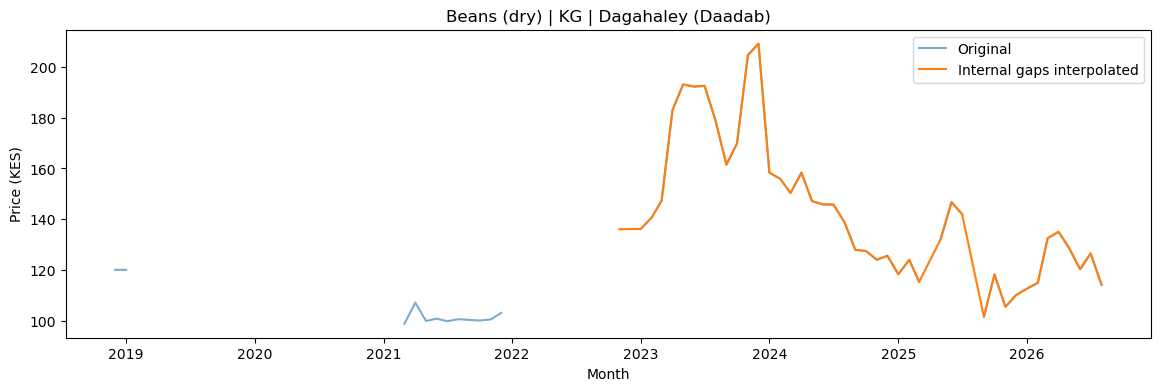

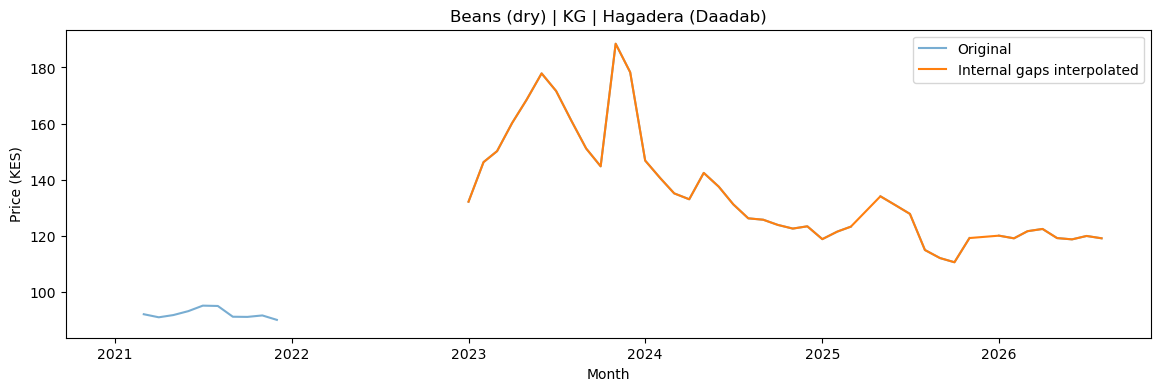

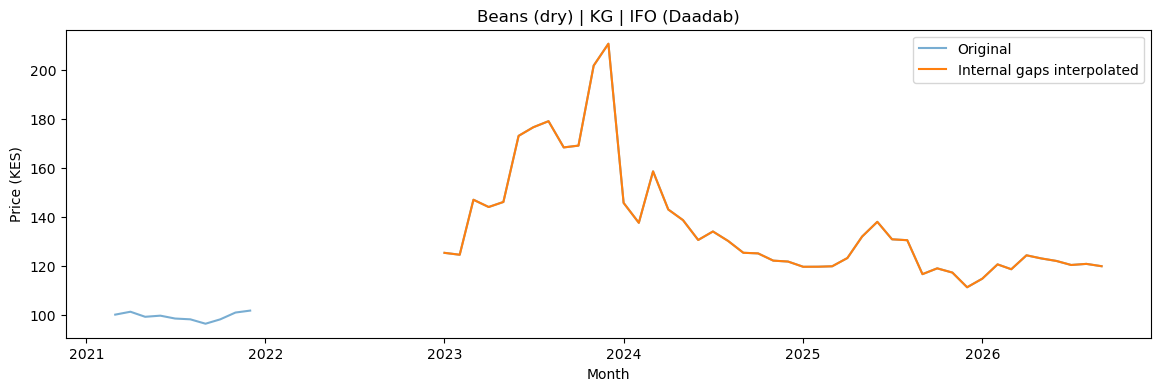

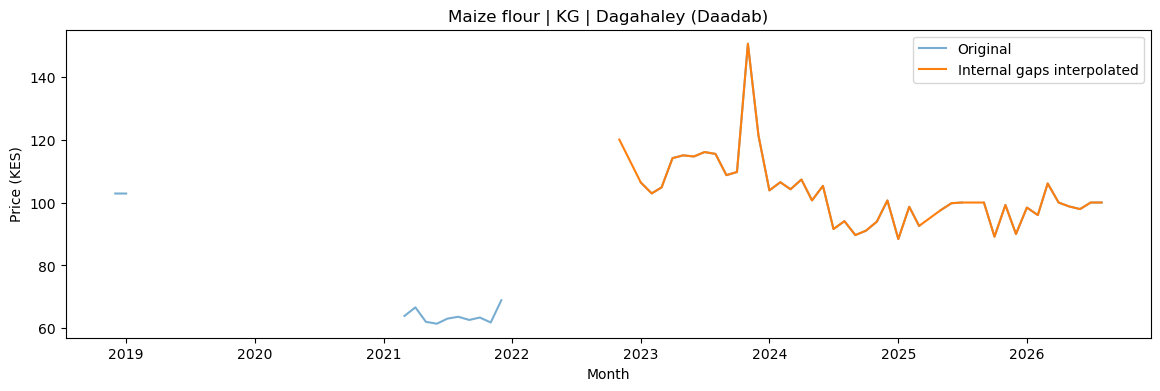

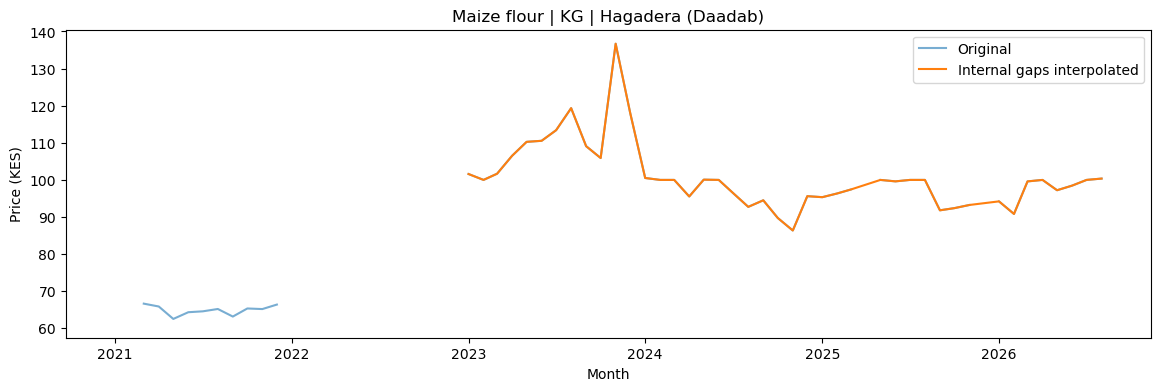

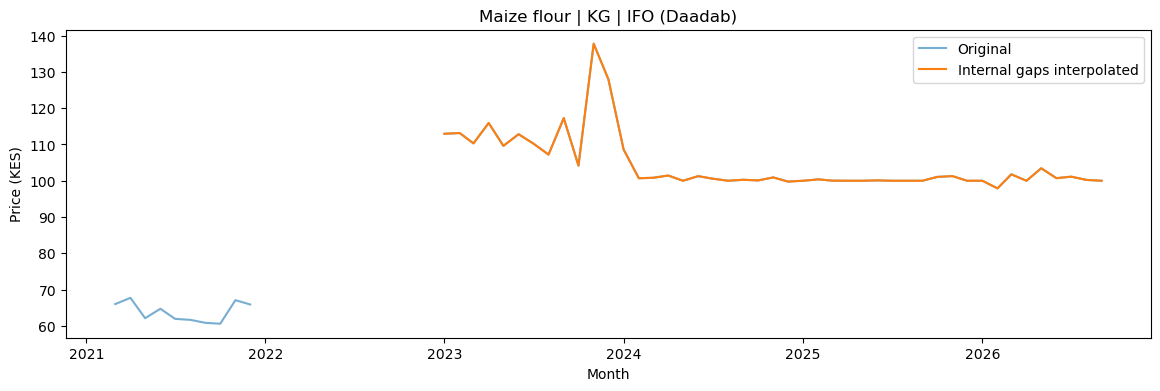

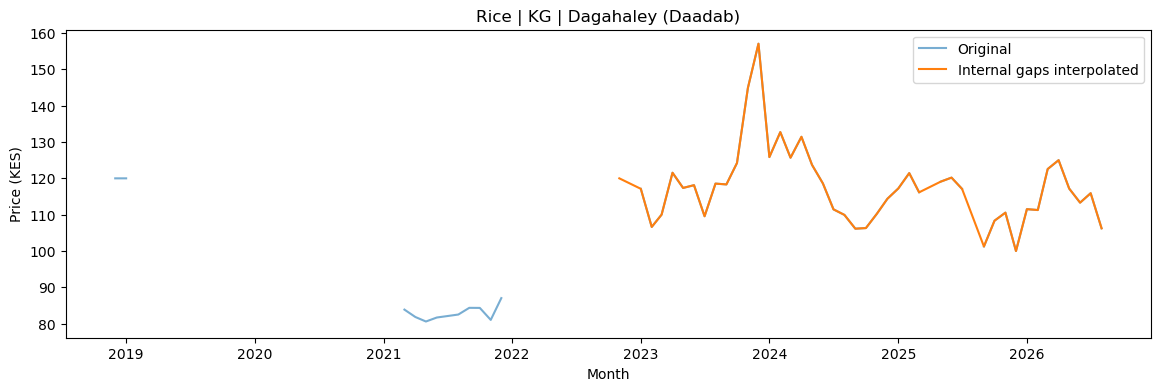

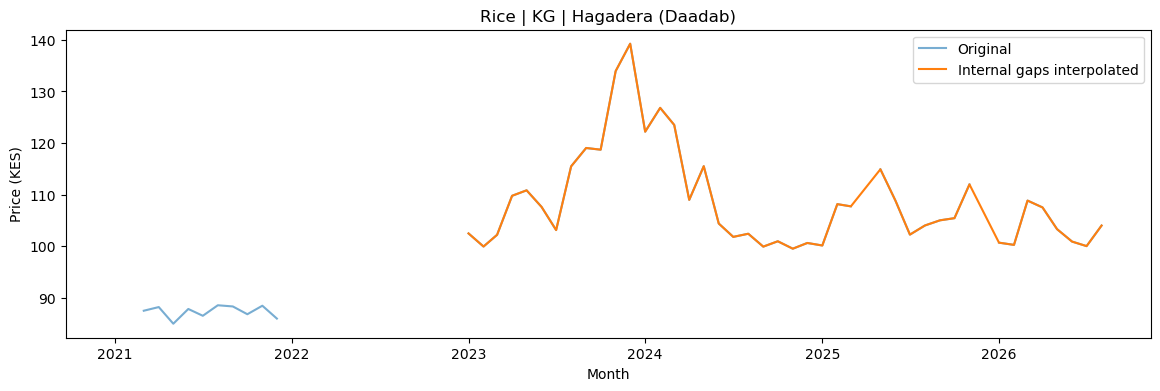

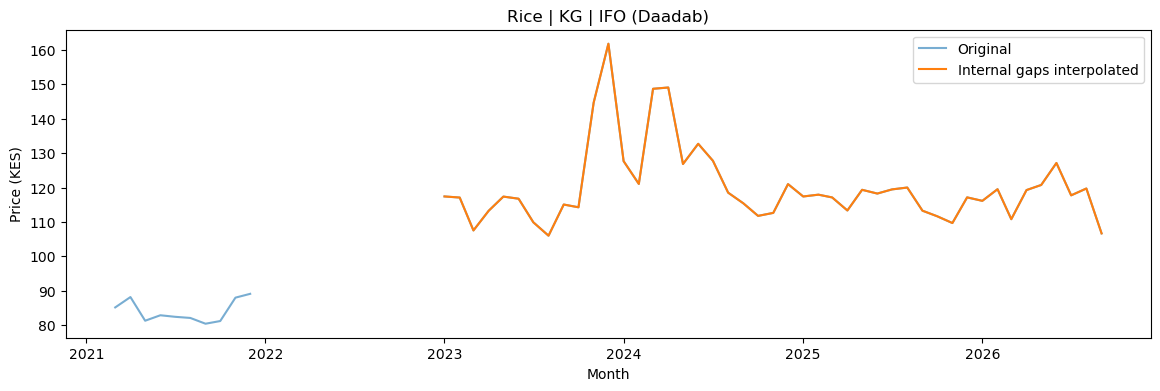

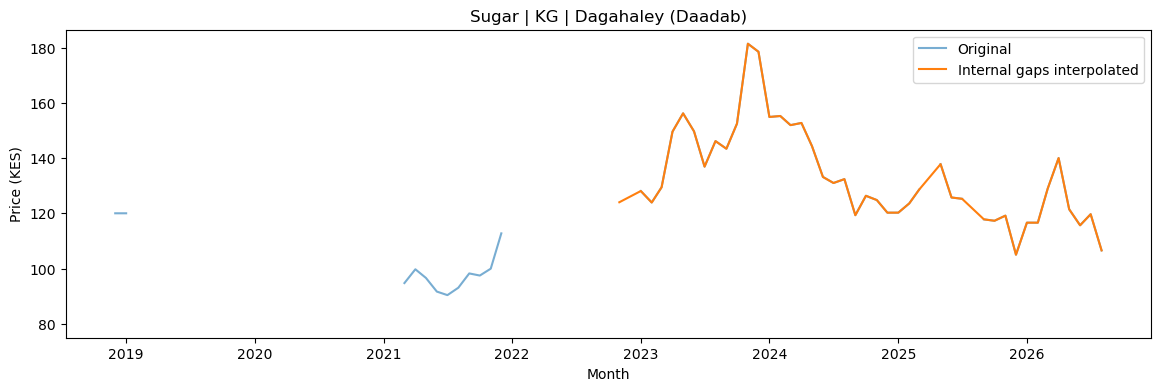

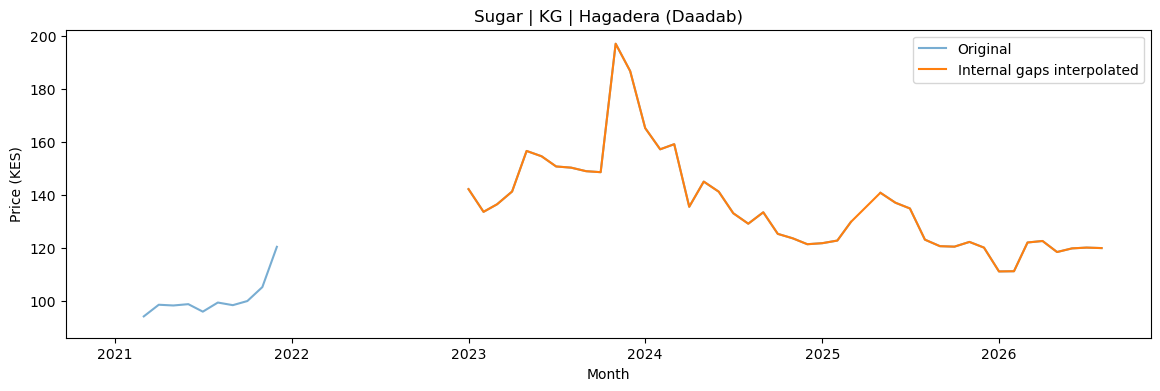

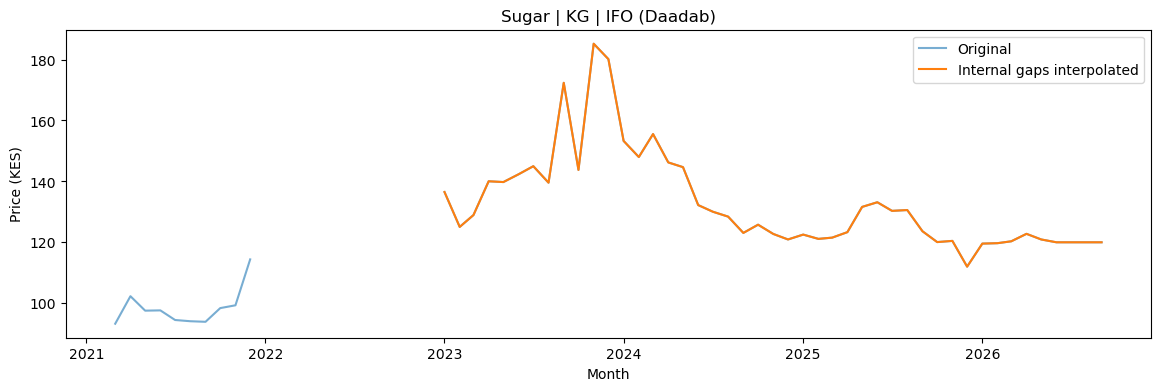

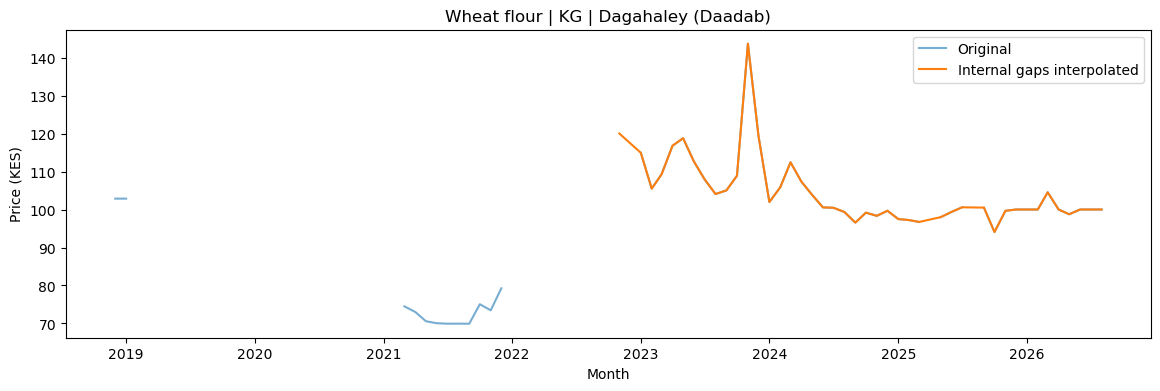

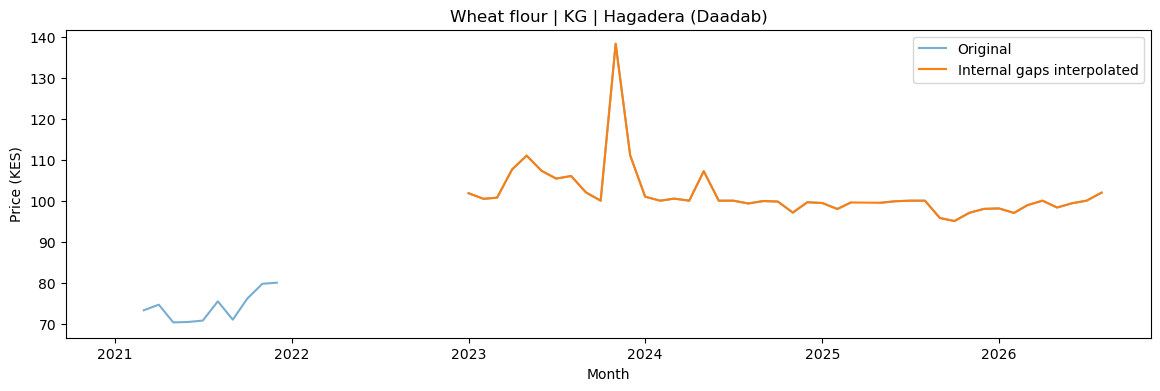

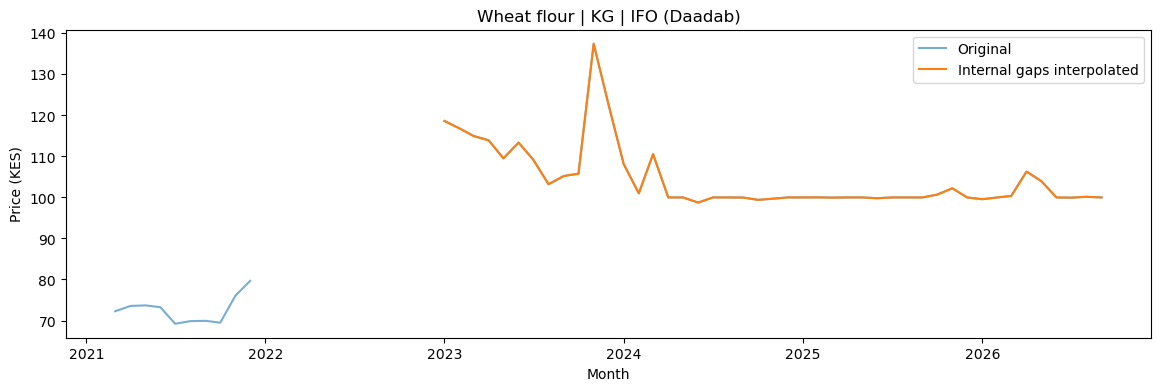

In [36]:
for column in monthly_clean.columns:
    plt.figure(figsize=(14, 4))

    plt.plot(
        monthly_df.index,
        monthly_df[column],
        label="Original",
        alpha=0.6
    )

    plt.plot(
        monthly_clean.index,
        monthly_clean[column],
        label="Internal gaps interpolated"
    )

    plt.title(column)
    plt.xlabel("Month")
    plt.ylabel("Price (KES)")
    plt.legend()
    plt.show()

In [37]:
# Descriptive statistics by series
series_statistics = monthly_clean.describe().T

series_statistics["missing"] = monthly_clean.isna().sum()

display(series_statistics)

,count,mean,std,min,25%,50%,75%,max,missing
series,,,,,,,,,
Beans (dry) | KG | Dagahaley (Daadab),46.0,141.935020,26.992057,101.50,123.815287,136.034426,154.450000,209.16,48
Beans (dry) | KG | Hagadera (Daadab),44.0,135.064355,19.516205,110.64,120.082500,128.336803,145.172500,188.46,50
Beans (dry) | KG | IFO (Daadab),45.0,136.546222,23.138443,111.43,120.750000,125.470000,144.100000,210.57,49
Maize flour | KG | Dagahaley (Daadab),46.0,103.239840,11.014526,88.38,97.642500,100.000000,107.095000,150.47,48
Maize flour | KG | Hagadera (Daadab),44.0,100.543595,8.894824,86.37,95.492500,100.000000,100.787500,136.70,50
Maize flour | KG | IFO (Daadab),45.0,104.489333,8.035951,97.90,100.000000,100.710000,107.220000,137.80,49
Rice | KG | Dagahaley (Daadab),46.0,117.382014,10.257774,100.00,110.320000,117.205000,121.130000,157.04,48
Rice | KG | Hagadera (Daadab),44.0,108.641740,9.324889,99.50,102.090000,105.916311,111.515451,139.25,50
Rice | KG | IFO (Daadab),45.0,120.146222,11.406281,106.00,113.330000,117.410000,120.750000,161.81,49


In [38]:
# TIME-SERIES ANALYSIS 
# percentage changes
monthly_returns = monthly_clean.pct_change() * 100

display(monthly_returns.describe().T)

,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
Beans (dry) | KG | Dagahaley (Daadab),46.0,0.020301,9.056555,-24.297189,-5.550788,0.025313,4.779700,24.308904
Beans (dry) | KG | Hagadera (Daadab),44.0,-0.024857,6.764294,-17.638811,-3.569038,-0.741304,2.164435,30.151934
Beans (dry) | KG | IFO (Daadab),44.0,0.233114,8.067265,-30.773614,-2.486288,-0.288762,2.685942,19.261932
Maize flour | KG | Dagahaley (Daadab),46.0,-0.043670,8.715709,-19.379278,-5.367280,0.000000,2.683039,37.164995
Maize flour | KG | Hagadera (Daadab),44.0,0.169441,6.522455,-14.856852,-2.816048,0.375763,1.400425,29.084042
Maize flour | KG | IFO (Daadab),44.0,-0.097546,6.329973,-15.127364,-1.499473,-0.014996,0.389260,32.271069
Rice | KG | Dagahaley (Daadab),46.0,-0.047838,6.608117,-19.861182,-4.303744,0.080075,3.665254,16.631782
Rice | KG | Hagadera (Daadab),44.0,0.174788,5.370837,-12.251346,-2.513540,-0.138621,3.229521,12.839090
Rice | KG | IFO (Daadab),44.0,0.105106,8.234584,-21.098820,-3.592041,-0.607546,3.894281,26.649746


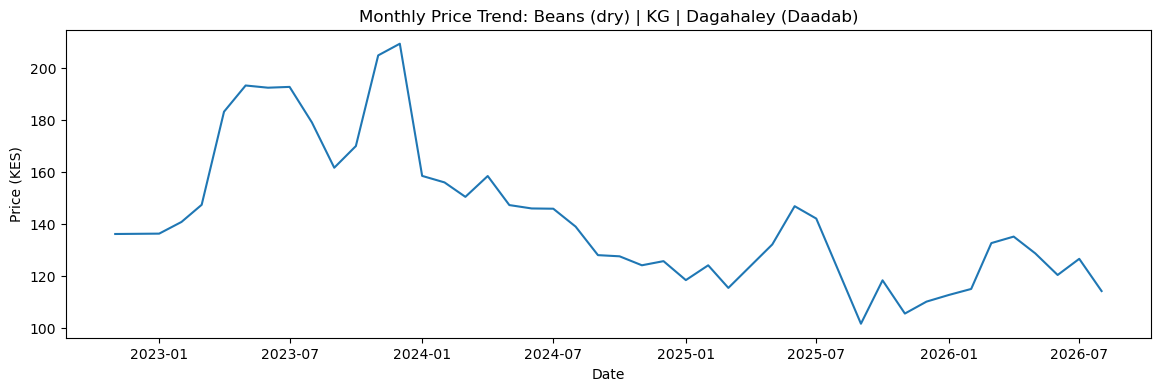

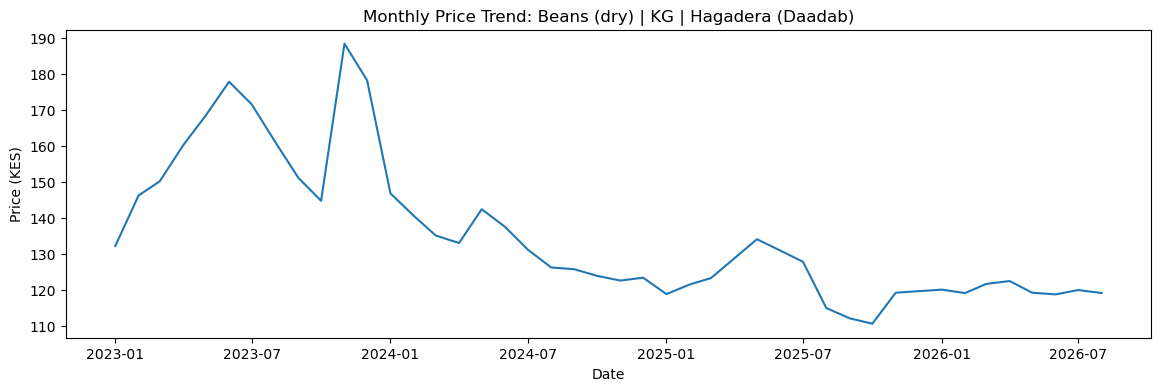

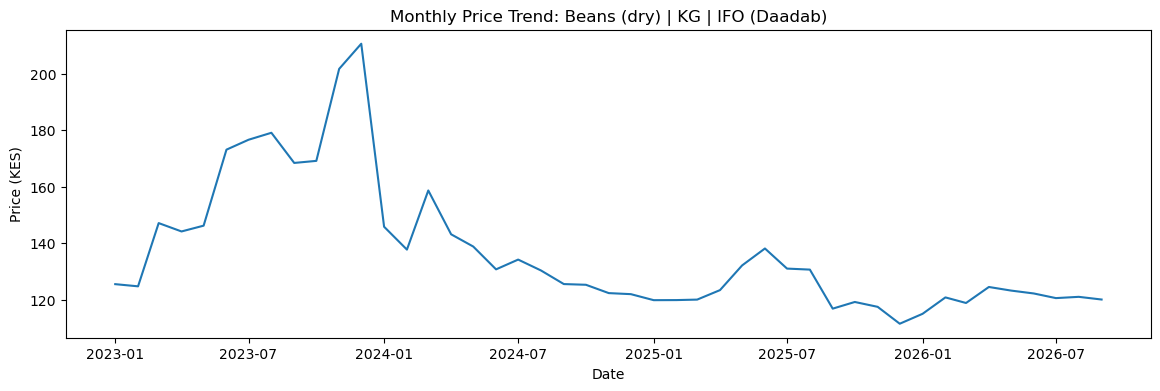

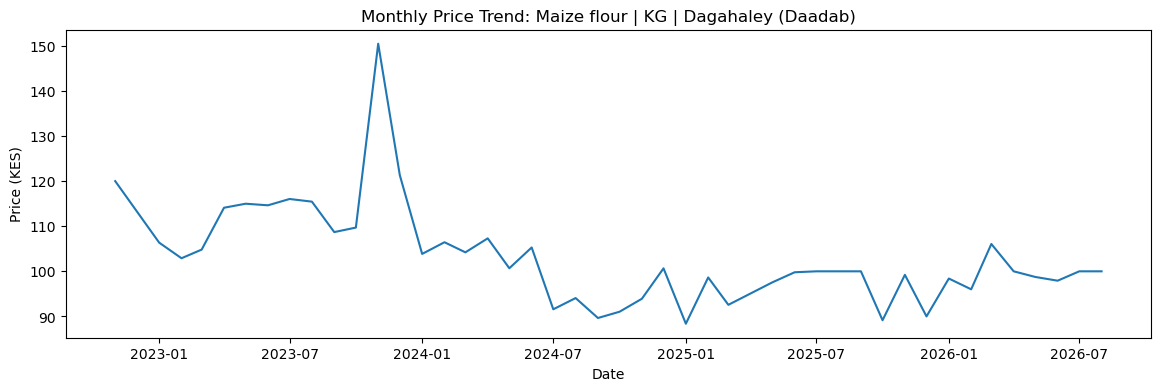

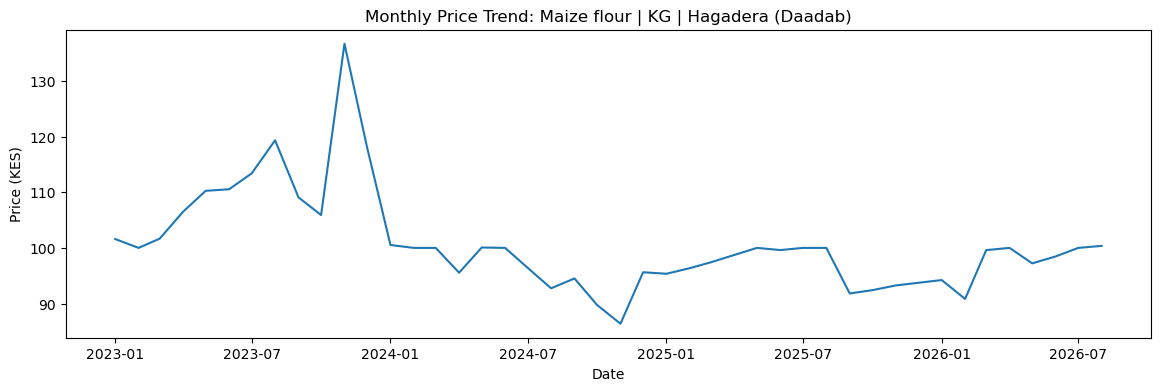

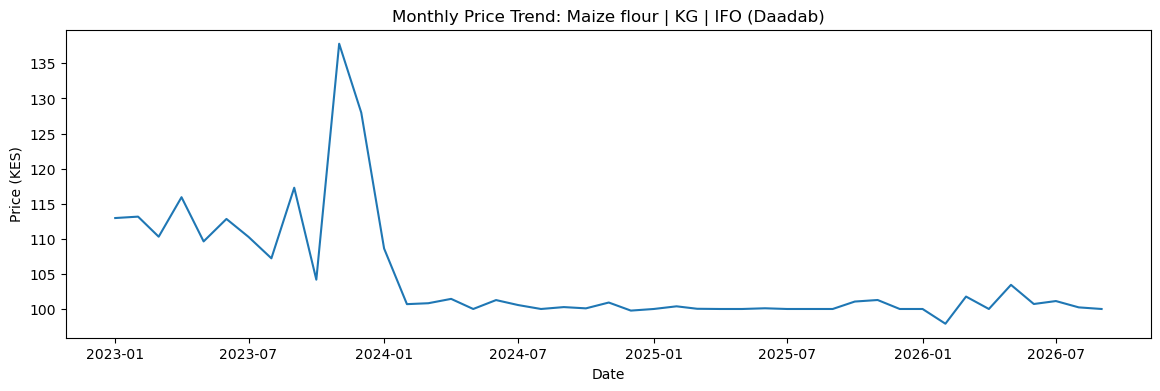

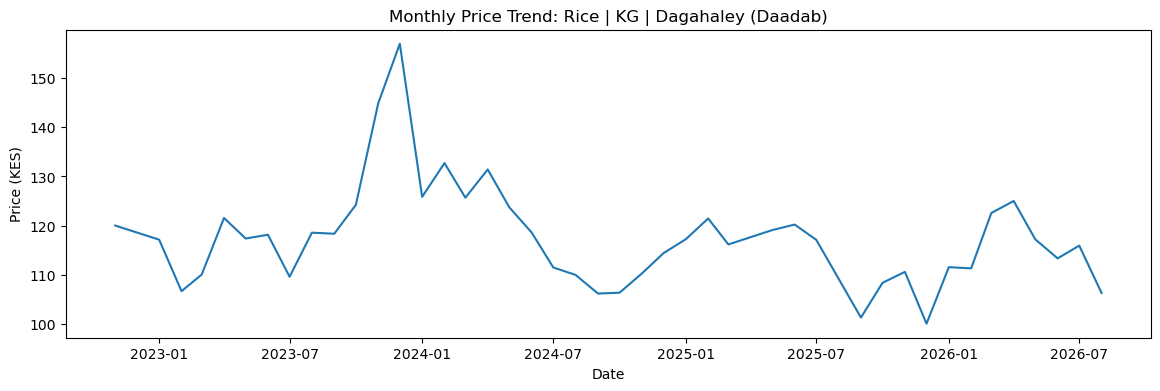

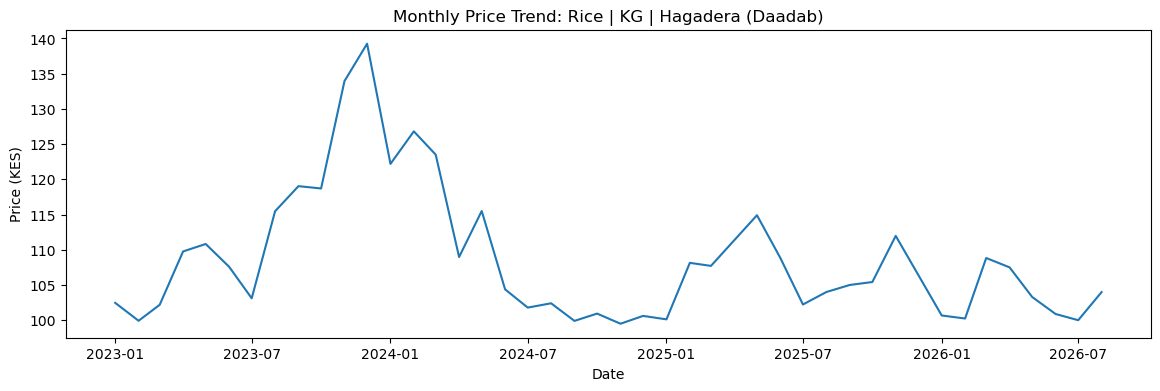

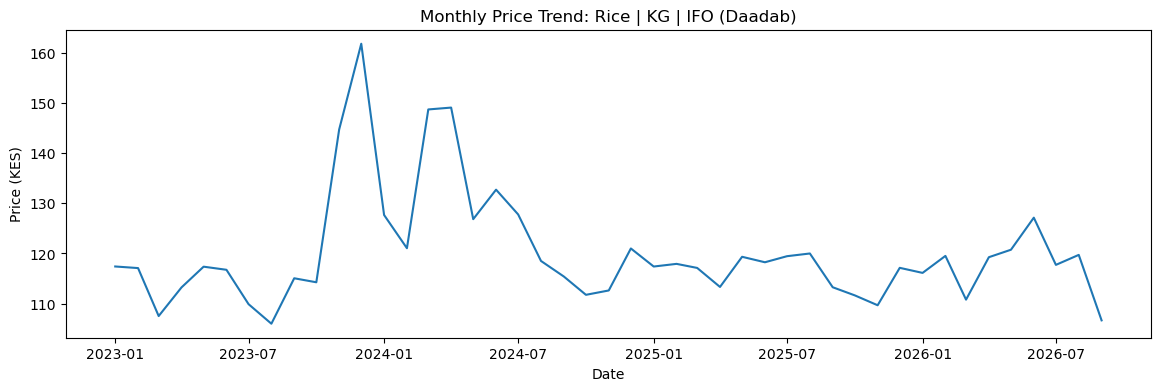

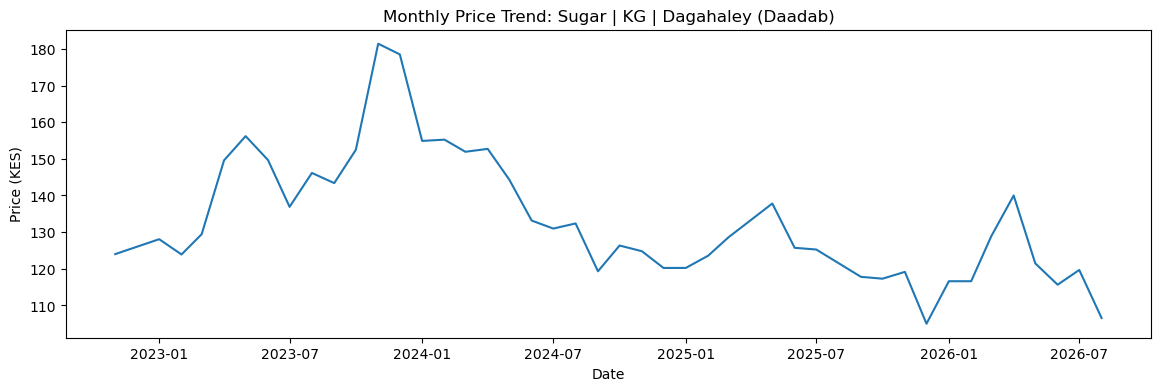

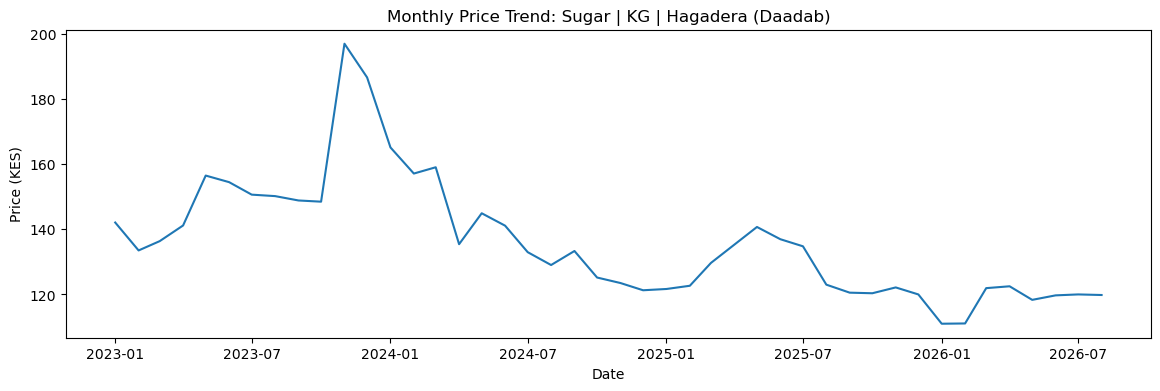

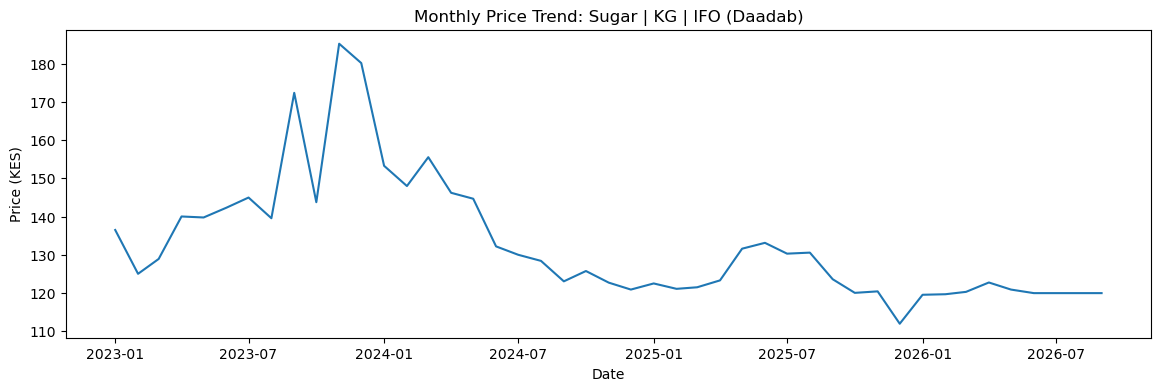

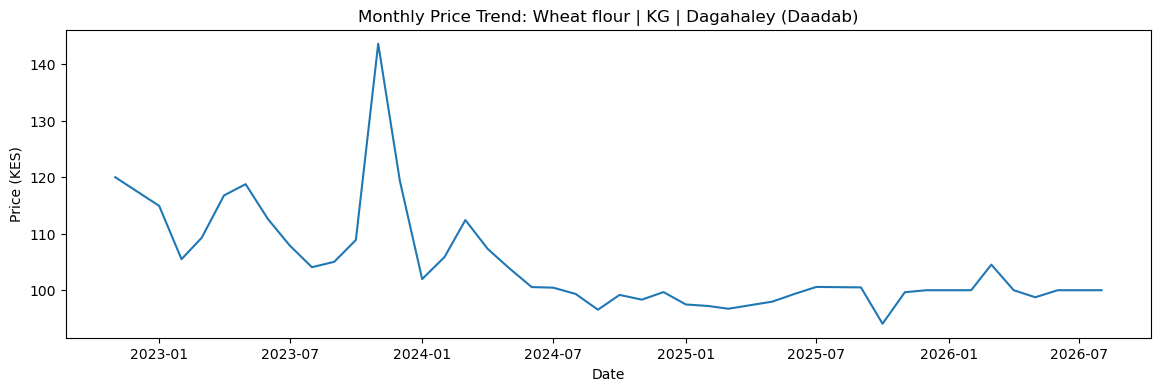

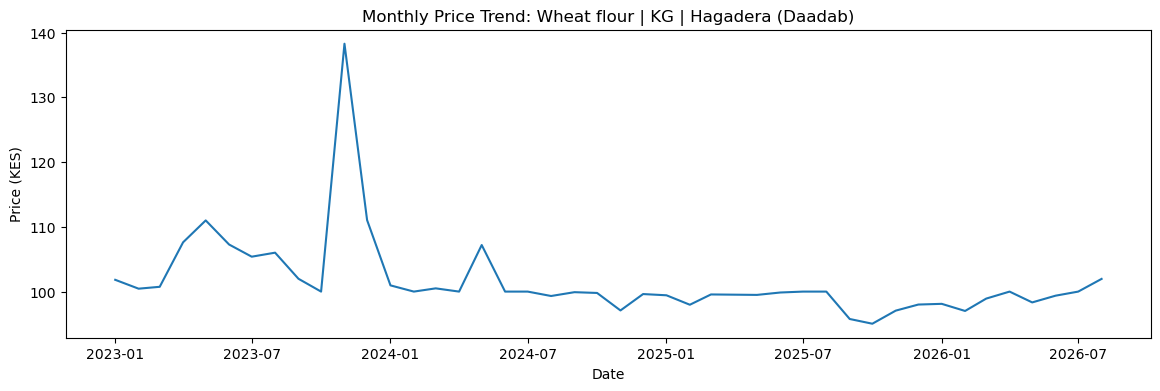

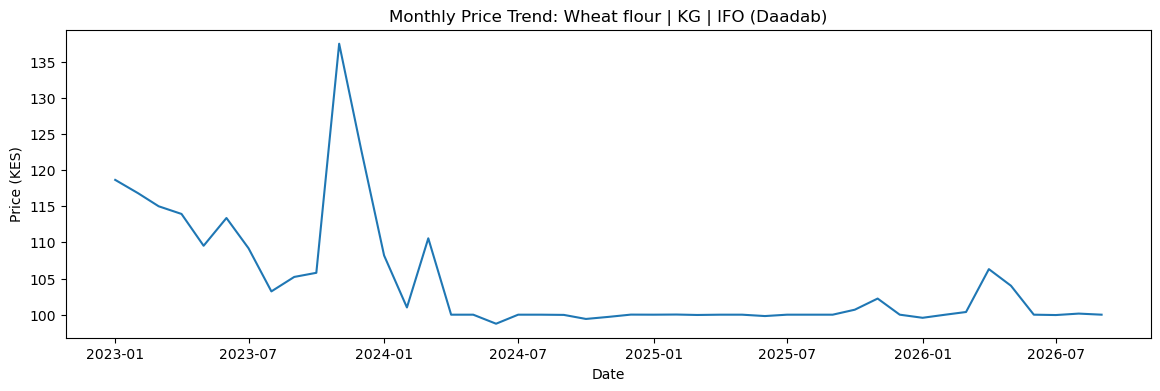

In [39]:
# individual trends
for column in monthly_clean.columns:
    plt.figure(figsize=(14, 4))

    plt.plot(monthly_clean[column])

    plt.title(f"Monthly Price Trend: {column}")
    plt.xlabel("Date")
    plt.ylabel("Price (KES)")
    plt.show()

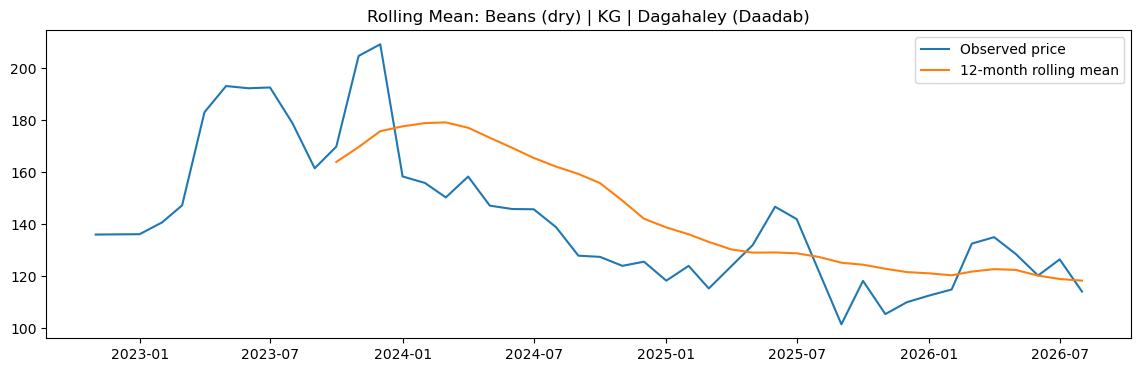

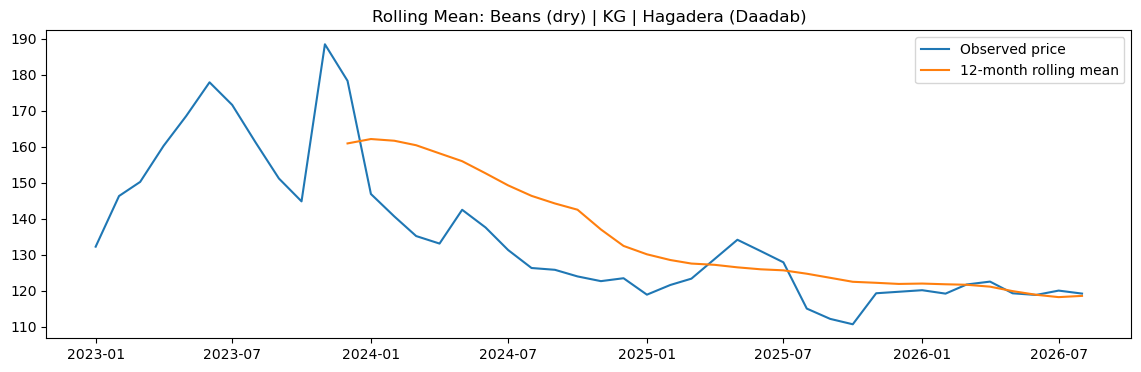

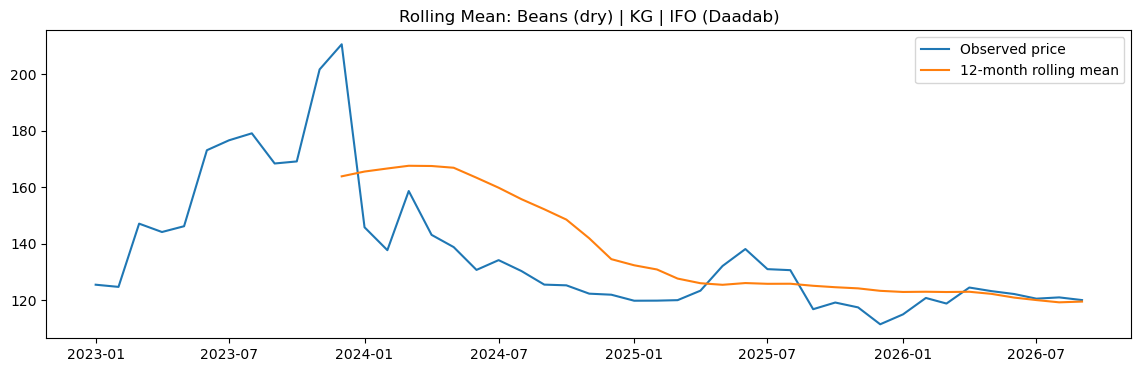

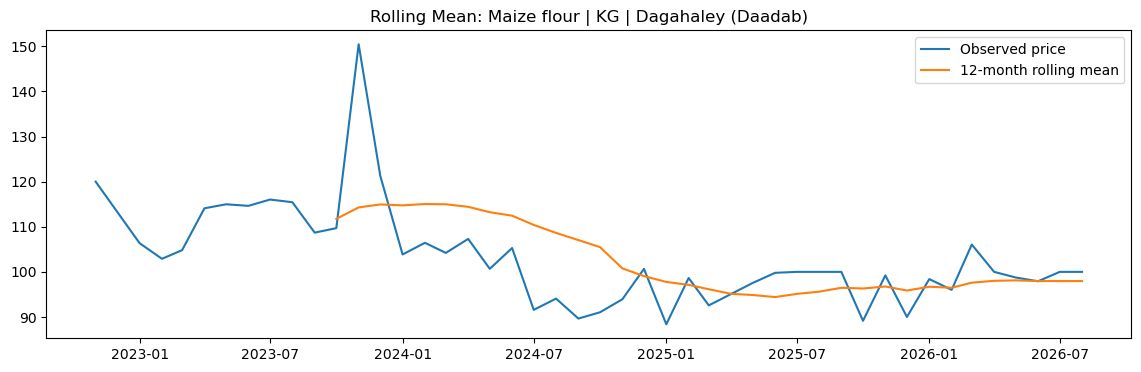

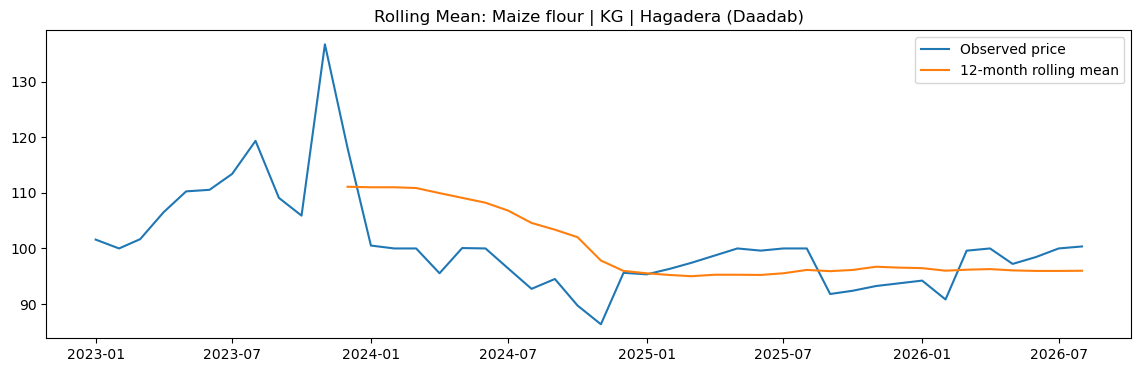

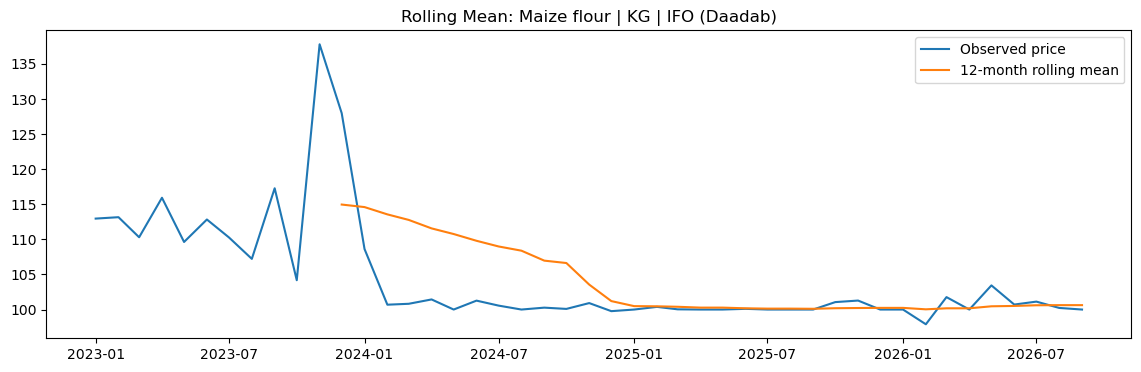

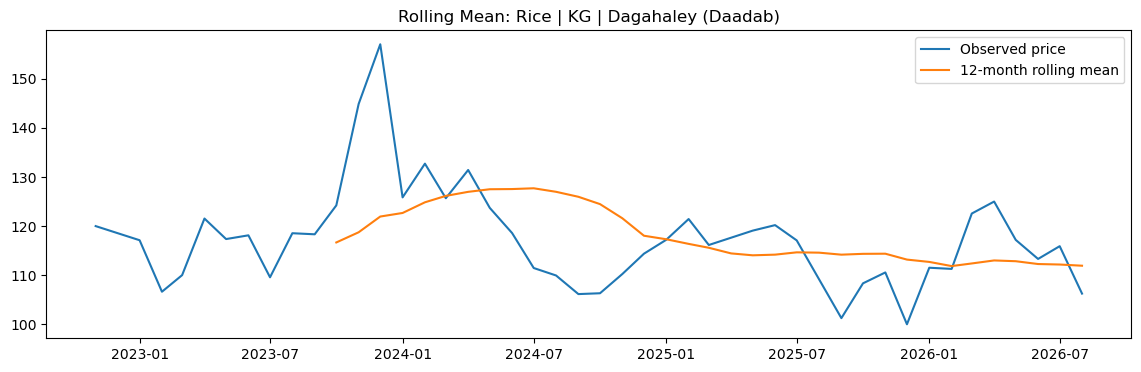

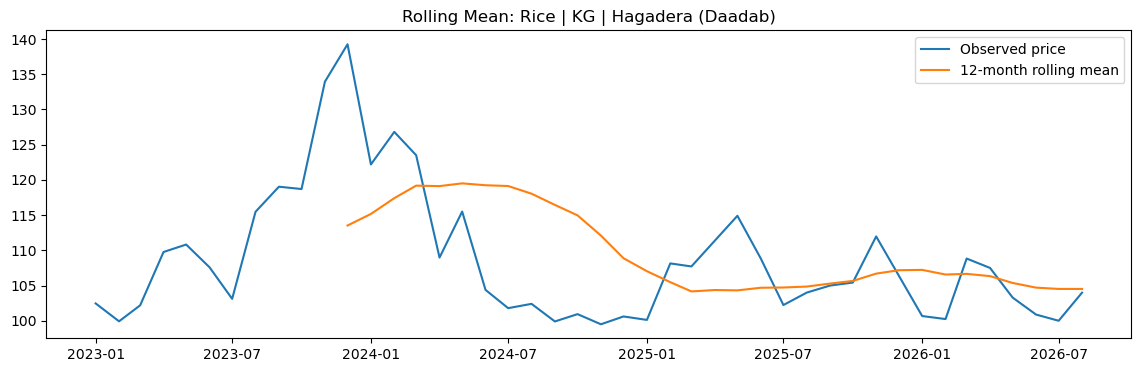

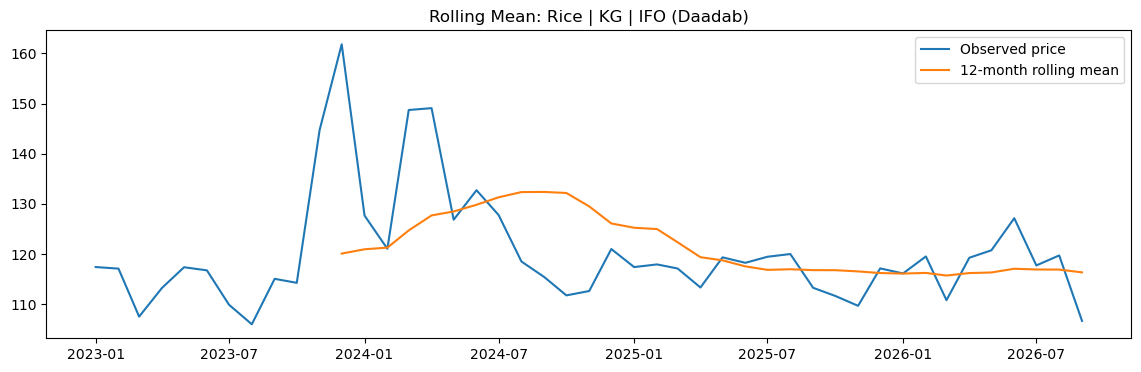

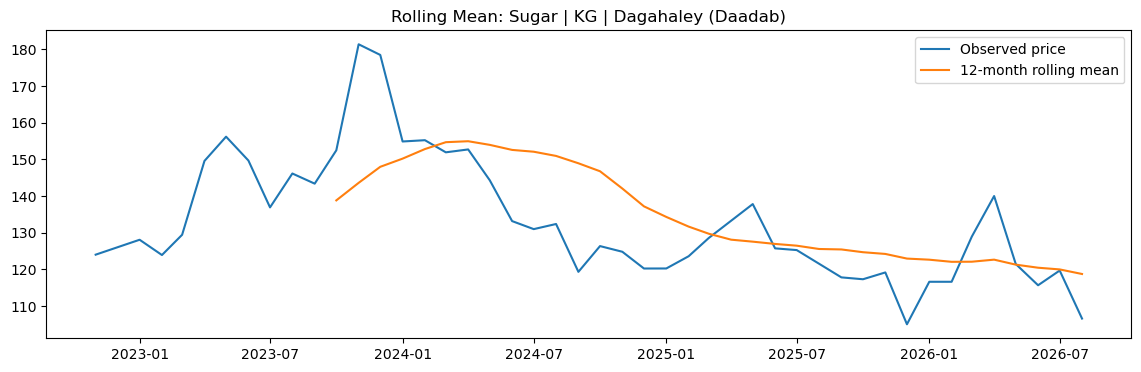

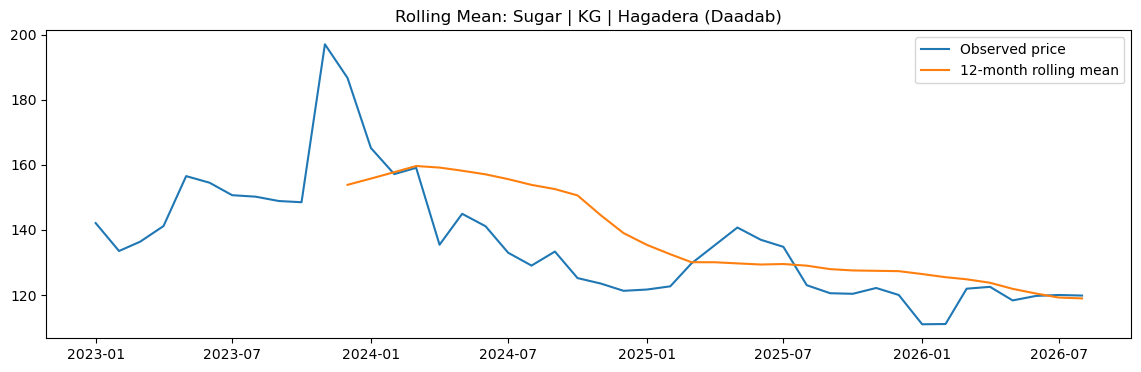

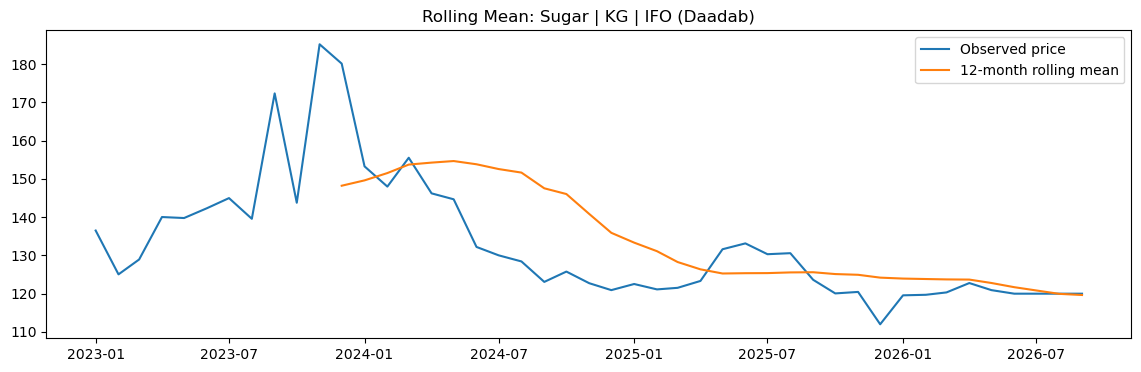

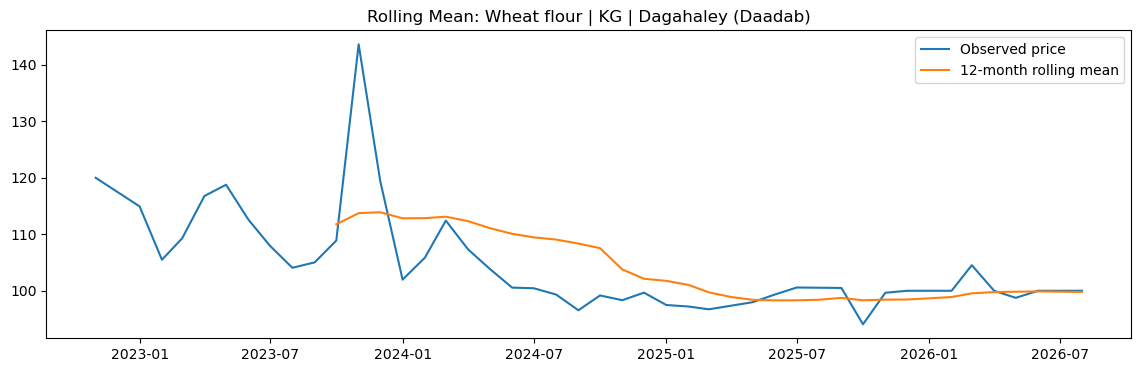

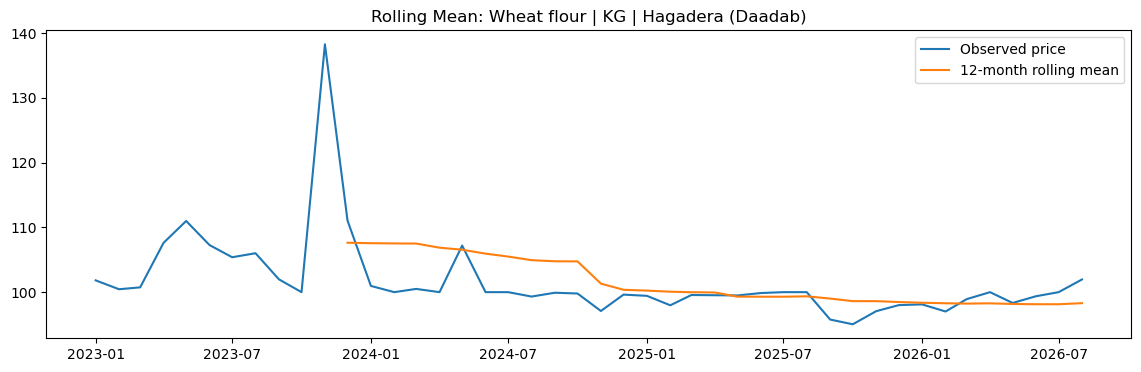

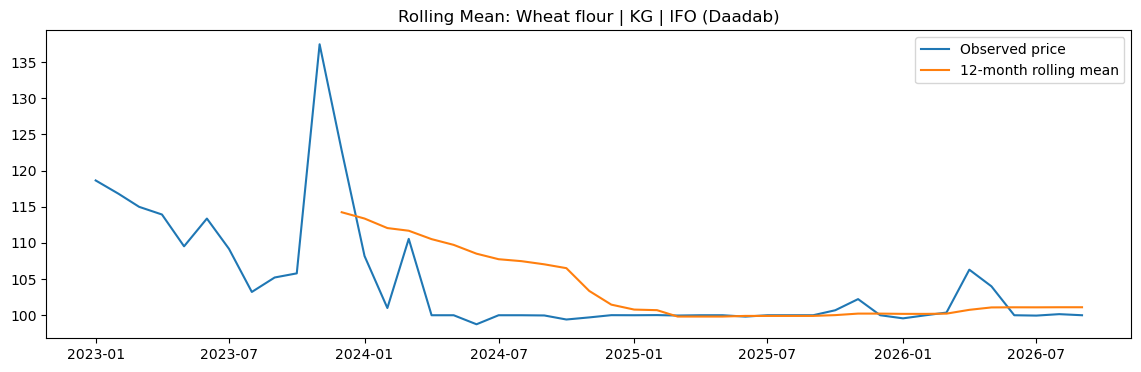

In [40]:
# rollling average
for column in monthly_clean.columns:
    series = monthly_clean[column].dropna()

    rolling_mean = series.rolling(12).mean()

    plt.figure(figsize=(14, 4))

    plt.plot(series, label="Observed price")
    plt.plot(rolling_mean, label="12-month rolling mean")

    plt.title(f"Rolling Mean: {column}")
    plt.legend()
    plt.show()

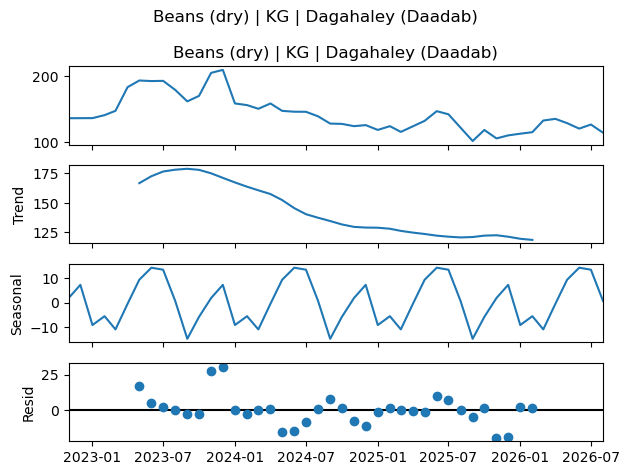

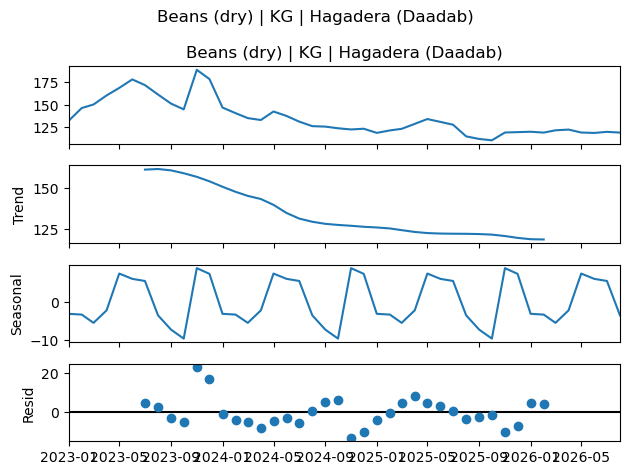

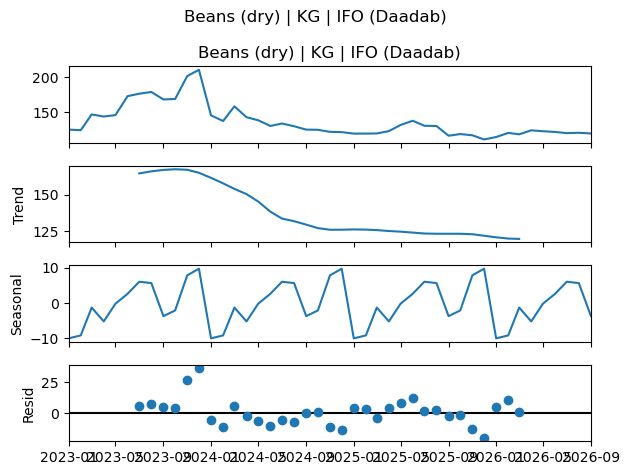

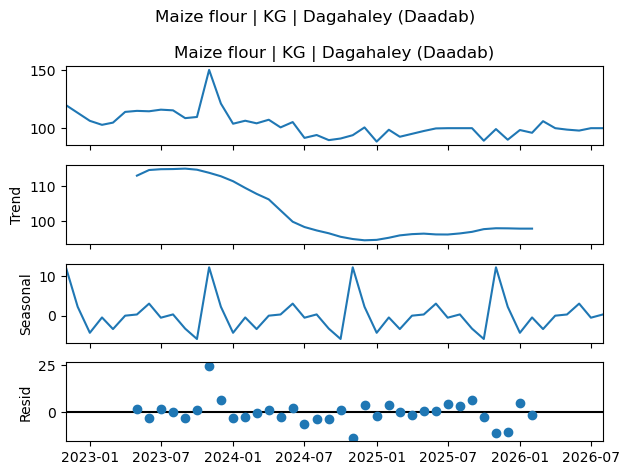

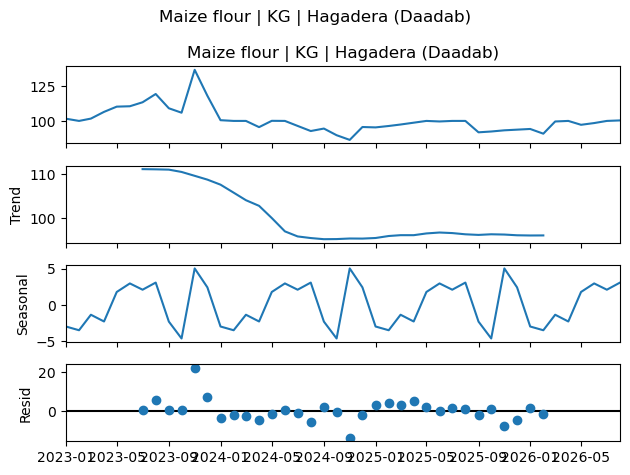

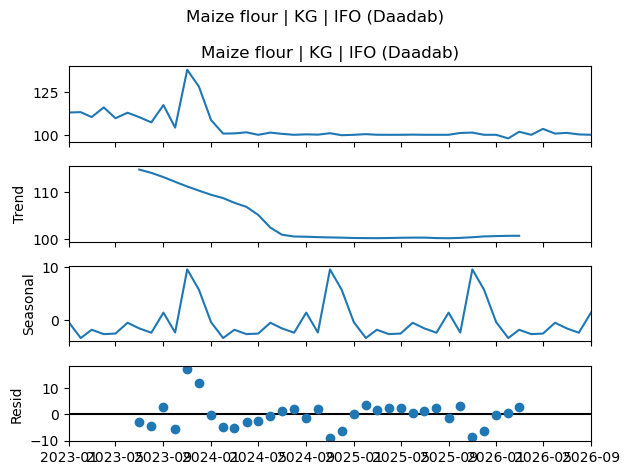

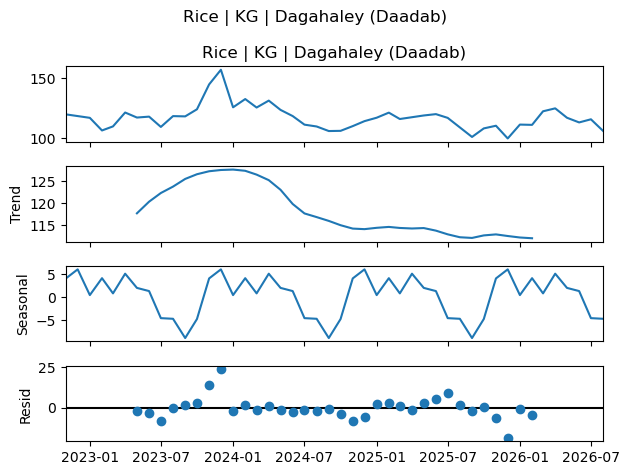

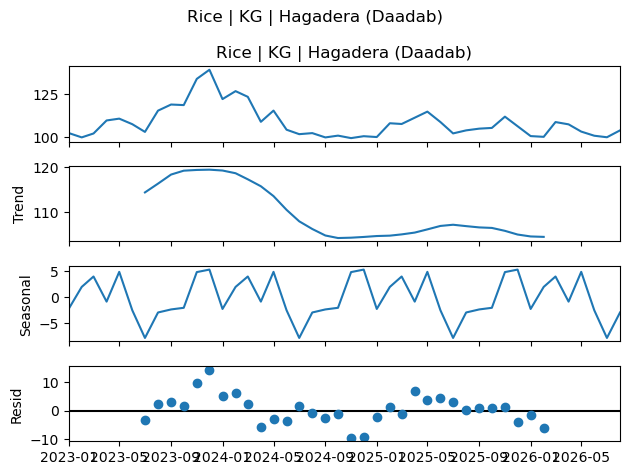

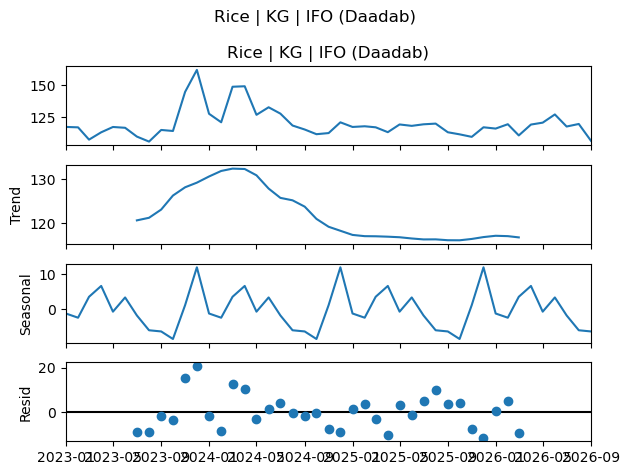

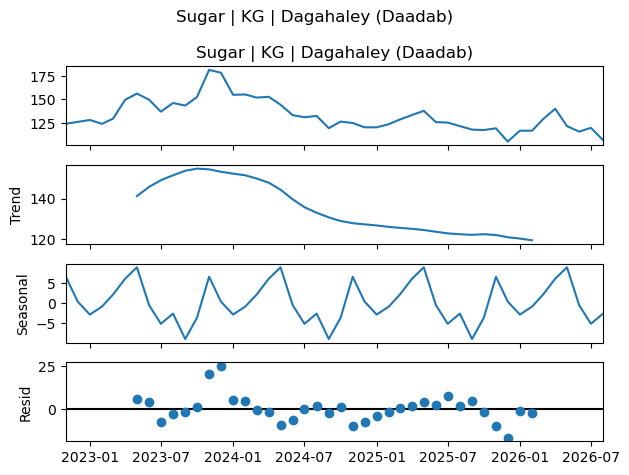

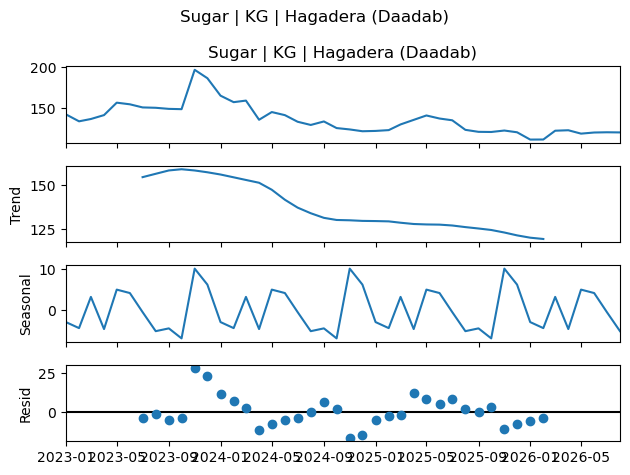

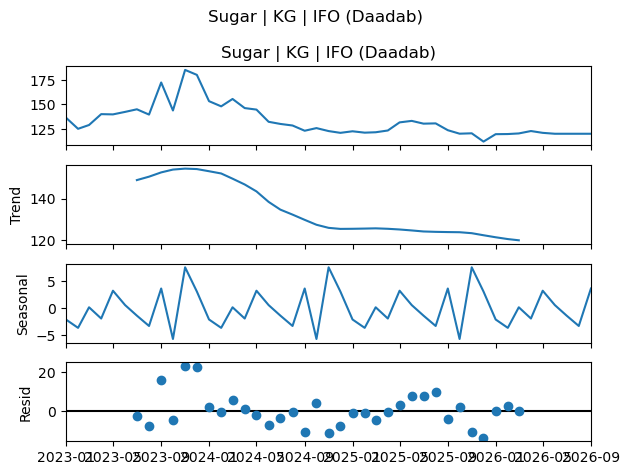

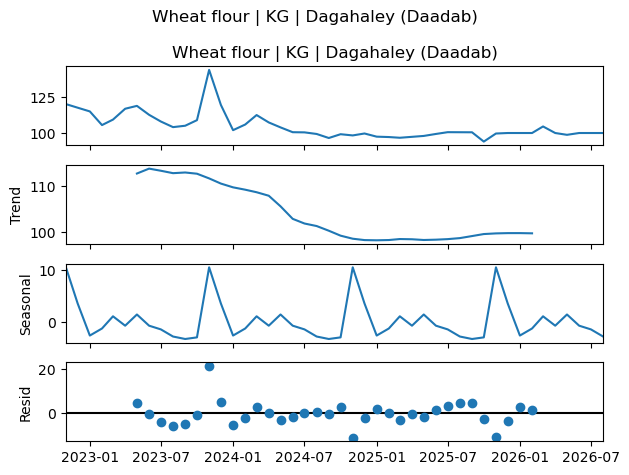

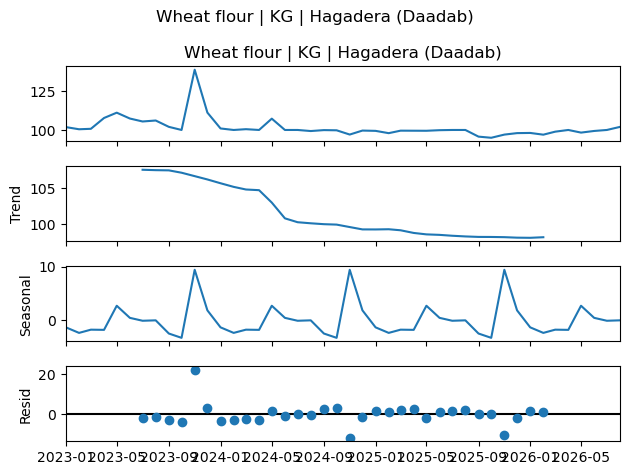

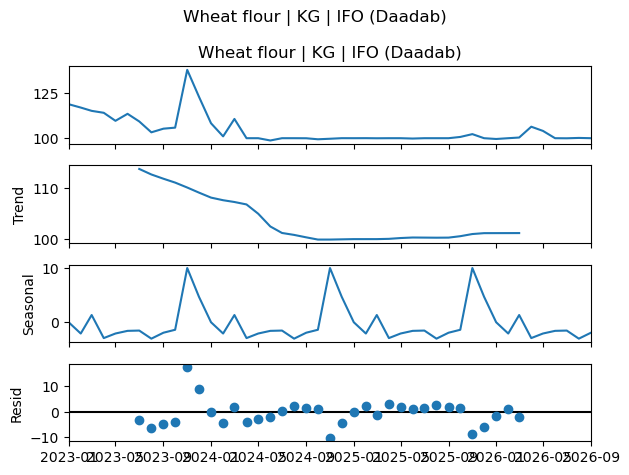

In [41]:
# seasonal decomposition
for column in monthly_clean.columns:
    series = monthly_clean[column].dropna()

    if len(series) >= 36:
        decomposition = seasonal_decompose(
            series,
            model="additive",
            period=12
        )

        decomposition.plot()
        plt.suptitle(column)
        plt.tight_layout()
        plt.show()

In [42]:
# ADF stationarity tests
adf_results = []

for column in monthly_clean.columns:
    series = monthly_clean[column].dropna()

    if len(series) >= 20:
        result = run_adf(series, column)

        if result is not None:
            adf_results.append({
                "Series": column,
                "ADF Statistic": result[0],
                "P-value": result[1],
                "Stationary at 5%": result[1] < 0.05
            })

adf_results_df = pd.DataFrame(adf_results)

display(adf_results_df)


Beans (dry) | KG | Dagahaley (Daadab)
ADF statistic: -1.087323522296259
P-value: 0.7201005728618621
Critical values: {'1%': np.float64(-3.596635636000432), '5%': np.float64(-2.933297331821618), '10%': np.float64(-2.6049909750566895)}
Fail to reject H0: evidence of non-stationarity is insufficient.

Beans (dry) | KG | Hagadera (Daadab)
ADF statistic: -1.078713049834642
P-value: 0.7234858184661765
Critical values: {'1%': np.float64(-3.610399601308181), '5%': np.float64(-2.939108945868946), '10%': np.float64(-2.6080629651545038)}
Fail to reject H0: evidence of non-stationarity is insufficient.

Beans (dry) | KG | IFO (Daadab)
ADF statistic: -1.0688981754818956
P-value: 0.727314290577431
Critical values: {'1%': np.float64(-3.596635636000432), '5%': np.float64(-2.933297331821618), '10%': np.float64(-2.6049909750566895)}
Fail to reject H0: evidence of non-stationarity is insufficient.

Maize flour | KG | Dagahaley (Daadab)
ADF statistic: -3.4917395453438975
P-value: 0.008201791702473177
Cri

,Series,ADF Statistic,P-value,Stationary at 5%
0,Beans (dry) | KG | Dagahaley (Daadab),-1.087324,7.201006e-01,False
1,Beans (dry) | KG | Hagadera (Daadab),-1.078713,7.234858e-01,False
2,Beans (dry) | KG | IFO (Daadab),-1.068898,7.273143e-01,False
3,Maize flour | KG | Dagahaley (Daadab),-3.491740,8.201792e-03,True
4,Maize flour | KG | Hagadera (Daadab),-1.477844,5.444419e-01,False
5,Maize flour | KG | IFO (Daadab),-2.151109,2.244659e-01,False
6,Rice | KG | Dagahaley (Daadab),-2.829078,5.423877e-02,False
7,Rice | KG | Hagadera (Daadab),-2.378078,1.480195e-01,False
8,Rice | KG | IFO (Daadab),-2.048740,2.656194e-01,False
9,Sugar | KG | Dagahaley (Daadab),-1.700938,4.306293e-01,False


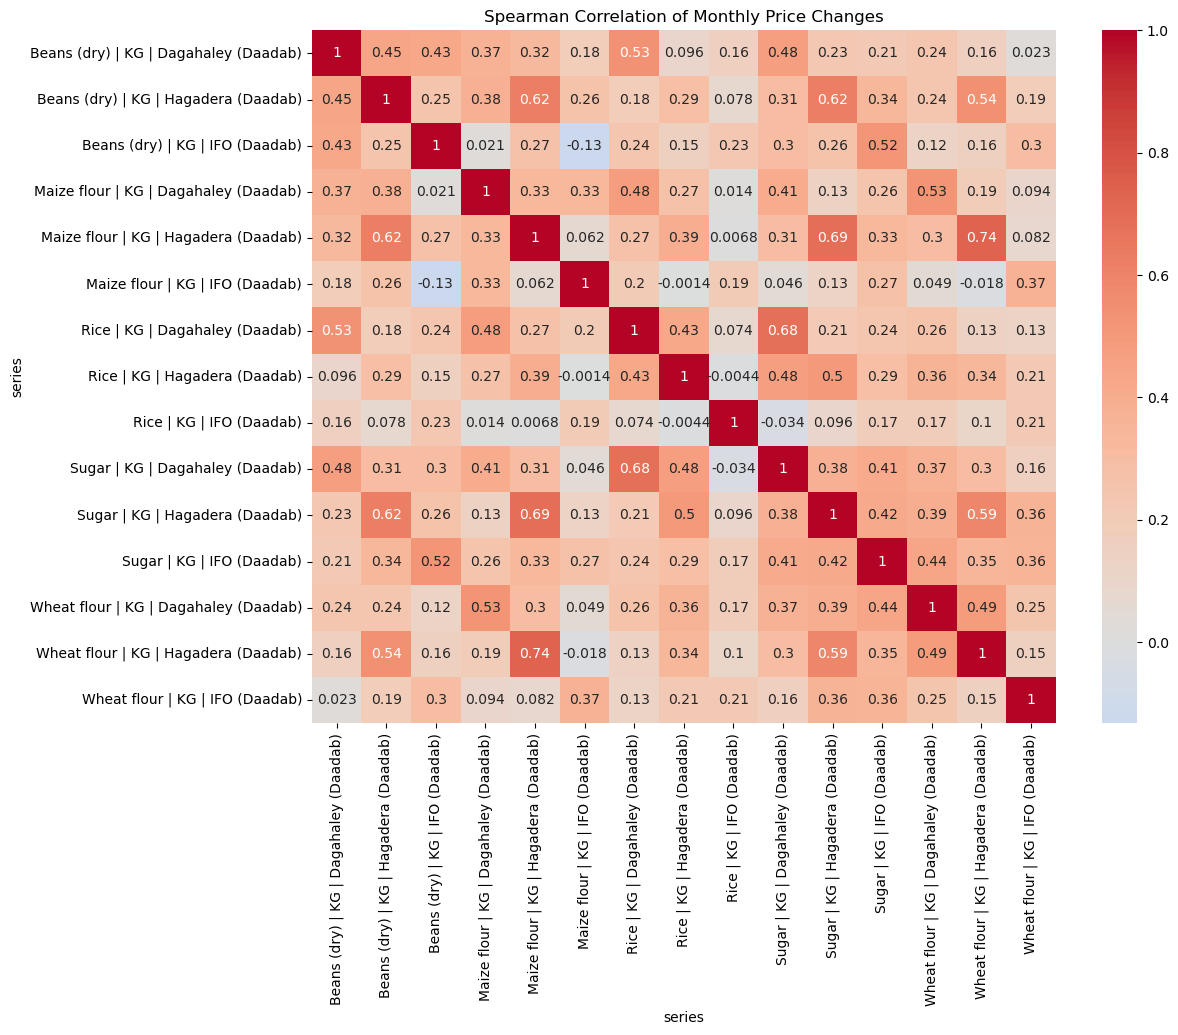

In [43]:
# Correlation between comparable price changes
change_corr = monthly_returns.corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(change_corr,annot=True,cmap="coolwarm",center=0)

plt.title("Spearman Correlation of Monthly Price Changes")
plt.show()

In [44]:
# FORECASTING 
# forecasting evaluation metrics
def calculate_forecast_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    nonzero = actual != 0

    if nonzero.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

In [45]:
# chronological forecasting splits
forecast_splits = {}

for column in monthly_clean.columns:
    series = monthly_clean[column].dropna().asfreq("MS")

    if len(series) < 36:
        print(f"Skipping {column}: insufficient observations.")
        continue

    split_index = int(len(series) * 0.8)

    train = series.iloc[:split_index]
    test = series.iloc[split_index:]

    if len(train) < 24 or len(test) < 6:
        print(f"Skipping {column}: insufficient train/test length.")
        continue

    forecast_splits[column] = {
        "train": train,
        "test": test
    }

    print(
        column,
        "| Train:", len(train),
        "| Test:", len(test),
        "| Train end:", train.index[-1],
        "| Test start:", test.index[0]
    )

Beans (dry) | KG | Dagahaley (Daadab) | Train: 36 | Test: 10 | Train end: 2025-10-01 00:00:00 | Test start: 2025-11-01 00:00:00
Beans (dry) | KG | Hagadera (Daadab) | Train: 35 | Test: 9 | Train end: 2025-11-01 00:00:00 | Test start: 2025-12-01 00:00:00
Beans (dry) | KG | IFO (Daadab) | Train: 36 | Test: 9 | Train end: 2025-12-01 00:00:00 | Test start: 2026-01-01 00:00:00
Maize flour | KG | Dagahaley (Daadab) | Train: 36 | Test: 10 | Train end: 2025-10-01 00:00:00 | Test start: 2025-11-01 00:00:00
Maize flour | KG | Hagadera (Daadab) | Train: 35 | Test: 9 | Train end: 2025-11-01 00:00:00 | Test start: 2025-12-01 00:00:00
Maize flour | KG | IFO (Daadab) | Train: 36 | Test: 9 | Train end: 2025-12-01 00:00:00 | Test start: 2026-01-01 00:00:00
Rice | KG | Dagahaley (Daadab) | Train: 36 | Test: 10 | Train end: 2025-10-01 00:00:00 | Test start: 2025-11-01 00:00:00
Rice | KG | Hagadera (Daadab) | Train: 35 | Test: 9 | Train end: 2025-11-01 00:00:00 | Test start: 2025-12-01 00:00:00
Rice | KG 

In [46]:
# Naïve forecasting baseline
forecast_results = []

for column, split in forecast_splits.items():
    train = split["train"]
    test = split["test"]

    predictions = np.repeat(train.iloc[-1], len(test))

    metrics = calculate_forecast_metrics(
        test,
        predictions
    )

    forecast_results.append({
        "Series": column,
        "Model": "Naive",
        **metrics
    })

In [47]:
# Holt-Winters forecasting
for column, split in forecast_splits.items():
    train = split["train"]
    test = split["test"]

    try:
        model = ExponentialSmoothing(train,trend="add",seasonal="add",seasonal_periods=12,initialization_method="estimated")

        fitted_model = model.fit(optimized=True)

        predictions = fitted_model.forecast(len(test))

        metrics = calculate_forecast_metrics(test,predictions)

        forecast_results.append({
            "Series": column,
            "Model": "Holt-Winters",
            **metrics
        })

    except Exception as error:
        print(f"Holt-Winters failed for {column}: {error}")

In [48]:
# ARIMA forecasting
for column, split in forecast_splits.items():
    train = split["train"]
    test = split["test"]

    try:
        model = ARIMA(train,order=(1, 1, 1))

        fitted_model = model.fit()

        predictions = fitted_model.forecast(steps=len(test))

        metrics = calculate_forecast_metrics(test,predictions)

        forecast_results.append({
            "Series": column,
            "Model": "ARIMA(1,1,1)",
            **metrics
        })

    except Exception as error:
        print(f"ARIMA failed for {column}: {error}")

In [50]:
# SARIMA forecasting
for column, split in forecast_splits.items():
    train = split["train"]
    test = split["test"]

    try:
        model = ARIMA(train,order=(1, 1, 1),seasonal_order=(1, 1, 1, 12))

        fitted_model = model.fit()

        predictions = fitted_model.forecast(steps=len(test))

        metrics = calculate_forecast_metrics(test,predictions)

        forecast_results.append({
            "Series": column,
            "Model": "SARIMA(1,1,1)(1,1,1,12)",
            **metrics
        })

    except Exception as error:
        print(f"SARIMA failed for {column}: {error}")

In [51]:
# forecasting models
forecast_results_df = pd.DataFrame(forecast_results)

display(forecast_results_df.sort_values(
        ["Series", "RMSE"]
    )
)

,Series,Model,MAE,RMSE,MAPE
0,Beans (dry) | KG | Dagahaley (Daadab),Naive,8.583000,9.783075,7.062341
30,Beans (dry) | KG | Dagahaley (Daadab),"ARIMA(1,1,1)",9.074495,10.033693,7.729824
15,Beans (dry) | KG | Dagahaley (Daadab),Holt-Winters,13.193580,15.938431,11.373140
45,Beans (dry) | KG | Dagahaley (Daadab),"SARIMA(1,1,1)(1,1,1,12)",11.903488,20.512018,10.643547
60,Beans (dry) | KG | Dagahaley (Daadab),"SARIMA(1,1,1)(1,1,1,12)",11.903488,20.512018,10.643547
...,...,...,...,...,...
44,Wheat flour | KG | IFO (Daadab),"ARIMA(1,1,1)",1.366868,2.313150,1.313530
14,Wheat flour | KG | IFO (Daadab),Naive,1.255556,2.495258,1.197008
59,Wheat flour | KG | IFO (Daadab),"SARIMA(1,1,1)(1,1,1,12)",10.470763,11.039399,10.295700
74,Wheat flour | KG | IFO (Daadab),"SARIMA(1,1,1)(1,1,1,12)",10.470763,11.039399,10.295700


In [52]:
best_forecast_models = (forecast_results_df.sort_values("RMSE").groupby("Series").first().reset_index())

display(best_forecast_models)

,Series,Model,MAE,RMSE,MAPE
0,Beans (dry) | KG | Dagahaley (Daadab),Naive,8.583000,9.783075,7.062341
1,Beans (dry) | KG | Hagadera (Daadab),Naive,0.928670,1.419513,0.765218
2,Beans (dry) | KG | IFO (Daadab),"ARIMA(1,1,1)",6.207134,6.664503,5.105816
3,Maize flour | KG | Dagahaley (Daadab),"ARIMA(1,1,1)",4.519148,5.150760,4.534458
4,Maize flour | KG | Hagadera (Daadab),"ARIMA(1,1,1)",3.324772,3.757283,3.390703
5,Maize flour | KG | IFO (Daadab),"ARIMA(1,1,1)",1.016964,1.422240,1.007764
6,Rice | KG | Dagahaley (Daadab),"ARIMA(1,1,1)",5.251013,6.743802,4.751638
7,Rice | KG | Hagadera (Daadab),Holt-Winters,4.436415,5.726490,4.320965
8,Rice | KG | IFO (Daadab),Naive,4.344444,5.588003,3.743017
9,Sugar | KG | Dagahaley (Daadab),Naive,6.879000,9.733102,5.660143


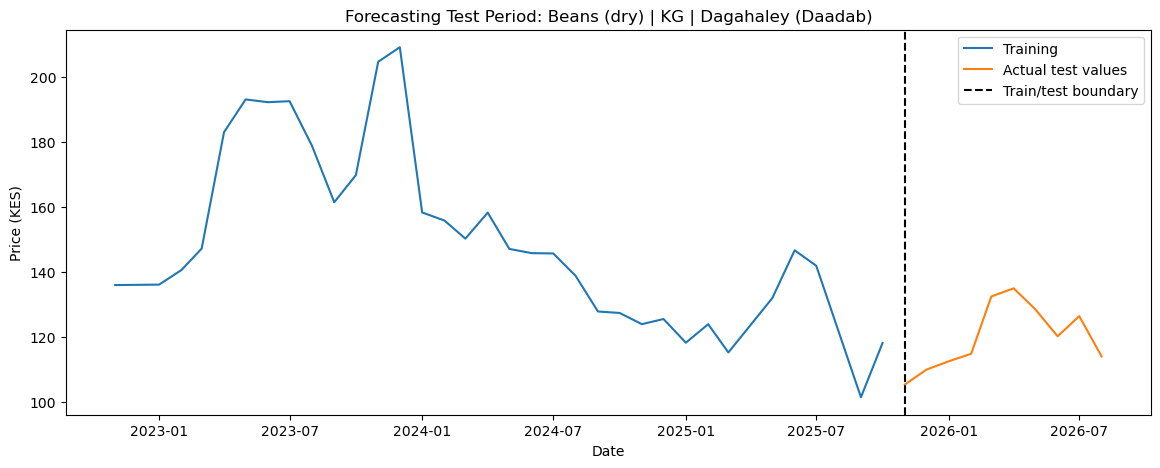

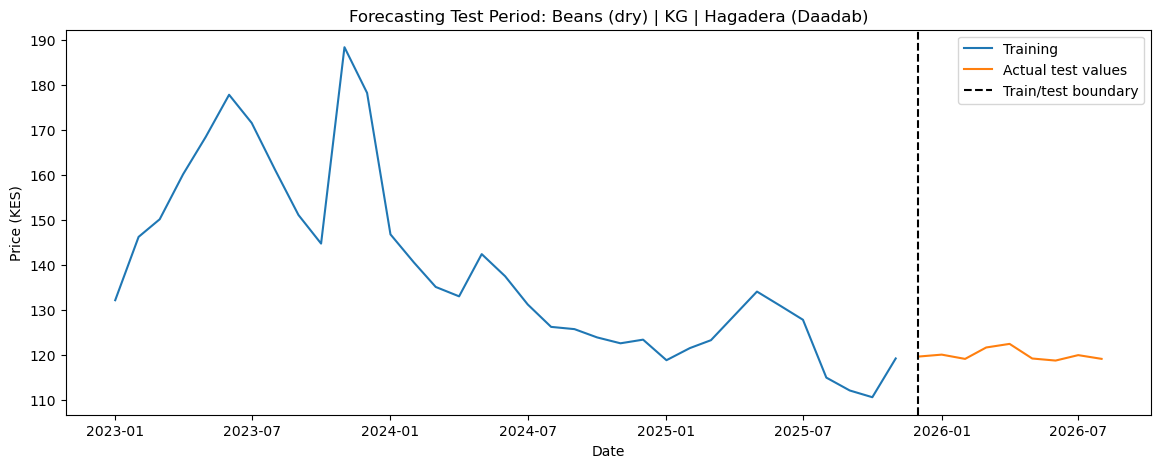

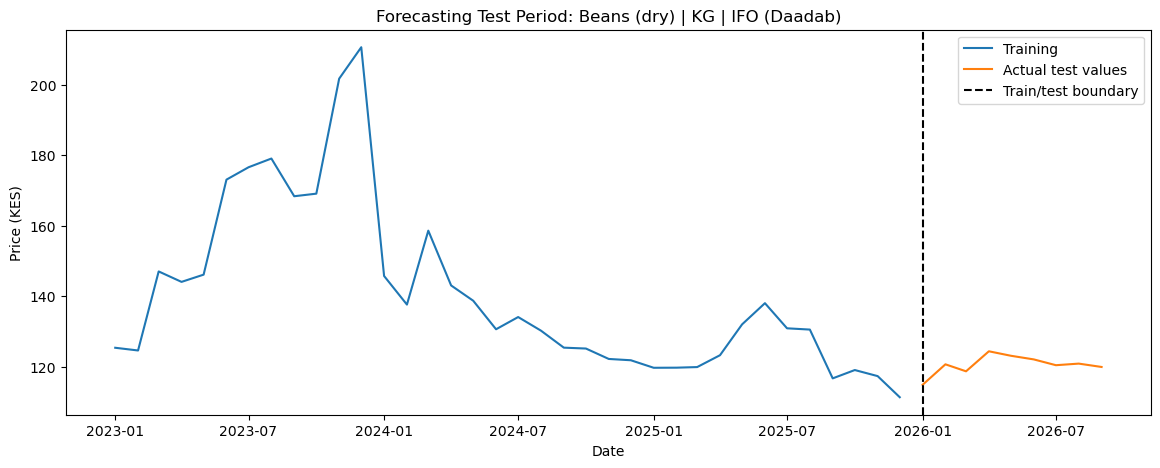

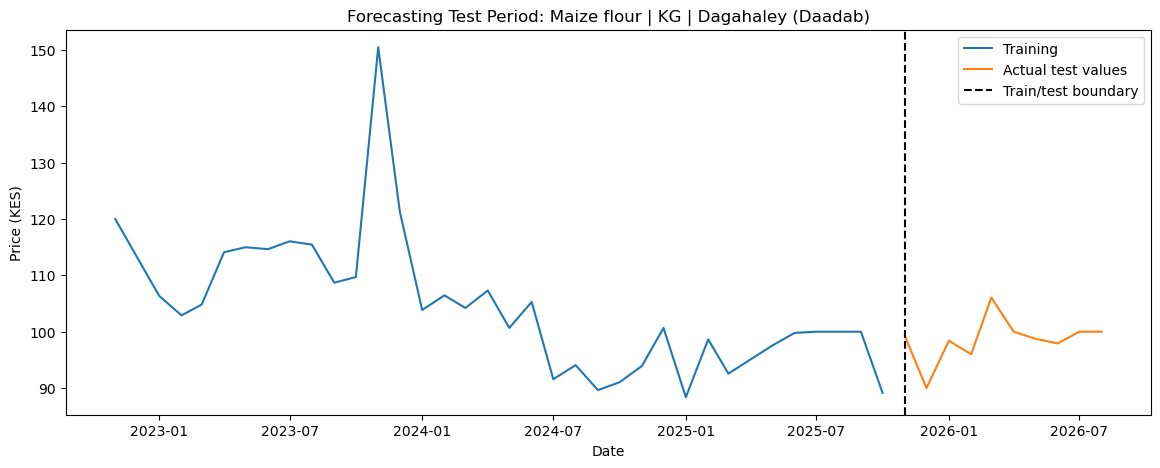

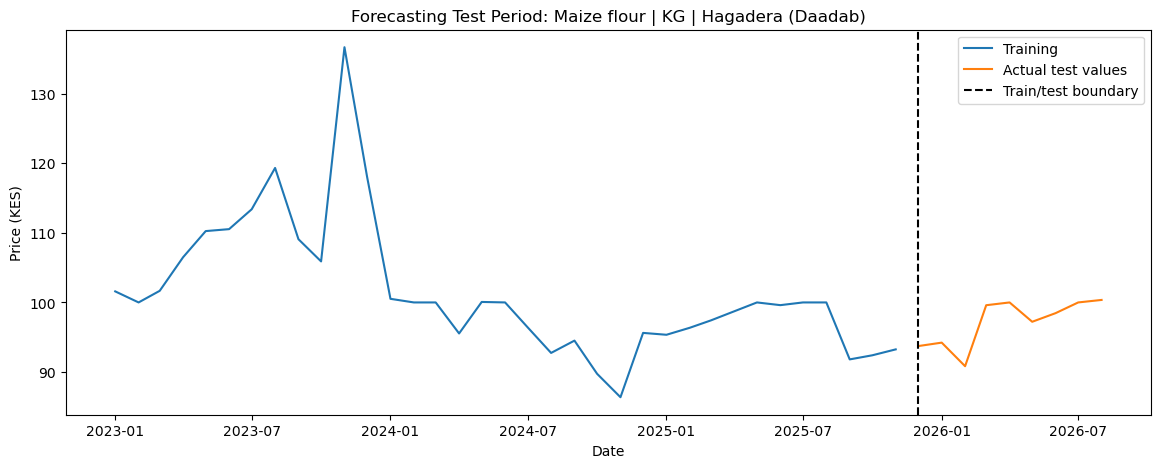

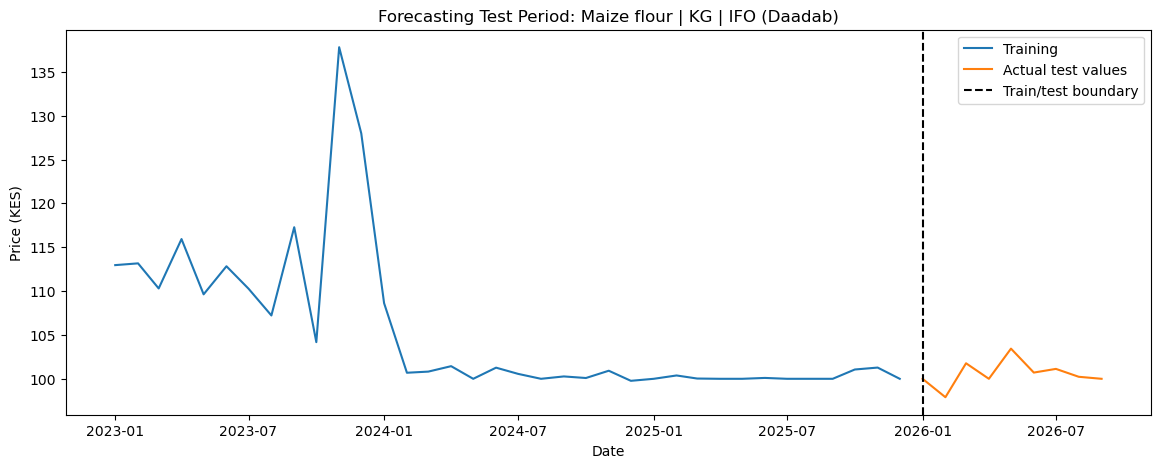

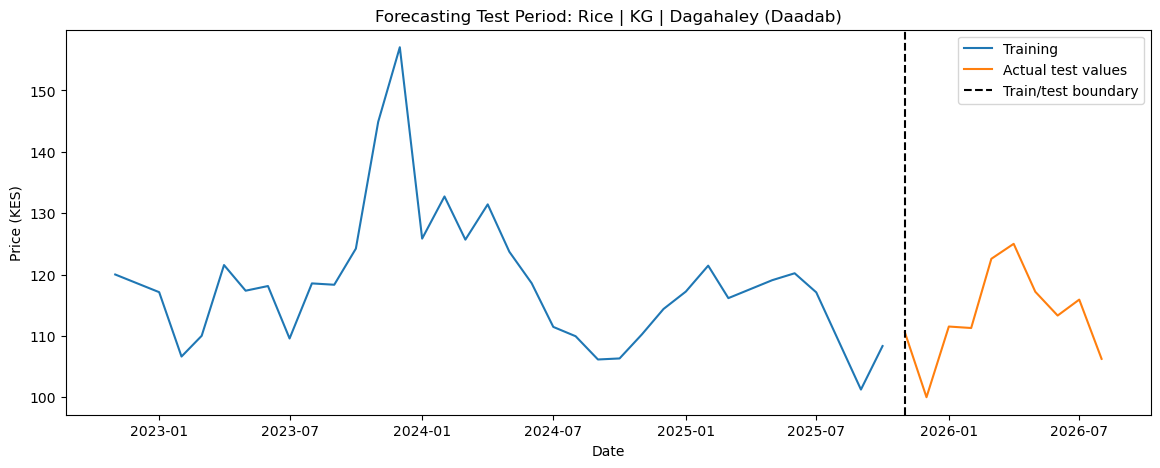

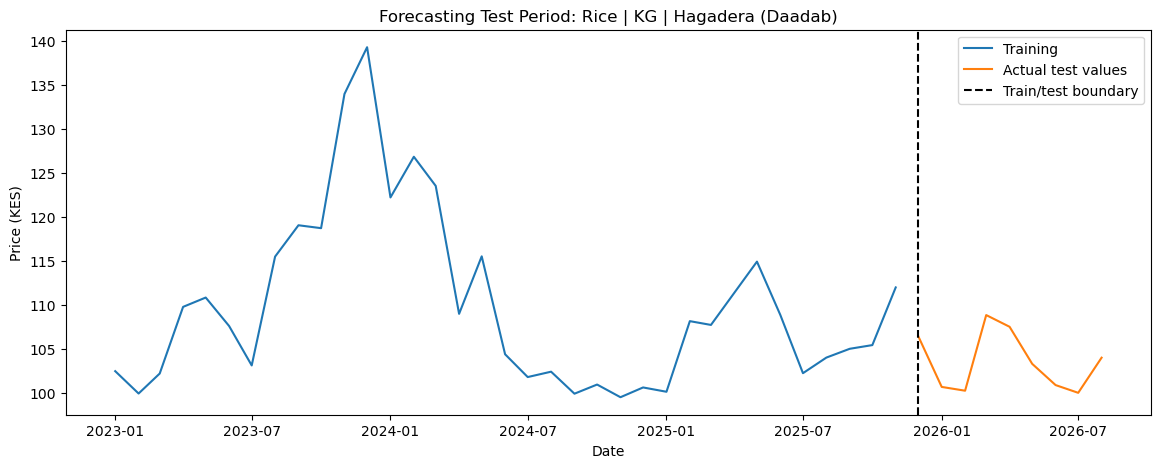

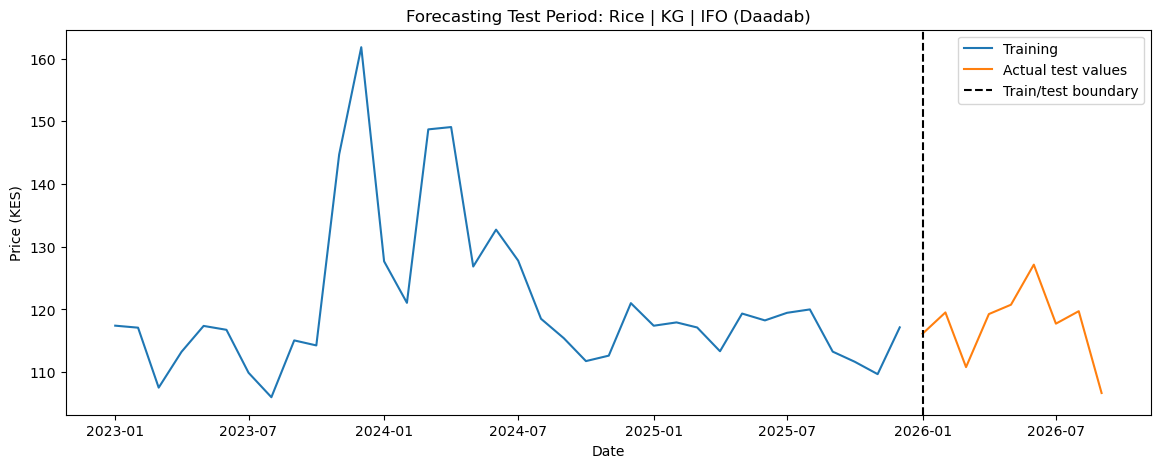

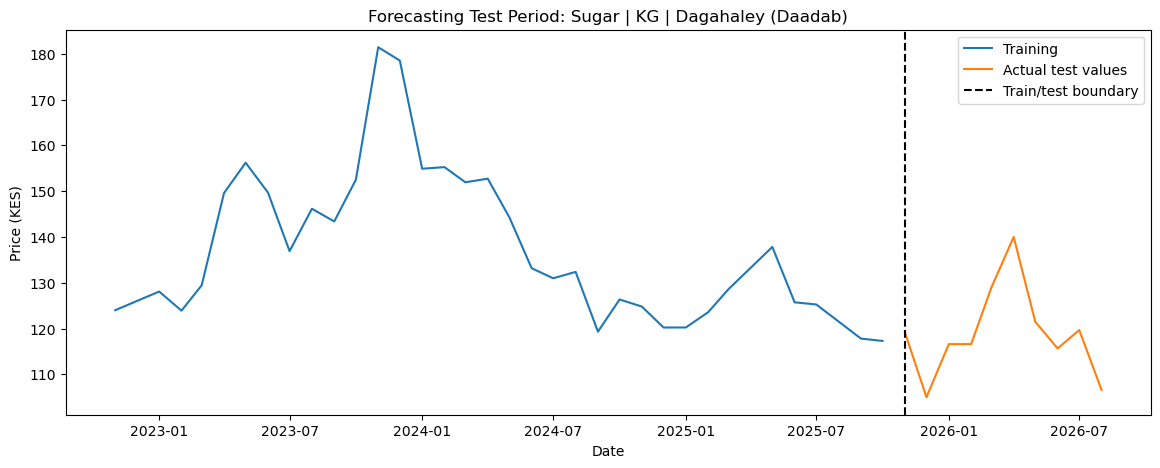

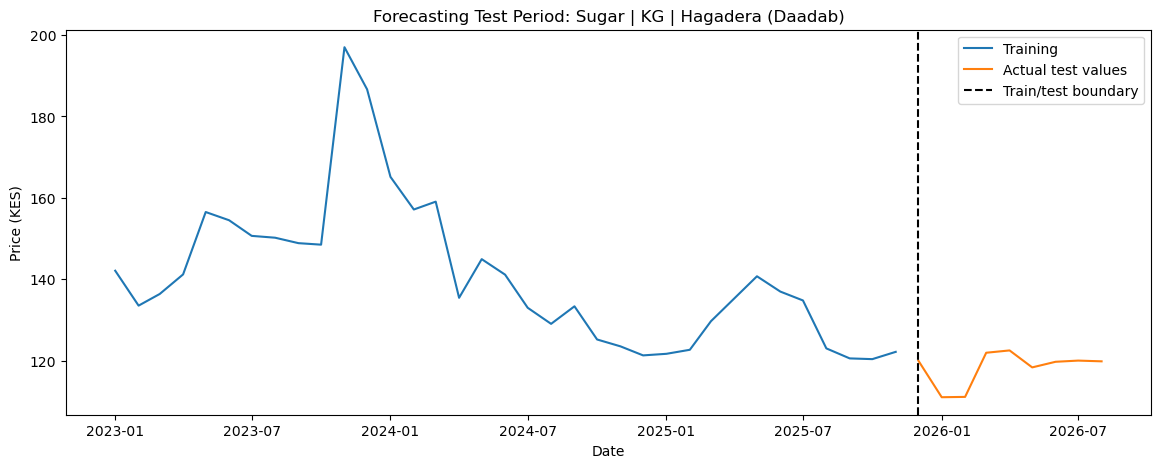

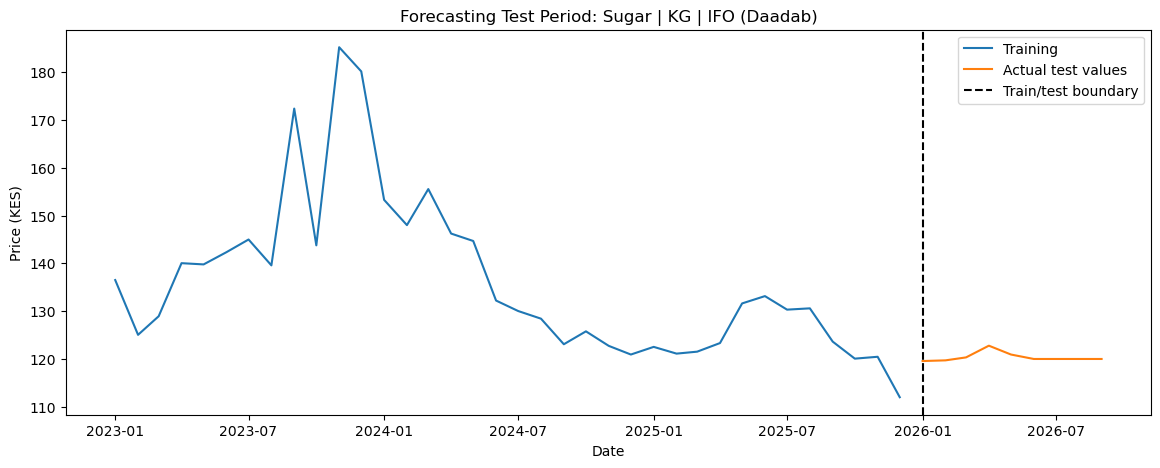

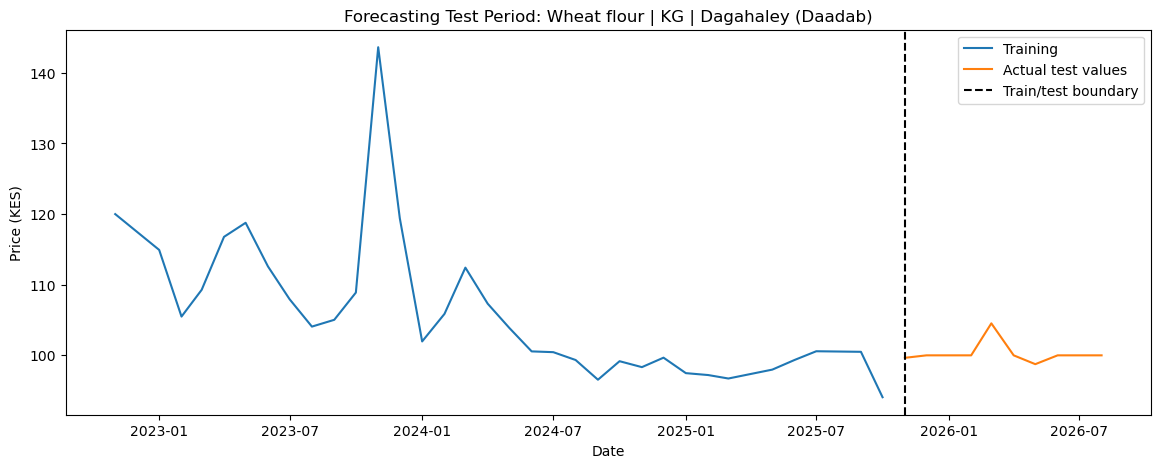

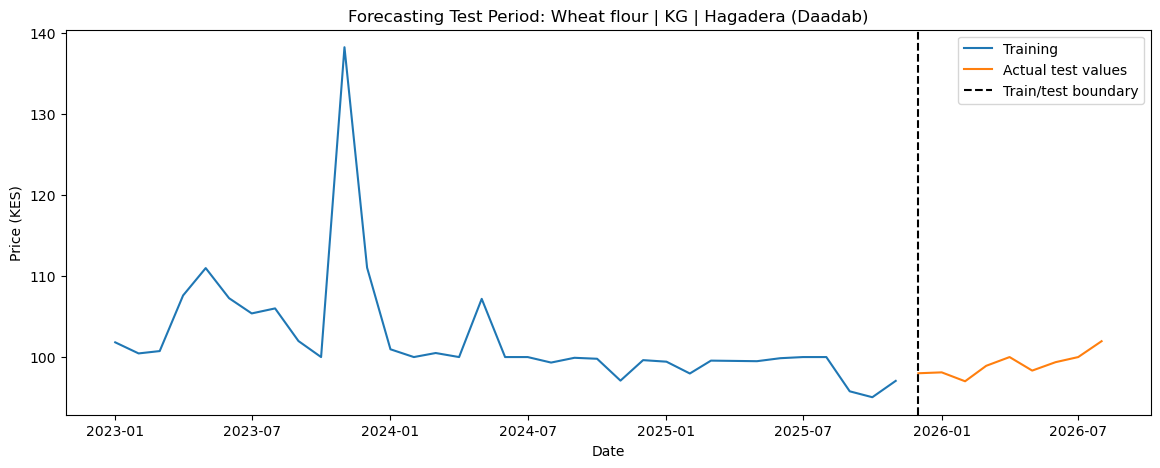

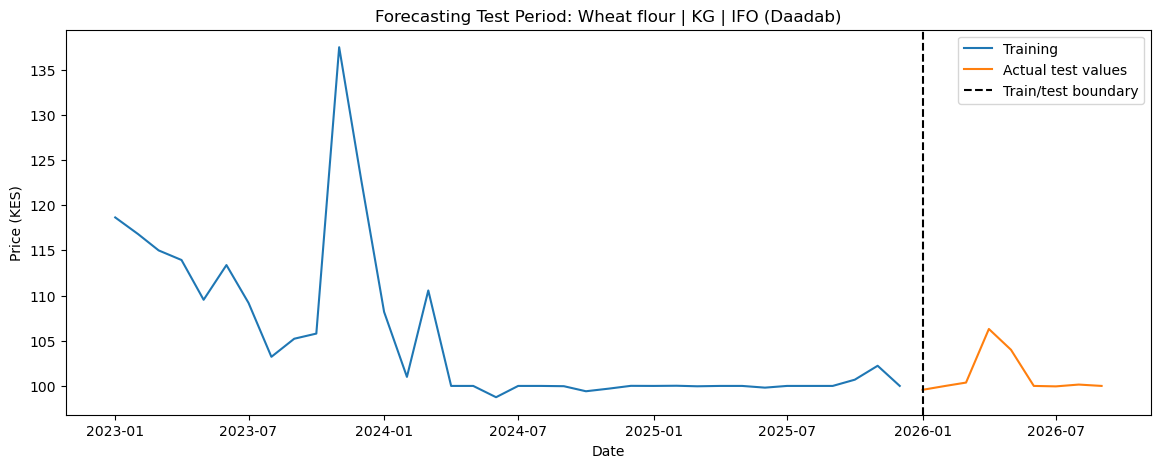

In [53]:
for column, split in forecast_splits.items():
    train = split["train"]
    test = split["test"]

    plt.figure(figsize=(14, 5))

    plt.plot(train.index, train, label="Training")
    plt.plot(test.index, test, label="Actual test values")

    plt.axvline(test.index[0],color="black",linestyle="--",label="Train/test boundary")

    plt.title(f"Forecasting Test Period: {column}")
    plt.xlabel("Date")
    plt.ylabel("Price (KES)")
    plt.legend()
    plt.show()

In [54]:
# MACHINE LEARNING DATASET AND FEATURES 
# Pooled monthly series from every era: more examples for the ML models than the recent staples alone
pool_cov = food_df.groupby(series_keys)["month"].nunique().reset_index(name="observations")
pool_keys = pool_cov[pool_cov["observations"] >= 48][series_keys]

pool_monthly = (
    food_df.merge(pool_keys, on=series_keys)
    .groupby(["month"] + series_keys)["price"]
    .median()
    .reset_index()
)
pool_monthly["series"] = (
    pool_monthly["commodity"] + " | " + pool_monthly["unit"] + " | " + pool_monthly["market"]
)

monthly_pool = (
    pool_monthly.pivot(index="month", columns="series", values="price")
    .sort_index()
    .asfreq("MS")
    .apply(latest_unbroken_run)
)
monthly_pool = monthly_pool.loc[:, monthly_pool.notna().sum() >= 36]
print("Pooled monthly series:", monthly_pool.shape[1], "| months:", monthly_pool.shape[0])

Pooled monthly series: 99 | months: 249


In [55]:
# Long format on a complete monthly grid (missing months stay NaN, so lags never jump across gaps)
ml_df = (monthly_pool.reset_index().melt(id_vars="month", var_name="series", value_name="price").sort_values(["series", "month"]).reset_index(drop=True))

parts = ml_df["series"].str.split(" | ", regex=False)
ml_df["commodity"] = parts.str[0]
ml_df["unit"] = parts.str[1]
ml_df["market"] = parts.str[2]

print("Shape:", ml_df.shape, "| series:", ml_df["series"].nunique())
display(ml_df.dropna(subset=["price"]).head())

Shape: (24651, 6) | series: 99


,month,series,price,commodity,unit,market
202,2022-11-01,Bananas | Unit | Dagahaley (Daadab),10.0,Bananas,Unit,Dagahaley (Daadab)
203,2022-12-01,Bananas | Unit | Dagahaley (Daadab),10.0,Bananas,Unit,Dagahaley (Daadab)
204,2023-01-01,Bananas | Unit | Dagahaley (Daadab),10.0,Bananas,Unit,Dagahaley (Daadab)
205,2023-02-01,Bananas | Unit | Dagahaley (Daadab),10.0,Bananas,Unit,Dagahaley (Daadab)
206,2023-03-01,Bananas | Unit | Dagahaley (Daadab),10.0,Bananas,Unit,Dagahaley (Daadab)


In [56]:
# Return features (scale-free, so cheap and expensive foods are comparable)
ml_df["logp"] = np.log(ml_df["price"])
log_price = ml_df.groupby("series")["logp"]

ml_df["ret_0"] = log_price.diff(1)  # change into the current month: known today
ml_df["ret_lag1"] = ml_df.groupby("series")["ret_0"].shift(1)
ml_df["ret_lag2"] = ml_df.groupby("series")["ret_0"].shift(2)
ml_df["ret_3m"] = log_price.diff(3)
ml_df["ret_6m"] = log_price.diff(6)
ml_df["ret_12m"] = log_price.diff(12)

In [57]:
# Volatility and distance from the 12-month average
ml_df["vol_6m"] = ml_df.groupby("series")["ret_0"].transform(lambda x: x.rolling(6).std())
ml_df["dev_12m"] = ml_df["logp"] - ml_df.groupby("series")["logp"].transform(lambda x: x.rolling(12).mean())

In [58]:
# calendar features (no raw year: tree models cannot extrapolate it)
ml_df["month_number"] = ml_df["month"].dt.month

ml_df["month_sin"] = np.sin(2 * np.pi * ml_df["month_number"] / 12)

ml_df["month_cos"] = np.cos(2 * np.pi * ml_df["month_number"] / 12)

In [59]:
# targets: next month's price and the 6-month change
ml_df["target_price"] = (ml_df.groupby("series")["price"].shift(-1))

ml_df["target_month"] = (ml_df.groupby("series")["month"].shift(-1))

ml_df["target_change_pct"] = ((ml_df["target_price"] / ml_df["price"] - 1) * 100)

ml_df["target_change_6m_pct"] = ((ml_df.groupby("series")["price"].shift(-6) / ml_df["price"] - 1) * 100)

In [60]:
# classification labels
THRESHOLD = 3.0  # percent: moves smaller than this count as Stable

conditions = [
    ml_df["target_change_pct"] > THRESHOLD,
    ml_df["target_change_pct"] < -THRESHOLD
]

choices = ["Increase", "Decrease"]

ml_df["price_movement"] = np.select(
    conditions,
    choices,
    default="Stable"
)

ml_df.loc[
    ml_df["target_change_pct"].isna(),
    "price_movement"
] = np.nan

display(
    ml_df[
        ["series", "month", "price", "target_price",
         "target_change_pct", "price_movement"]
    ].head(15)
)

,series,month,price,target_price,target_change_pct,price_movement
0,Bananas | Unit | Dagahaley (Daadab),2006-01-01,NaN,NaN,NaN,NaN
1,Bananas | Unit | Dagahaley (Daadab),2006-02-01,NaN,NaN,NaN,NaN
2,Bananas | Unit | Dagahaley (Daadab),2006-03-01,NaN,NaN,NaN,NaN
3,Bananas | Unit | Dagahaley (Daadab),2006-04-01,NaN,NaN,NaN,NaN
4,Bananas | Unit | Dagahaley (Daadab),2006-05-01,NaN,NaN,NaN,NaN
5,Bananas | Unit | Dagahaley (Daadab),2006-06-01,NaN,NaN,NaN,NaN
6,Bananas | Unit | Dagahaley (Daadab),2006-07-01,NaN,NaN,NaN,NaN
7,Bananas | Unit | Dagahaley (Daadab),2006-08-01,NaN,NaN,NaN,NaN
8,Bananas | Unit | Dagahaley (Daadab),2006-09-01,NaN,NaN,NaN,NaN
9,Bananas | Unit | Dagahaley (Daadab),2006-10-01,NaN,NaN,NaN,NaN


price_movement
Stable      2665
Increase    1530
Decrease    1481
Name: count, dtype: int64

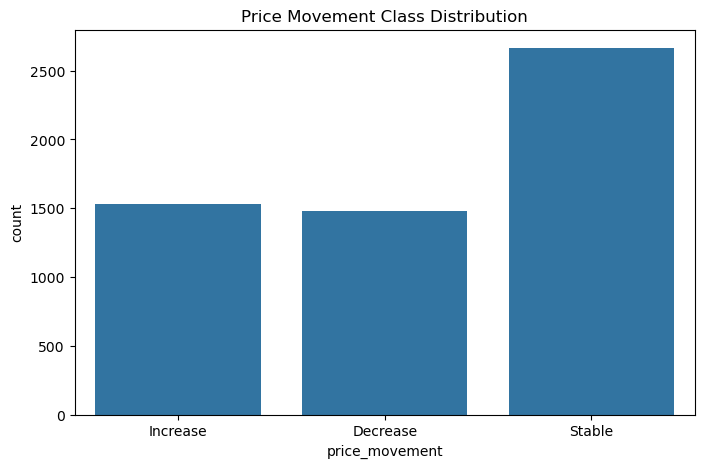

In [61]:
# classification imbalance
class_counts = ml_df["price_movement"].value_counts()

display(class_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=ml_df.dropna(subset=["price_movement"]),
    x="price_movement",
    order=["Increase", "Decrease", "Stable"]
)

plt.title("Price Movement Class Distribution")
plt.show()

In [62]:
# prepare modelling data
numeric_cls = [
    "ret_0", "ret_lag1", "ret_lag2", "ret_3m", "ret_6m", "ret_12m",
    "vol_6m", "dev_12m", "month_sin", "month_cos"
]
categorical_cls = ["commodity"]
feature_columns = categorical_cls + numeric_cls

regression_df = ml_df.dropna(
    subset=feature_columns + ["price", "target_price", "target_month"]
).copy()

classification_df = regression_df.dropna(
    subset=["price_movement"]
).copy()

print("Regression dataset:", regression_df.shape)
print("Classification dataset:", classification_df.shape)

Regression dataset: (4488, 23)
Classification dataset: (4488, 23)


In [63]:
# Preprocessing
numeric_features = numeric_cls + ["price"]  # the regression model also sees the current price
categorical_features = categorical_cls

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_reg = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

# the classifiers use only scale-free features
preprocessor_cls = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_cls),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

In [64]:
# Regression split by target month: train | validation (last-but-one 12 months) | final test (last 12 months)
last_target = regression_df["target_month"].max()
final_start = last_target - pd.DateOffset(months=12)
val_start = last_target - pd.DateOffset(months=24)

reg_train = regression_df[regression_df["target_month"] <= val_start].copy()
reg_val = regression_df[(regression_df["target_month"] > val_start) & (regression_df["target_month"] <= final_start)].copy()
reg_final = regression_df[regression_df["target_month"] > final_start].copy()

reg_features = feature_columns + ["price"]

X_train_reg, y_train_reg = reg_train[reg_features], reg_train["target_price"]
X_val_reg, y_val_reg = reg_val[reg_features], reg_val["target_price"]
X_final_reg, y_final_reg = reg_final[reg_features], reg_final["target_price"]

print("Train targets:     ", reg_train["target_month"].min().date(), "to", reg_train["target_month"].max().date(), len(reg_train))
print("Validation targets:", reg_val["target_month"].min().date(), "to", reg_val["target_month"].max().date(), len(reg_val))
print("FINAL test targets:", reg_final["target_month"].min().date(), "to", reg_final["target_month"].max().date(), len(reg_final), "(not used until the final-test section)")

Train targets:      2007-02-01 to 2024-09-01 2634
Validation targets: 2024-10-01 to 2025-09-01 960
FINAL test targets: 2025-10-01 to 2026-09-01 894 (not used until the final-test section)


In [65]:
# Classification split: same three periods
class_train = classification_df[classification_df["target_month"] <= val_start].copy()
class_val = classification_df[(classification_df["target_month"] > val_start) & (classification_df["target_month"] <= final_start)].copy()
class_final = classification_df[classification_df["target_month"] > final_start].copy()

X_train_class, y_train_class = class_train[feature_columns], class_train["price_movement"]
X_val_class, y_val_class = class_val[feature_columns], class_val["price_movement"]
X_final_class, y_final_class = class_final[feature_columns], class_final["price_movement"]

print("Training class distribution:")
print(y_train_class.value_counts())
print("\nValidation class distribution:")
print(y_val_class.value_counts())
print("\nFinal test class distribution (not used until the final-test section):")
print(y_final_class.value_counts())

Training class distribution:
price_movement
Stable      1253
Decrease     696
Increase     685
Name: count, dtype: int64

Validation class distribution:
price_movement
Stable      479
Increase    251
Decrease    230
Name: count, dtype: int64

Final test class distribution (not used until the final-test section):
price_movement
Stable      479
Decrease    208
Increase    207
Name: count, dtype: int64


In [66]:
# NEXT-MONTH PRICE REGRESSION (VALIDATION) 
# regression evaluation
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    nonzero = np.asarray(y_true) != 0

    if nonzero.any():
        mape = np.mean(
            np.abs(
                (
                    np.asarray(y_true)[nonzero]
                    - np.asarray(y_pred)[nonzero]
                ) / np.asarray(y_true)[nonzero]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2
    }

In [67]:
# regression models
regression_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state= 42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        random_state =42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        random_state= 42,
        n_jobs=-1
    )
}

In [68]:
# Model selection on the VALIDATION period (the final test is not touched here)
regression_results = []
trained_regression_models = {}

for name, model in regression_models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor_reg)),
        ("model", model)
    ])

    pipeline.fit(
        X_train_reg,
        y_train_reg
    )

    predictions = pipeline.predict(X_val_reg)

    metrics = regression_metrics(
        y_val_reg,
        predictions
    )

    regression_results.append({
        "Model": name,
        **metrics
    })

    trained_regression_models[name] = pipeline

regression_results_df = pd.DataFrame(
    regression_results
).sort_values("RMSE")

display(regression_results_df)

,Model,MAE,RMSE,MAPE,R2
0,Linear Regression,8.026007,14.607747,6.855580,0.990012
3,Extra Trees,9.324636,18.469700,6.930853,0.984033
2,Random Forest,9.208994,18.487699,6.710496,0.984002
1,Decision Tree,12.553292,26.026613,10.593571,0.968295


In [69]:
# XGBoost
try:
    from xgboost import XGBRegressor

    xgb_regression = Pipeline(steps=[
        ("preprocessor", clone(preprocessor_reg)),
        ("model", XGBRegressor(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state= 42,
            n_jobs=-1
        ))
    ])

    xgb_regression.fit(
        X_train_reg,
        y_train_reg
    )

    xgb_predictions = xgb_regression.predict(X_val_reg)

    xgb_metrics = regression_metrics(
        y_val_reg,
        xgb_predictions
    )

    regression_results.append({
        "Model": "XGBoost",
        **xgb_metrics
    })

    trained_regression_models["XGBoost"] = xgb_regression

    regression_results_df = pd.DataFrame(
        regression_results
    ).sort_values("RMSE")

    display(regression_results_df)

except ImportError:
    print("XGBoost is not installed. Skipping this model.")

,Model,MAE,RMSE,MAPE,R2
0,Linear Regression,8.026007,14.607747,6.855580,0.990012
3,Extra Trees,9.324636,18.469700,6.930853,0.984033
2,Random Forest,9.208994,18.487699,6.710496,0.984002
4,XGBoost,9.601518,18.830644,7.838744,0.983403
1,Decision Tree,12.553292,26.026613,10.593571,0.968295


In [70]:
# Naive baseline: next month's price = this month's price (any real model has to beat this)
naive_metrics = regression_metrics(y_val_reg, reg_val["price"].to_numpy())

regression_results_df = (
    pd.concat(
        [regression_results_df, pd.DataFrame([{"Model": "Naive (last price)", **naive_metrics}])],
        ignore_index=True
    )
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(regression_results_df)

,Model,MAE,RMSE,MAPE,R2
0,Linear Regression,8.026007,14.607747,6.855580,0.990012
1,Naive (last price),7.490521,14.935801,5.895724,0.989559
2,Extra Trees,9.324636,18.469700,6.930853,0.984033
3,Random Forest,9.208994,18.487699,6.710496,0.984002
4,XGBoost,9.601518,18.830644,7.838744,0.983403
5,Decision Tree,12.553292,26.026613,10.593571,0.968295


In [71]:
best_regression_name = (
    regression_results_df[
        regression_results_df["Model"].isin(trained_regression_models.keys())
    ].iloc[0]["Model"]
)

best_regression_model = (
    trained_regression_models[best_regression_name]
)

best_regression_predictions = best_regression_model.predict(
    X_val_reg
)

comparison = pd.DataFrame({
    "Actual Price": y_val_reg.values,
    "Predicted Price": best_regression_predictions
})

display(comparison.head(20))

,Actual Price,Predicted Price
0,10.0,9.579214
1,10.0,9.849790
2,10.0,10.124771
3,10.0,10.330476
4,10.0,10.411786
5,10.0,10.346914
6,10.0,10.153242
7,10.0,9.882666
8,10.0,9.607685
9,10.0,9.401980


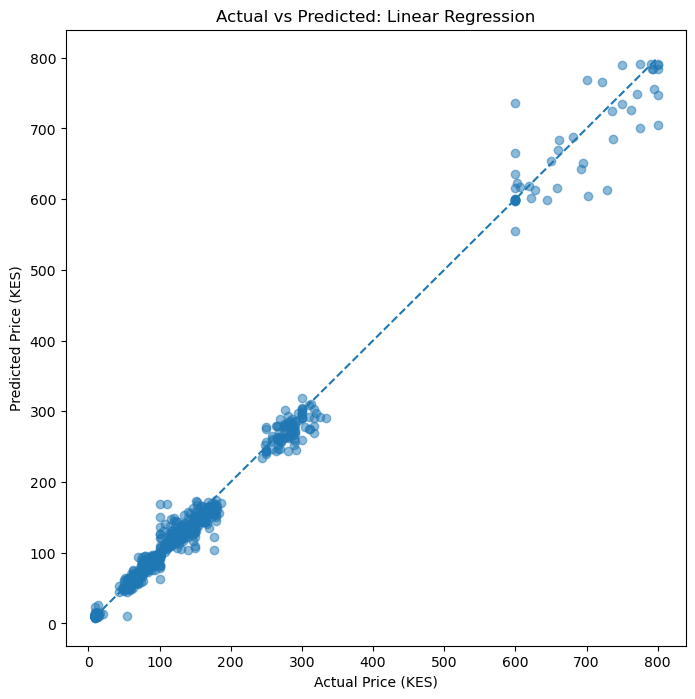

In [72]:
plt.figure(figsize=(8, 8))

plt.scatter(
    y_val_reg,
    best_regression_predictions,
    alpha=0.5
)

lower = min(
    y_val_reg.min(),
    best_regression_predictions.min()
)

upper = max(
    y_val_reg.max(),
    best_regression_predictions.max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual Price (KES)")
plt.ylabel("Predicted Price (KES)")
plt.title(f"Actual vs Predicted: {best_regression_name}")
plt.show()

In [73]:
# PRICE DIRECTION CLASSIFICATION (VALIDATION) ============
# classification evaluation
def evaluate_classifier(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }

In [101]:
# classification models (next-month direction: Decrease / Stable / Increase)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)

classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                                        class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=2,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, max_depth=10, min_samples_leaf=2,
                                        class_weight="balanced", random_state=42, n_jobs=-1),
}

In [102]:
classification_results = []
trained_classification_models = {}

for name, model in classification_models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor_cls)),
        ("model", model)
    ])

    pipeline.fit(
        X_train_class,
        y_train_class
    )

    predictions = pipeline.predict(X_val_class)

    metrics = evaluate_classifier(
        y_val_class,
        predictions
    )

    classification_results.append({
        "Model": name,
        **metrics
    })

    trained_classification_models[name] = pipeline

classification_results_df = pd.DataFrame(
    classification_results
).sort_values("F1", ascending=False)

display(classification_results_df)

,Model,Accuracy,Precision,Recall,F1
3,Random Forest,0.529167,0.499543,0.503704,0.495804
2,Decision Tree,0.480208,0.473033,0.472927,0.462739
1,Gradient Boosting,0.482292,0.480838,0.479411,0.462692
4,Extra Trees,0.452083,0.476550,0.464842,0.438776
0,Logistic Regression,0.393750,0.431673,0.417291,0.383374


In [76]:
try:
    from xgboost import XGBClassifier
    from sklearn.preprocessing import LabelEncoder

    label_encoder = LabelEncoder()

    y_train_encoded = label_encoder.fit_transform(y_train_class)

    xgb_classifier = Pipeline(steps=[
        ("preprocessor", clone(preprocessor_cls)),
        ("model", XGBClassifier(
            n_estimators=200,
         max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state= 42,
            n_jobs=-1
        ))
    ])

    xgb_classifier.fit(
        X_train_class,
        y_train_encoded
    )

    xgb_encoded_predictions = xgb_classifier.predict(
        X_val_class
    ).astype(int)

    xgb_predictions = label_encoder.inverse_transform(
        xgb_encoded_predictions
    )

    xgb_metrics = evaluate_classifier(
        y_val_class,
        xgb_predictions
    )

    classification_results.append({
        "Model": "XGBoost",
        **xgb_metrics
    })

    trained_classification_models["XGBoost"] = xgb_classifier

    classification_results_df = pd.DataFrame(
        classification_results
    ).sort_values("F1", ascending=False)

    display(classification_results_df)

except ImportError:
    print("XGBoost is not installed. Skipping this model.")

,Model,Accuracy,Precision,Recall,F1
3,Random Forest,0.529167,0.499543,0.503704,0.495804
5,XGBoost,0.544792,0.503376,0.487696,0.486731
2,Decision Tree,0.480208,0.473033,0.472927,0.462739
0,Gradient Boosting,0.482292,0.480838,0.479411,0.462692
4,Extra Trees,0.452083,0.476550,0.464842,0.438776
1,Logistic Regression,0.393750,0.431673,0.417291,0.383374


In [77]:
# Baselines for context: what a model must beat
majority_class = y_train_class.mode().iloc[0]
majority_pred = np.repeat(majority_class, len(y_val_class))

last_change_pct = np.expm1(class_val["ret_0"].to_numpy()) * 100
persistence_pred = np.select(
    [last_change_pct > THRESHOLD, last_change_pct < -THRESHOLD],
    ["Increase", "Decrease"],
    default="Stable"
)

baseline_df = pd.DataFrame([
    {"Model": "Baseline: always the most common class", **evaluate_classifier(y_val_class, majority_pred)},
    {"Model": "Baseline: repeat last month's direction", **evaluate_classifier(y_val_class, persistence_pred)},
])
display(baseline_df)

,Model,Accuracy,Precision,Recall,F1
0,Baseline: always the most common class,0.498958,0.166319,0.333333,0.221913
1,Baseline: repeat last month's direction,0.471875,0.400030,0.398907,0.399430


In [78]:
# Model selection on the VALIDATION period (the final test is not touched here)
best_classifier_name = (
    classification_results_df.iloc[0]["Model"]
)

best_classifier = (
    trained_classification_models[best_classifier_name]
)

best_class_predictions = best_classifier.predict(
    X_val_class
)

print("Best classifier:", best_classifier_name)

print(
    classification_report(
        y_val_class,
        best_class_predictions,
        labels=["Decrease", "Stable", "Increase"],
        zero_division=0
    )
)

Best classifier: Random Forest
              precision    recall  f1-score   support

    Decrease       0.38      0.53      0.45       230
      Stable       0.71      0.61      0.66       479
    Increase       0.41      0.36      0.38       251

    accuracy                           0.53       960
   macro avg       0.50      0.50      0.50       960
weighted avg       0.55      0.53      0.54       960



In [79]:
# Accuracy when the model is confident (it answers "unclear" below the cutoff)
if hasattr(best_classifier, "predict_proba"):
    proba = best_classifier.predict_proba(X_val_class)
    idx = proba.argmax(axis=1)

    if best_classifier_name == "XGBoost":
        conf_pred = label_encoder.inverse_transform(idx)
    else:
        conf_pred = np.asarray(best_classifier.classes_)[idx]

    confidence = proba.max(axis=1)
    actual = y_val_class.to_numpy()

    rows = []
    for cutoff in [0.0, 0.5, 0.6, 0.7, 0.8]:
        keep = confidence >= cutoff
        rows.append({
            "Confidence cutoff": cutoff,
            "Cases answered": int(keep.sum()),
            "Share answered": keep.mean(),
            "Accuracy": accuracy_score(actual[keep], conf_pred[keep]) if keep.any() else np.nan
        })

    display(pd.DataFrame(rows))

,Confidence cutoff,Cases answered,Share answered,Accuracy
0,0.0,960,1.000000,0.529167
1,0.5,238,0.247917,0.810924
2,0.6,153,0.159375,0.895425
3,0.7,128,0.133333,0.945312
4,0.8,79,0.082292,0.974684


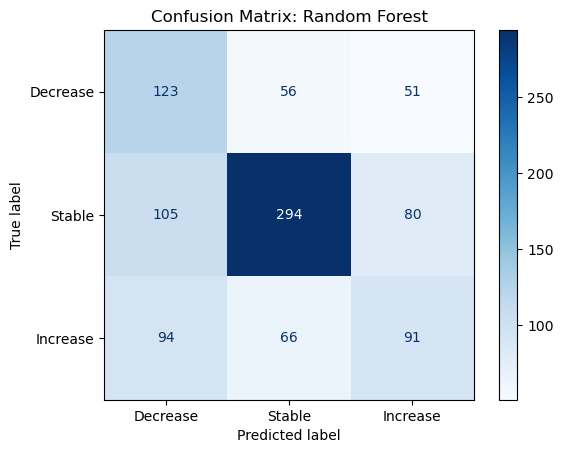

In [80]:
labels = ["Decrease", "Stable", "Increase"]

cm = confusion_matrix(
    y_val_class,
    best_class_predictions,
    labels=labels
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_matrix.plot(cmap="Blues")
plt.title(f"Confusion Matrix: {best_classifier_name}")
plt.show()

In [81]:
# classification mistakes
classification_comparison = class_val[
    ["series", "month", "target_month", "price_movement"]
].copy()

classification_comparison["predicted_movement"] = (
    best_class_predictions
)

classification_comparison["correct"] = (
    classification_comparison["price_movement"]
    == classification_comparison["predicted_movement"]
)

display(
    classification_comparison[
        classification_comparison["correct"] == False
    ].head(20)
)

,series,month,target_month,price_movement,predicted_movement,correct
971,Beans (dry) | KG | Dagahaley (Daadab),2024-09-01,2024-10-01,Stable,Increase,False
972,Beans (dry) | KG | Dagahaley (Daadab),2024-10-01,2024-11-01,Stable,Increase,False
974,Beans (dry) | KG | Dagahaley (Daadab),2024-12-01,2025-01-01,Decrease,Stable,False
975,Beans (dry) | KG | Dagahaley (Daadab),2025-01-01,2025-02-01,Increase,Decrease,False
976,Beans (dry) | KG | Dagahaley (Daadab),2025-02-01,2025-03-01,Decrease,Increase,False
977,Beans (dry) | KG | Dagahaley (Daadab),2025-03-01,2025-04-01,Increase,Decrease,False
980,Beans (dry) | KG | Dagahaley (Daadab),2025-06-01,2025-07-01,Decrease,Increase,False
982,Beans (dry) | KG | Dagahaley (Daadab),2025-08-01,2025-09-01,Decrease,Increase,False
1220,Beans (dry) | KG | Hagadera (Daadab),2024-09-01,2024-10-01,Stable,Increase,False
1223,Beans (dry) | KG | Hagadera (Daadab),2024-12-01,2025-01-01,Decrease,Stable,False


In [82]:
# 6-month outlook: will the price be higher or lower than today? (only moves bigger than THRESHOLD)
six_df = ml_df.dropna(subset=feature_columns + ["target_change_6m_pct"]).copy()
six_df = six_df[six_df["target_change_6m_pct"].abs() > THRESHOLD].copy()
six_df["higher"] = (six_df["target_change_6m_pct"] > 0).astype(int)

# split by origin month; gaps of 6 months keep outcomes from overlapping the next period
m6 = six_df["month"].max()
six_final_start = m6 - pd.DateOffset(months=12)
six_val_start = m6 - pd.DateOffset(months=24)
six_train = six_df[six_df["month"] <= six_val_start - pd.DateOffset(months=6)]
six_val = six_df[(six_df["month"] > six_val_start) & (six_df["month"] <= six_final_start - pd.DateOffset(months=6))]
six_final = six_df[six_df["month"] > six_final_start]

print("Rows -> train:", len(six_train), "| validation:", len(six_val), "| final test:", len(six_final))

Rows -> train: 1483 | validation: 354 | final test: 630


In [86]:
six_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=200, class_weight="balanced", random_state=42
    ),
}

six_results = []
for name, model in six_models.items():
    pipe = Pipeline(steps=[("preprocessor", clone(preprocessor_cls)), ("model", model)])
    pipe.fit(six_train[feature_columns], six_train["higher"])
    pred = pipe.predict(six_val[feature_columns])
    six_results.append({
        "Model": name,
        "Val accuracy": accuracy_score(six_val["higher"], pred),
        "Val macro F1": f1_score(six_val["higher"], pred, average="macro")
    })
majority_six = six_train["higher"].mode().iloc[0]
six_results.append({
    "Model": "Baseline: always the most common class",
    "Val accuracy": accuracy_score(six_val["higher"], np.repeat(majority_six, len(six_val))),
    "Val macro F1": f1_score(six_val["higher"], np.repeat(majority_six, len(six_val)), average="macro")
})
six_results_df = pd.DataFrame(six_results).sort_values("Val macro F1", ascending=False)
display(six_results_df)
best_six_name = six_results_df[six_results_df["Model"].isin(six_models.keys())].iloc[0]["Model"]
print("Chosen on validation:", best_six_name)  

,Model,Val accuracy,Val macro F1
2,Gradient Boosting,0.508475,0.489643
1,Random Forest,0.511299,0.482871
0,Logistic Regression,0.477401,0.436844
3,Baseline: always the most common class,0.415254,0.293413


Chosen on validation: Gradient Boosting


In [87]:
# ANOMALY DETECTION 
# anomaly detection data
anomaly_df = monthly_clean.pct_change() * 100

anomaly_df = anomaly_df.replace(
    [np.inf, -np.inf],
    np.nan
)

display(anomaly_df.head())

series,Beans (dry) | KG | Dagahaley (Daadab),Beans (dry) | KG | Hagadera (Daadab),Beans (dry) | KG | IFO (Daadab),Maize flour | KG | Dagahaley (Daadab),Maize flour | KG | Hagadera (Daadab),Maize flour | KG | IFO (Daadab),Rice | KG | Dagahaley (Daadab),Rice | KG | Hagadera (Daadab),Rice | KG | IFO (Daadab),Sugar | KG | Dagahaley (Daadab),Sugar | KG | Hagadera (Daadab),Sugar | KG | IFO (Daadab),Wheat flour | KG | Dagahaley (Daadab),Wheat flour | KG | Hagadera (Daadab),Wheat flour | KG | IFO (Daadab)
month,,,,,,,,,,,,,,,
2018-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-04-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [88]:
# Isolation Forest
anomaly_results = []

for column in anomaly_df.columns:

    series = anomaly_df[column].dropna()

    if len(series) < 30:
        continue

    X = series.to_frame(name="percentage_change")

    model = IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state= 42
    )

    predictions = model.fit_predict(X)

    result = pd.DataFrame({
        "date": series.index,
        "series": column,
        "percentage_change": series.values,
        "anomaly": predictions == -1,
        "model": "Isolation Forest"
    })

    anomaly_results.append(result)

isolation_results = pd.concat(
    anomaly_results,
    ignore_index=True
)

display(
    isolation_results[
        isolation_results["anomaly"]
    ].head(20)
)

,date,series,percentage_change,anomaly,model
4,2023-04-01,Beans (dry) | KG | Dagahaley (Daadab),24.308904,True,Isolation Forest
11,2023-11-01,Beans (dry) | KG | Dagahaley (Daadab),20.534715,True,Isolation Forest
13,2024-01-01,Beans (dry) | KG | Dagahaley (Daadab),-24.297189,True,Isolation Forest
55,2023-11-01,Beans (dry) | KG | Hagadera (Daadab),30.151934,True,Isolation Forest
57,2024-01-01,Beans (dry) | KG | Hagadera (Daadab),-17.638811,True,Isolation Forest
76,2025-08-01,Beans (dry) | KG | Hagadera (Daadab),-10.057876,True,Isolation Forest
99,2023-11-01,Beans (dry) | KG | IFO (Daadab),19.261932,True,Isolation Forest
101,2024-01-01,Beans (dry) | KG | IFO (Daadab),-30.773614,True,Isolation Forest
103,2024-03-01,Beans (dry) | KG | IFO (Daadab),15.210285,True,Isolation Forest
145,2023-11-01,Maize flour | KG | Dagahaley (Daadab),37.164995,True,Isolation Forest


In [90]:
# local outlier factor
lof_results = []

for column in anomaly_df.columns:

    series = anomaly_df[column].dropna()

    if len(series) < 30:
        continue

    X = series.to_frame(name="percentage_change")

    model = LocalOutlierFactor(
        n_neighbors=20,
        contamination=0.05
    )

    predictions = model.fit_predict(X)

    result = pd.DataFrame({
        "date": series.index,
        "series": column,
        "percentage_change": series.values,
        "anomaly": predictions == -1,
        "model": "LOF"
    })
    lof_results.append(result)

lof_results_df = pd.concat(
    lof_results,
    ignore_index=True
)

display(
    lof_results_df[
        lof_results_df["anomaly"]
    ].head(20)
)

,date,series,percentage_change,anomaly,model
4,2023-04-01,Beans (dry) | KG | Dagahaley (Daadab),24.308904,True,LOF
11,2023-11-01,Beans (dry) | KG | Dagahaley (Daadab),20.534715,True,LOF
13,2024-01-01,Beans (dry) | KG | Dagahaley (Daadab),-24.297189,True,LOF
46,2023-02-01,Beans (dry) | KG | Hagadera (Daadab),10.649724,True,LOF
55,2023-11-01,Beans (dry) | KG | Hagadera (Daadab),30.151934,True,LOF
57,2024-01-01,Beans (dry) | KG | Hagadera (Daadab),-17.638811,True,LOF
94,2023-06-01,Beans (dry) | KG | IFO (Daadab),18.412590,True,LOF
99,2023-11-01,Beans (dry) | KG | IFO (Daadab),19.261932,True,LOF
101,2024-01-01,Beans (dry) | KG | IFO (Daadab),-30.773614,True,LOF
145,2023-11-01,Maize flour | KG | Dagahaley (Daadab),37.164995,True,LOF


In [91]:
# one class svm
svm_results = []

for column in anomaly_df.columns:

    series = anomaly_df[column].dropna()

    if len(series) < 30:
        continue

    X = series.to_frame(name="percentage_change")

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    model = OneClassSVM(
        kernel="rbf",
        gamma="scale",
        nu=0.05
    )

    predictions = model.fit_predict(X_scaled)

    result = pd.DataFrame({
        "date": series.index,
        "series": column,
        "percentage_change": series.values,
        "anomaly": predictions == -1,
        "model": "One-Class SVM"
    })

    svm_results.append(result)

svm_results_df = pd.concat(
    svm_results,
    ignore_index=True
)

display(
    svm_results_df[
        svm_results_df["anomaly"]
    ].head(20)
)

,date,series,percentage_change,anomaly,model
2,2023-02-01,Beans (dry) | KG | Dagahaley (Daadab),3.305421,True,One-Class SVM
3,2023-03-01,Beans (dry) | KG | Dagahaley (Daadab),4.685722,True,One-Class SVM
4,2023-04-01,Beans (dry) | KG | Dagahaley (Daadab),24.308904,True,One-Class SVM
12,2023-12-01,Beans (dry) | KG | Dagahaley (Daadab),2.188782,True,One-Class SVM
15,2024-03-01,Beans (dry) | KG | Dagahaley (Daadab),-3.567762,True,One-Class SVM
20,2024-08-01,Beans (dry) | KG | Dagahaley (Daadab),-4.721383,True,One-Class SVM
23,2024-11-01,Beans (dry) | KG | Dagahaley (Daadab),-2.707581,True,One-Class SVM
25,2025-01-01,Beans (dry) | KG | Dagahaley (Daadab),-5.805989,True,One-Class SVM
26,2025-02-01,Beans (dry) | KG | Dagahaley (Daadab),4.811026,True,One-Class SVM
31,2025-07-01,Beans (dry) | KG | Dagahaley (Daadab),-3.244938,True,One-Class SVM


In [92]:
# anomaly counts
anomaly_summary = pd.DataFrame([
    {
        "Model": "Isolation Forest",
        "Anomalies": isolation_results["anomaly"].sum()
    },
    {
        "Model": "LOF",
        "Anomalies": lof_results_df["anomaly"].sum()
    },
    {
        "Model": "One-Class SVM",
        "Anomalies": svm_results_df["anomaly"].sum()
    }
])

display(anomaly_summary)

,Model,Anomalies
0,Isolation Forest,45
1,LOF,45
2,One-Class SVM,136


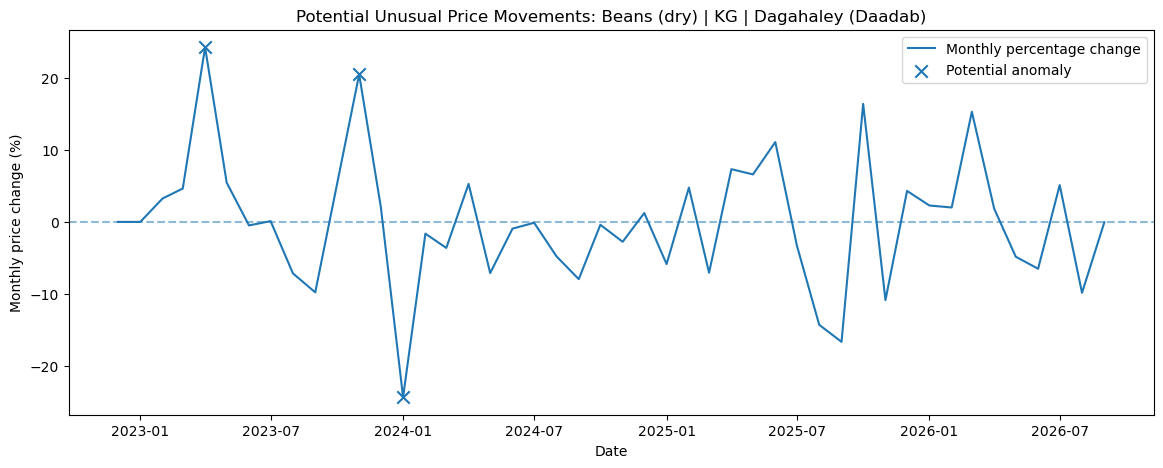

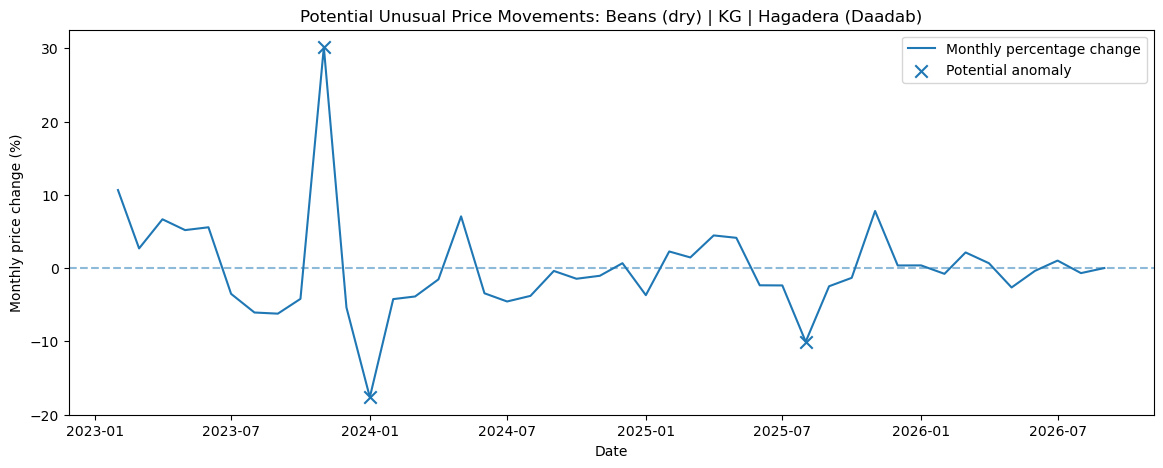

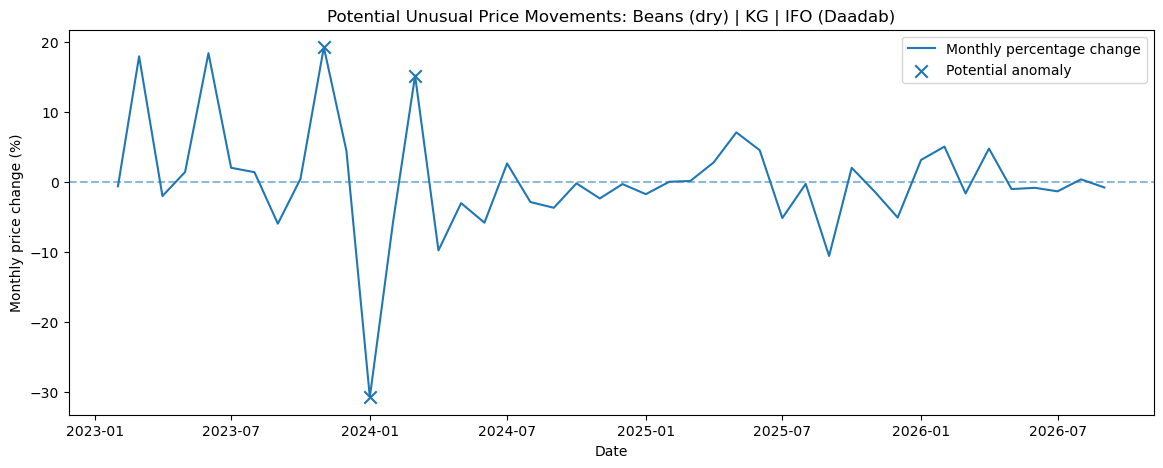

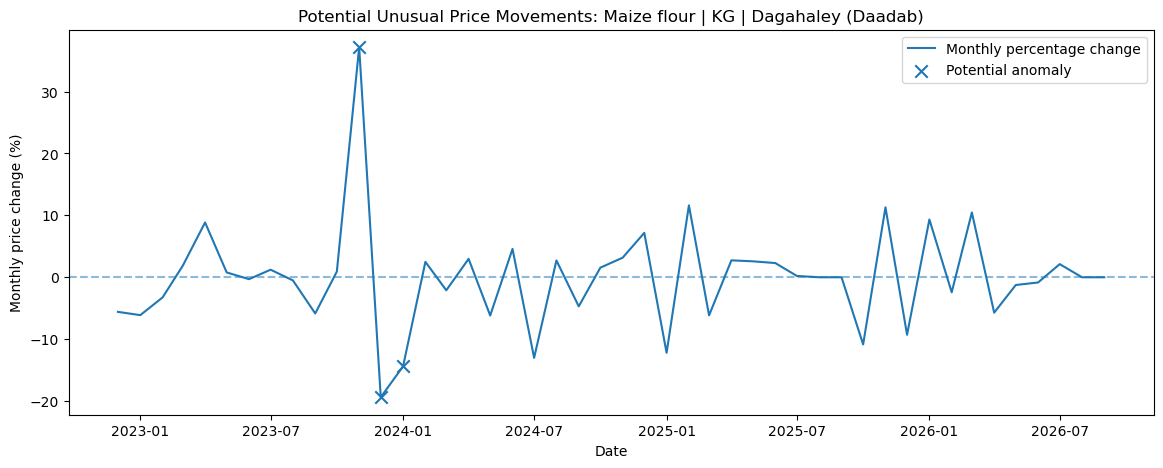

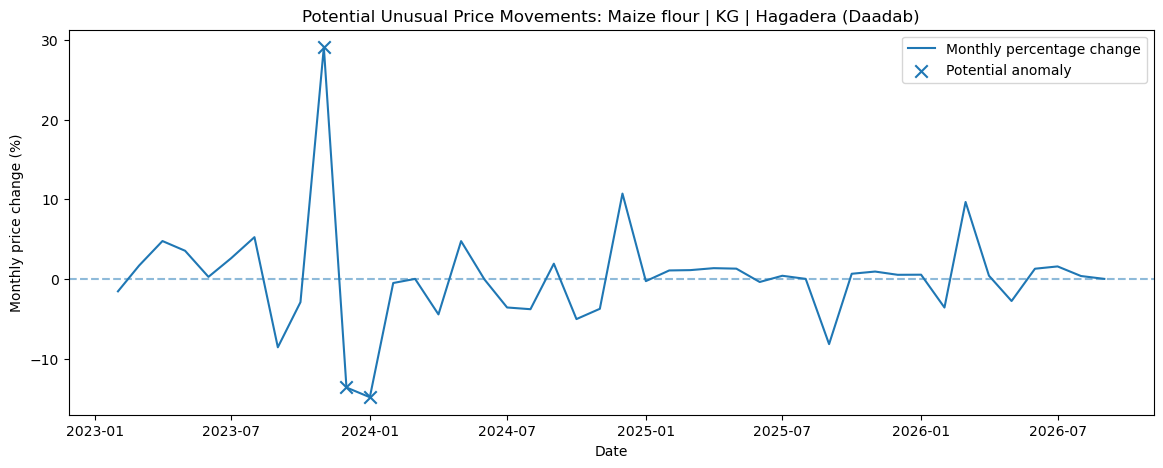

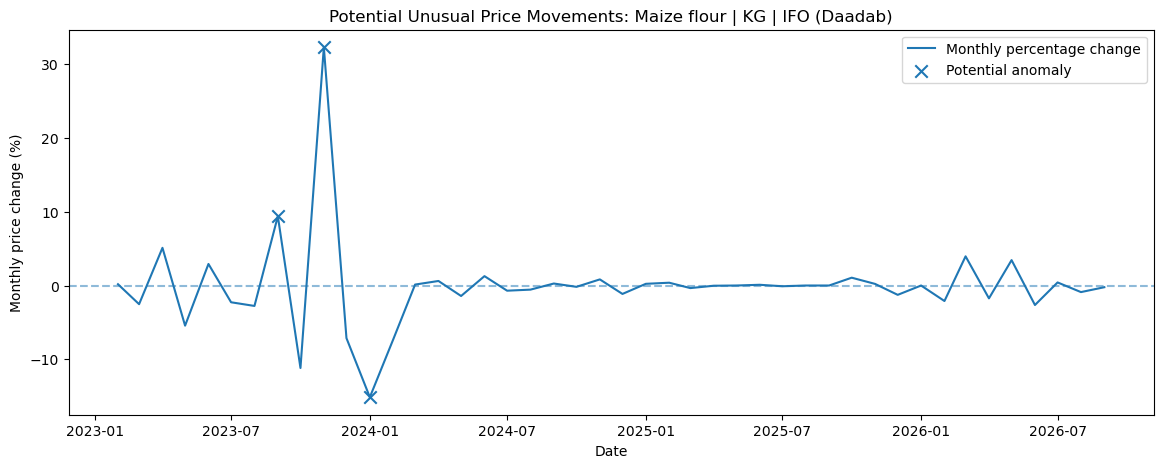

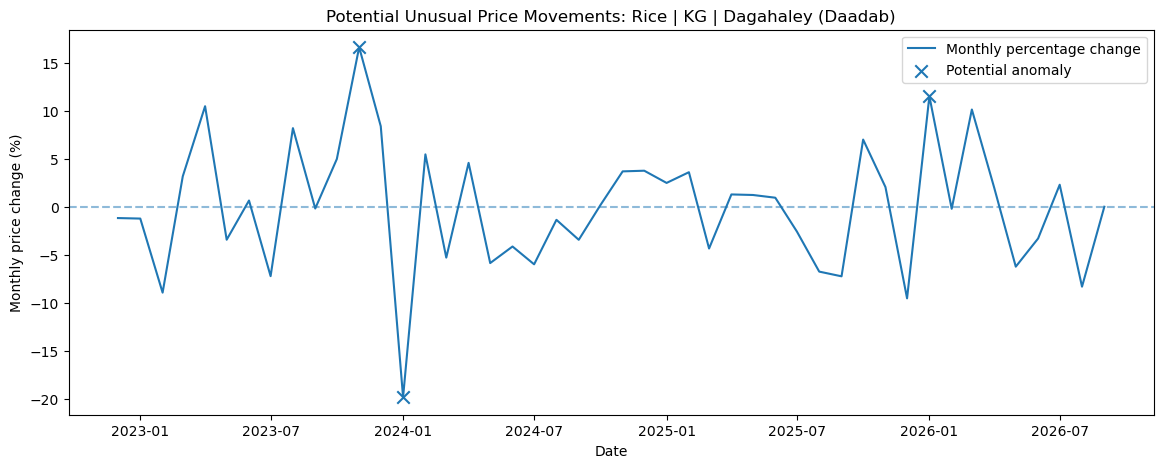

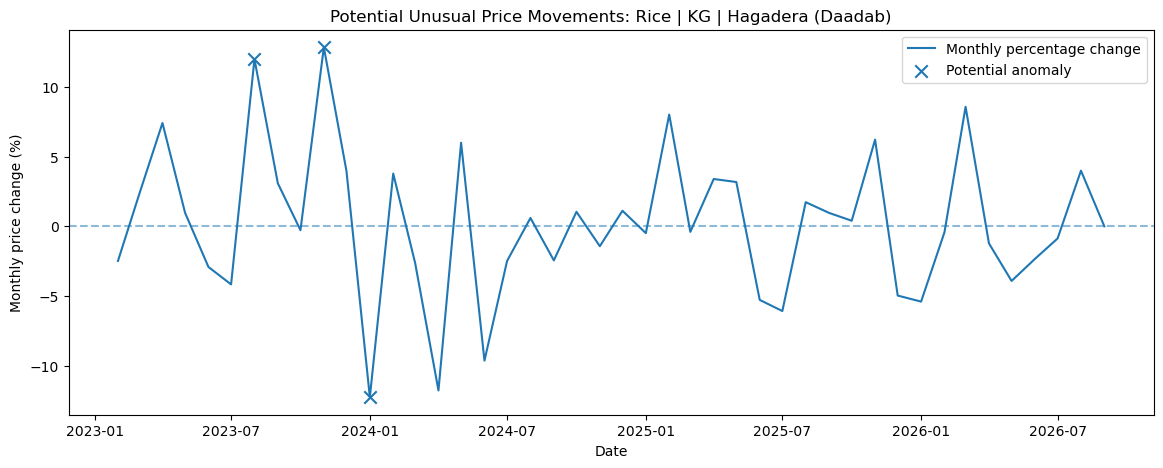

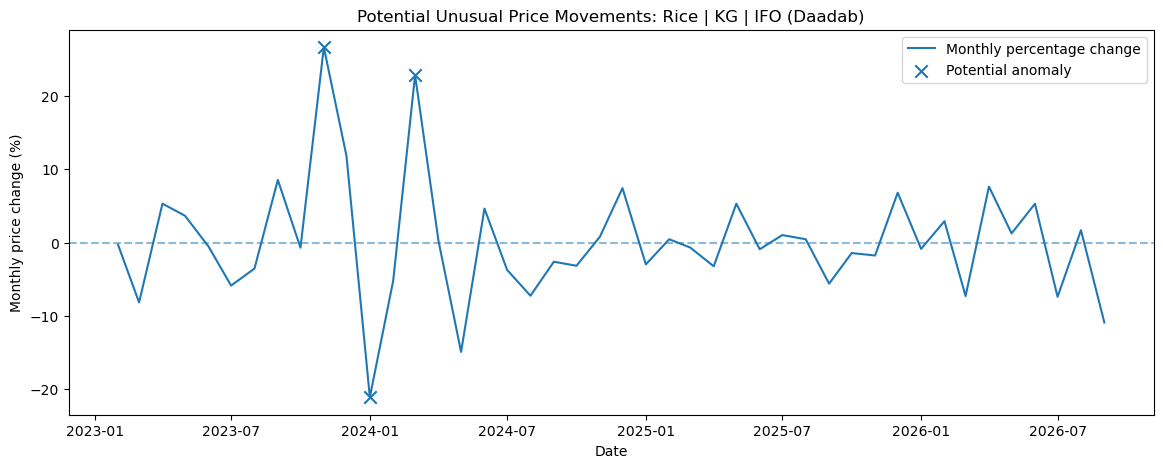

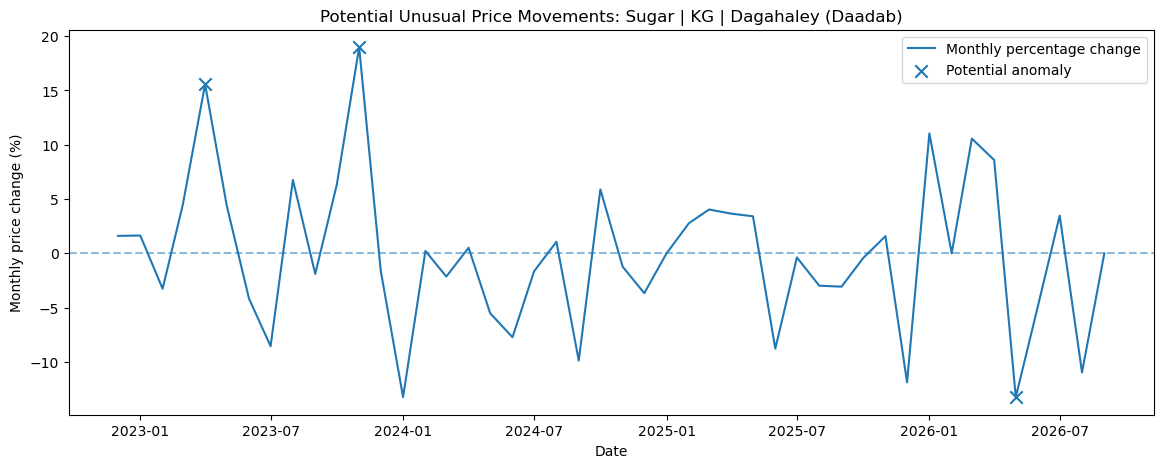

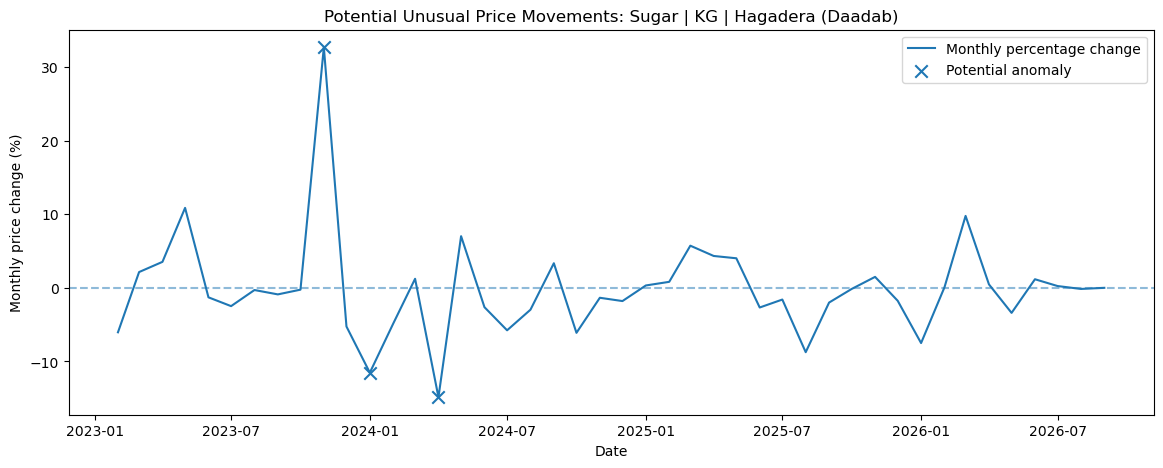

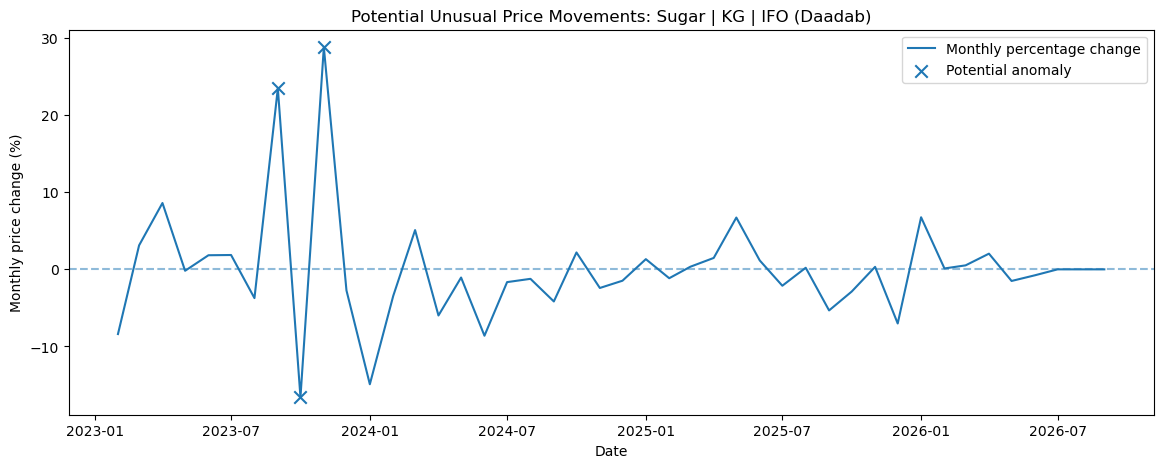

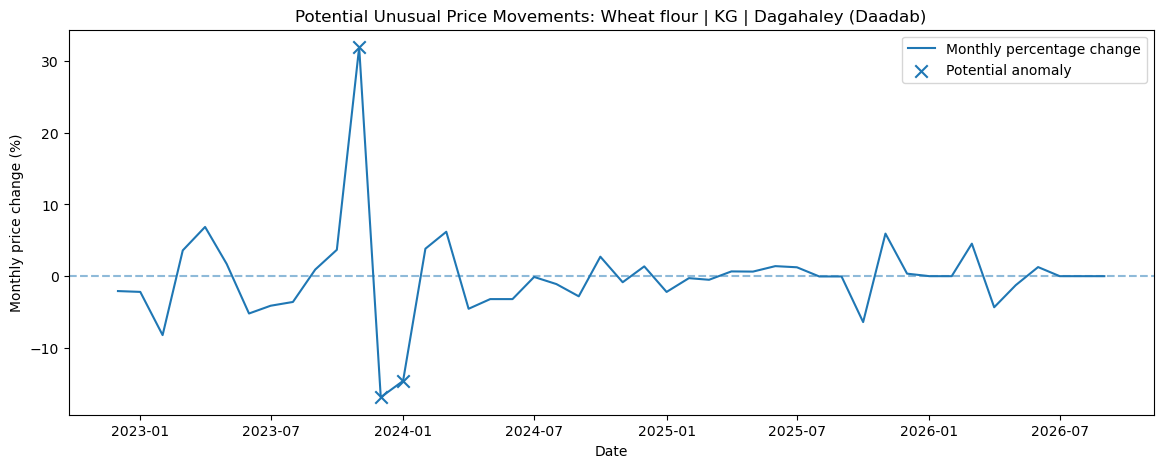

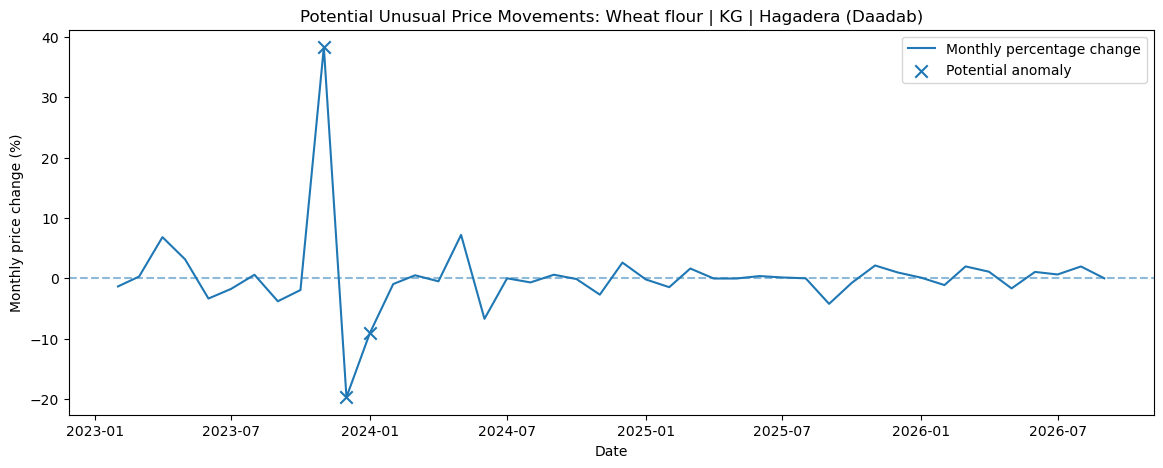

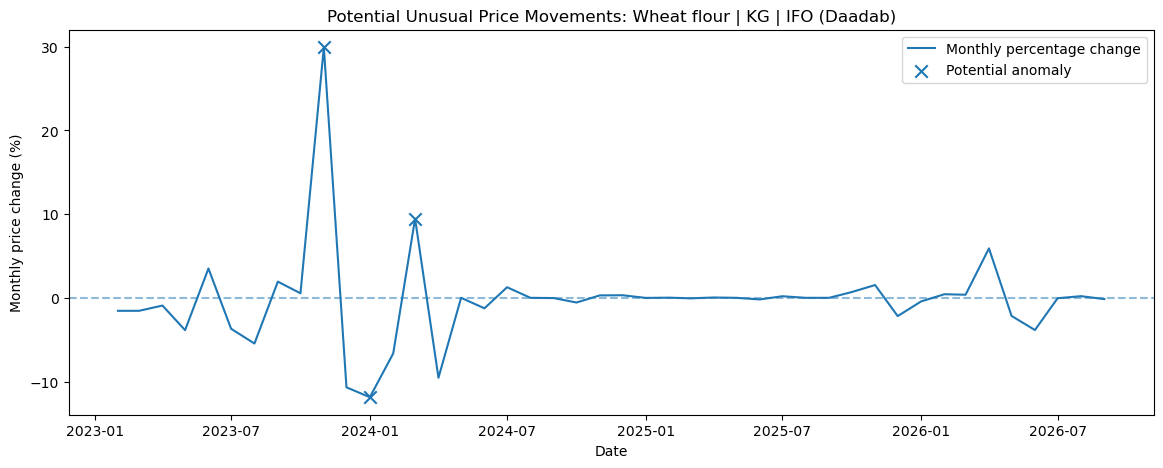

In [93]:
for column in anomaly_df.columns:

    subset = isolation_results[
        isolation_results["series"] == column
    ]

    if subset.empty:
        continue

    plt.figure(figsize=(14, 5))

    plt.plot(
        subset["date"],
        subset["percentage_change"],
        label="Monthly percentage change"
    )

    flagged = subset[subset["anomaly"]]

    plt.scatter(
        flagged["date"],
        flagged["percentage_change"],
        label="Potential anomaly",
        marker="x",
        s=80
    )

    plt.axhline(0, linestyle="--", alpha=0.5)

    plt.title(f"Potential Unusual Price Movements: {column}")
    plt.xlabel("Date")
    plt.ylabel("Monthly price change (%)")
    plt.legend()
    plt.show()

In [94]:
# MODEL COMPARISON (VALIDATION PERIOD) 
forecast_comparison = (
    forecast_results_df
    .sort_values(["Series", "RMSE"])
    .reset_index(drop=True)
)

display(forecast_comparison)

,Series,Model,MAE,RMSE,MAPE
0,Beans (dry) | KG | Dagahaley (Daadab),Naive,8.583000,9.783075,7.062341
1,Beans (dry) | KG | Dagahaley (Daadab),"ARIMA(1,1,1)",9.074495,10.033693,7.729824
2,Beans (dry) | KG | Dagahaley (Daadab),Holt-Winters,13.193580,15.938431,11.373140
3,Beans (dry) | KG | Dagahaley (Daadab),"SARIMA(1,1,1)(1,1,1,12)",11.903488,20.512018,10.643547
4,Beans (dry) | KG | Dagahaley (Daadab),"SARIMA(1,1,1)(1,1,1,12)",11.903488,20.512018,10.643547
...,...,...,...,...,...
70,Wheat flour | KG | IFO (Daadab),"ARIMA(1,1,1)",1.366868,2.313150,1.313530
71,Wheat flour | KG | IFO (Daadab),Naive,1.255556,2.495258,1.197008
72,Wheat flour | KG | IFO (Daadab),"SARIMA(1,1,1)(1,1,1,12)",10.470763,11.039399,10.295700
73,Wheat flour | KG | IFO (Daadab),"SARIMA(1,1,1)(1,1,1,12)",10.470763,11.039399,10.295700


In [95]:
regression_comparison = (
    regression_results_df
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(regression_comparison)

,Model,MAE,RMSE,MAPE,R2
0,Linear Regression,8.026007,14.607747,6.855580,0.990012
1,Naive (last price),7.490521,14.935801,5.895724,0.989559
2,Extra Trees,9.324636,18.469700,6.930853,0.984033
3,Random Forest,9.208994,18.487699,6.710496,0.984002
4,XGBoost,9.601518,18.830644,7.838744,0.983403
5,Decision Tree,12.553292,26.026613,10.593571,0.968295


In [96]:
# FINAL UNTOUCHED TEST
# FINAL TEST 1/3: next-month price. Refit the validation winner on train + validation, score the last 12 months once
from sklearn.base import clone

reg_trainval = pd.concat([reg_train, reg_val])
final_reg_model = clone(trained_regression_models[best_regression_name])
final_reg_model.fit(reg_trainval[reg_features], reg_trainval["target_price"])

final_reg_pred = final_reg_model.predict(X_final_reg)
final_naive_pred = reg_final["price"].to_numpy()

final_reg_df = pd.DataFrame([
    {"Model": best_regression_name, **regression_metrics(y_final_reg, final_reg_pred)},
    {"Model": "Naive (last price)", **regression_metrics(y_final_reg, final_naive_pred)},
])
print("FINAL TEST, next-month price:", len(reg_final), "rows,", reg_final["target_month"].min().date(), "to", reg_final["target_month"].max().date())
display(final_reg_df)

FINAL TEST, next-month price: 894 rows, 2025-10-01 to 2026-09-01


,Model,MAE,RMSE,MAPE,R2
0,Linear Regression,5.377360,10.258524,6.461974,0.995595
1,Naive (last price),4.954452,10.595977,4.954612,0.995301


In [97]:
# FINAL TEST 2/3: next-month direction. The model and the confidence cutoff are both chosen on VALIDATION only
cls_cutoffs = [0.5, 0.6, 0.7, 0.8]

# cutoff rule (fixed before looking at the final test): the lowest cutoff whose validation accuracy is at least 65%
# while still answering at least 10% of cases; fall back to 0.7
val_proba = best_classifier.predict_proba(X_val_class)
val_conf = val_proba.max(axis=1)
if best_classifier_name == "XGBoost":
    val_pred = label_encoder.inverse_transform(val_proba.argmax(axis=1))
else:
    val_pred = np.asarray(best_classifier.classes_)[val_proba.argmax(axis=1)]

chosen_cutoff = 0.7
for c in cls_cutoffs:
    keep = val_conf >= c
    if keep.mean() >= 0.10 and accuracy_score(y_val_class.to_numpy()[keep], val_pred[keep]) >= 0.65:
        chosen_cutoff = c
        break
print("Model chosen on validation:", best_classifier_name, "| confidence cutoff chosen on validation:", chosen_cutoff)

# refit on train + validation, then score the final test once
cls_trainval = pd.concat([class_train, class_val])
final_cls_pipe = clone(trained_classification_models[best_classifier_name])
if best_classifier_name == "XGBoost":
    final_cls_pipe.fit(cls_trainval[feature_columns], label_encoder.transform(cls_trainval["price_movement"]))
    final_classes = label_encoder.classes_
else:
    final_cls_pipe.fit(cls_trainval[feature_columns], cls_trainval["price_movement"])
    final_classes = final_cls_pipe.classes_

final_proba = final_cls_pipe.predict_proba(X_final_class)
final_pred = np.asarray(final_classes)[final_proba.argmax(axis=1)]
final_conf = final_proba.max(axis=1)
actual_final = y_final_class.to_numpy()

final_majority = cls_trainval["price_movement"].mode().iloc[0]
final_last_change = np.expm1(class_final["ret_0"].to_numpy()) * 100
final_persist = np.select([final_last_change > THRESHOLD, final_last_change < -THRESHOLD], ["Increase", "Decrease"], default="Stable")

final_cls_df = pd.DataFrame([
    {"Model": best_classifier_name, **evaluate_classifier(actual_final, final_pred)},
    {"Model": "Baseline: always the most common class", **evaluate_classifier(actual_final, np.repeat(final_majority, len(actual_final)))},
    {"Model": "Baseline: repeat last month's direction", **evaluate_classifier(actual_final, final_persist)},
])
print("FINAL TEST, next-month direction:", len(actual_final), "rows")
display(final_cls_df)

keep = final_conf >= chosen_cutoff
print(f"Confident answers (cutoff {chosen_cutoff} chosen on validation): {int(keep.sum())} cases = {keep.mean():.1%} of the test, accuracy {accuracy_score(actual_final[keep], final_pred[keep]):.3f}")

Model chosen on validation: Random Forest | confidence cutoff chosen on validation: 0.5
FINAL TEST, next-month direction: 894 rows


,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.568233,0.517510,0.511832,0.510008
1,Baseline: always the most common class,0.535794,0.178598,0.333333,0.232581
2,Baseline: repeat last month's direction,0.531320,0.453473,0.453477,0.453428


Confident answers (cutoff 0.5 chosen on validation): 241 cases = 27.0% of the test, accuracy 0.685


In [98]:
# FINAL TEST 3/3: 6-month higher-or-lower. Refit the validation winner on train + validation, score once
six_trainval = pd.concat([six_train, six_val])
final_six_pipe = Pipeline(steps=[("preprocessor", clone(preprocessor_cls)), ("model", clone(six_models[best_six_name]))])
final_six_pipe.fit(six_trainval[feature_columns], six_trainval["higher"])
final_six_pred = final_six_pipe.predict(six_final[feature_columns])

six_majority = six_trainval["higher"].mode().iloc[0]
six_final_df = pd.DataFrame([
    {"Model": best_six_name,
     "Accuracy": accuracy_score(six_final["higher"], final_six_pred),
     "Macro F1": f1_score(six_final["higher"], final_six_pred, average="macro")},
    {"Model": "Baseline: always the most common class",
     "Accuracy": accuracy_score(six_final["higher"], np.repeat(six_majority, len(six_final))),
     "Macro F1": f1_score(six_final["higher"], np.repeat(six_majority, len(six_final)), average="macro")},
])
print("FINAL TEST, 6-month higher or lower:", len(six_final), "rows (outcomes overlap, so treat as noisy)")
display(six_final_df)

FINAL TEST, 6-month higher or lower: 630 rows (outcomes overlap, so treat as noisy)


,Model,Accuracy,Macro F1
0,Gradient Boosting,0.655556,0.633362
1,Baseline: always the most common class,0.476190,0.322581


In [99]:
# FINAL FORECASTS 
future_forecasts = []

best_forecast_lookup = (
    best_forecast_models.set_index("Series")["Model"].to_dict()
)

for column in monthly_clean.columns:

    series = monthly_clean[column].dropna().asfreq("MS")

    if len(series) < 36:
        continue

    selected_model = best_forecast_lookup.get(column)

    try:
        if selected_model == "Naive":
            forecast_values = np.repeat(
                series.iloc[-1],
                6
            )

        elif selected_model == "Holt-Winters":
            fitted = ExponentialSmoothing(
                series,
                trend="add",
                seasonal="add",
                seasonal_periods=12,
                initialization_method="estimated"
            ).fit(optimized=True)

            forecast_values = fitted.forecast(6).values

        elif selected_model == "ARIMA(1,1,1)":
            fitted = ARIMA(
                series,
                order=(1, 1, 1)
            ).fit()

            forecast_values = fitted.forecast(6).values

        elif selected_model == "SARIMA(1,1,1)(1,1,1,12)":
            fitted = ARIMA(
                series,
                order=(1, 1, 1),
                seasonal_order=(1, 1, 1, 12)
            ).fit()

            forecast_values = fitted.forecast(6).values

        else:
            continue

        future_dates = pd.date_range(
            start=series.index[-1] + pd.offsets.MonthBegin(1),
            periods=6,
            freq="MS"
        )

        for date, value in zip(future_dates, forecast_values):
            future_forecasts.append({
                "series": column,
                "forecast_date": date,
                "predicted_price": value,
                "selected_model": selected_model
            })

    except Exception as error:
        print(f"Could not forecast {column}: {error}")

future_forecasts_df = pd.DataFrame(future_forecasts)

display(future_forecasts_df)

,series,forecast_date,predicted_price,selected_model
0,Beans (dry) | KG | Dagahaley (Daadab),2026-09-01,114.060000,Naive
1,Beans (dry) | KG | Dagahaley (Daadab),2026-10-01,114.060000,Naive
2,Beans (dry) | KG | Dagahaley (Daadab),2026-11-01,114.060000,Naive
3,Beans (dry) | KG | Dagahaley (Daadab),2026-12-01,114.060000,Naive
4,Beans (dry) | KG | Dagahaley (Daadab),2027-01-01,114.060000,Naive
...,...,...,...,...
85,Wheat flour | KG | IFO (Daadab),2026-11-01,100.602181,"ARIMA(1,1,1)"
86,Wheat flour | KG | IFO (Daadab),2026-12-01,100.677241,"ARIMA(1,1,1)"
87,Wheat flour | KG | IFO (Daadab),2027-01-01,100.708829,"ARIMA(1,1,1)"
88,Wheat flour | KG | IFO (Daadab),2027-02-01,100.722123,"ARIMA(1,1,1)"


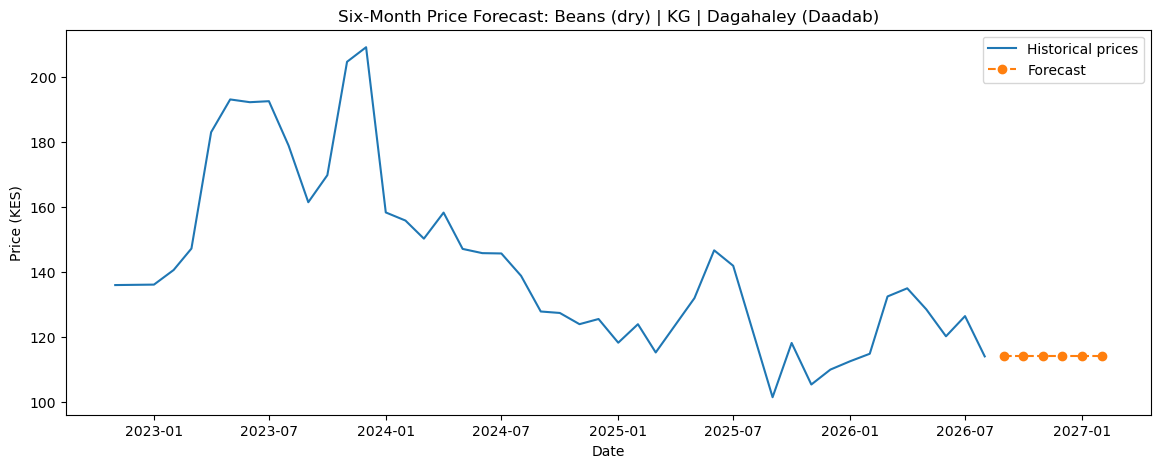

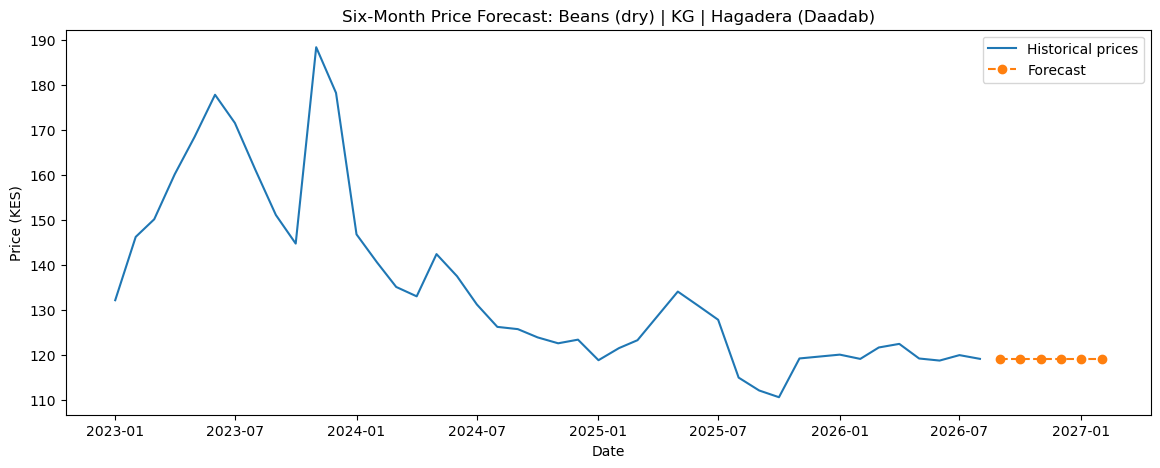

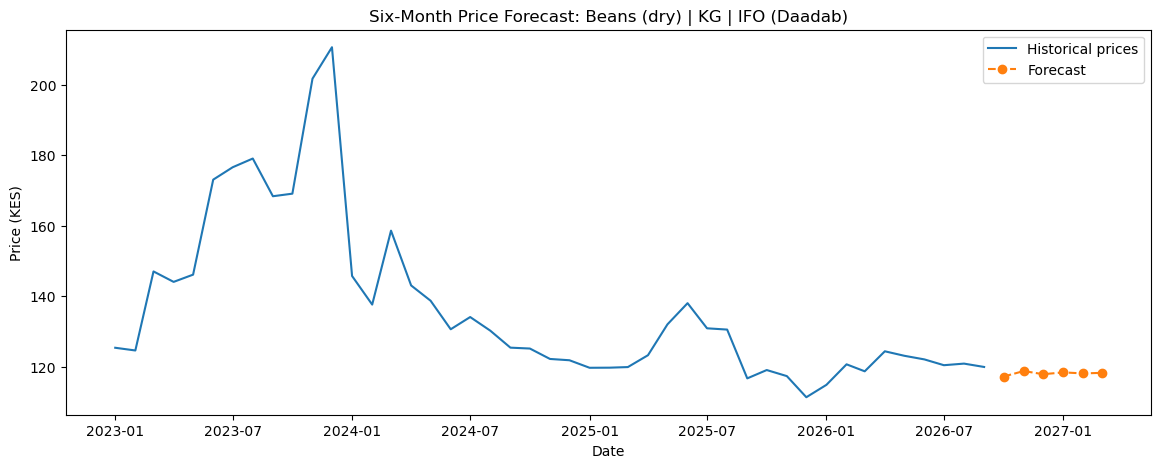

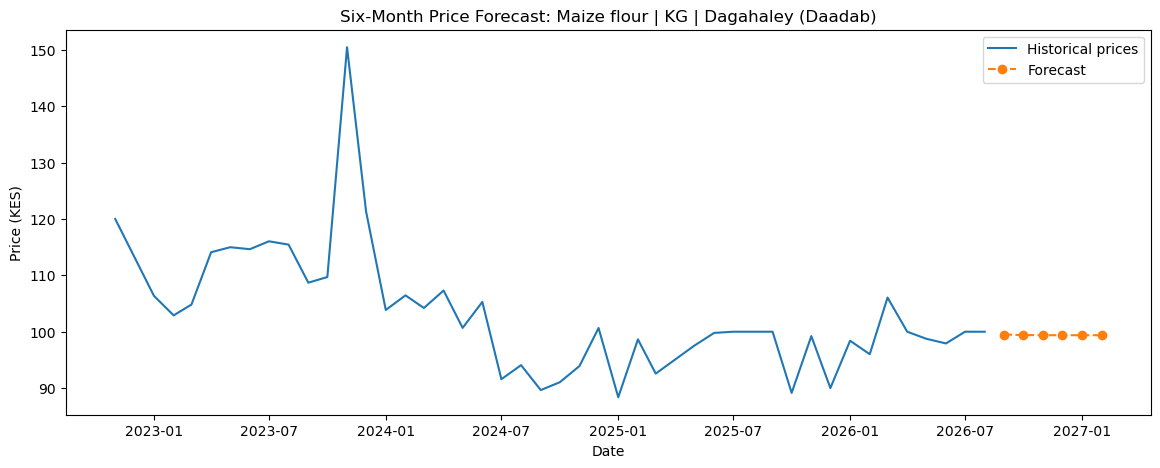

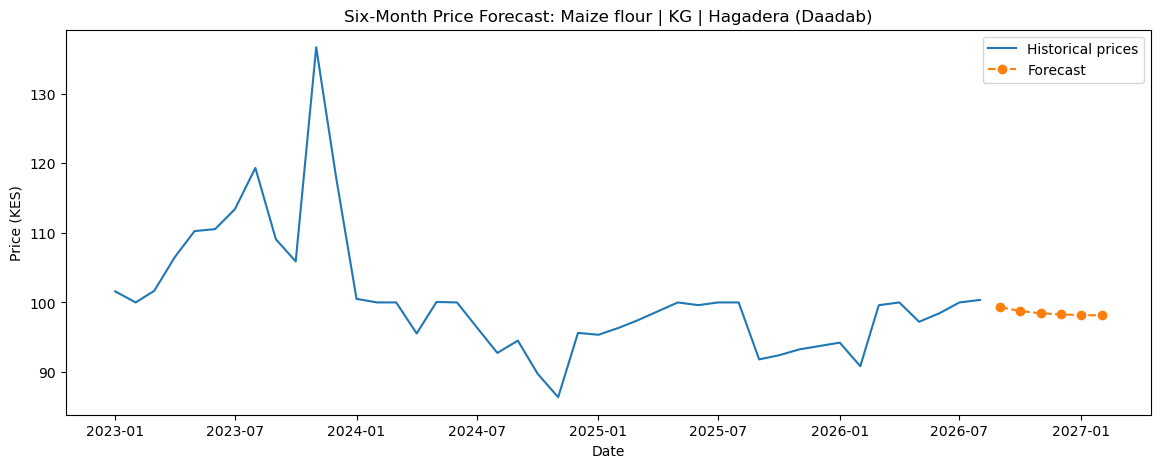

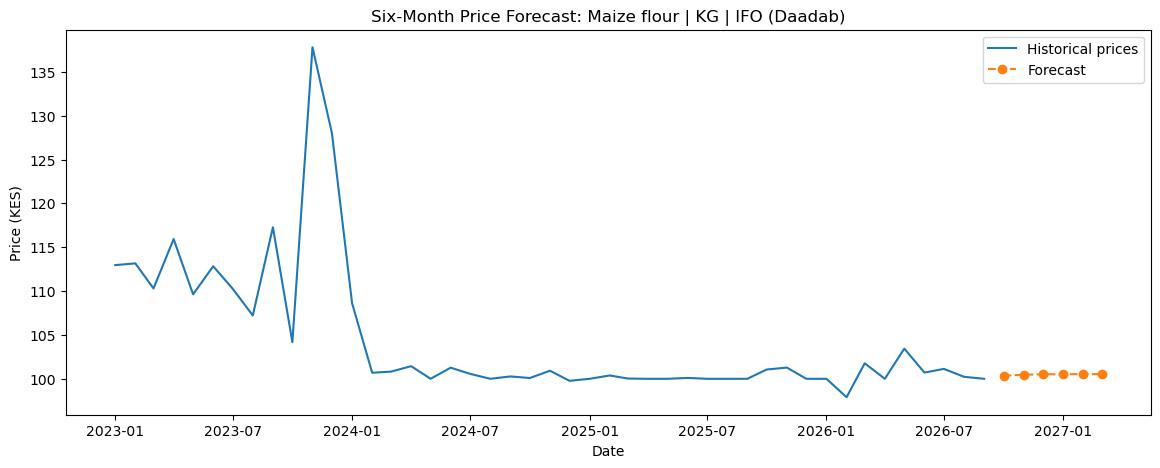

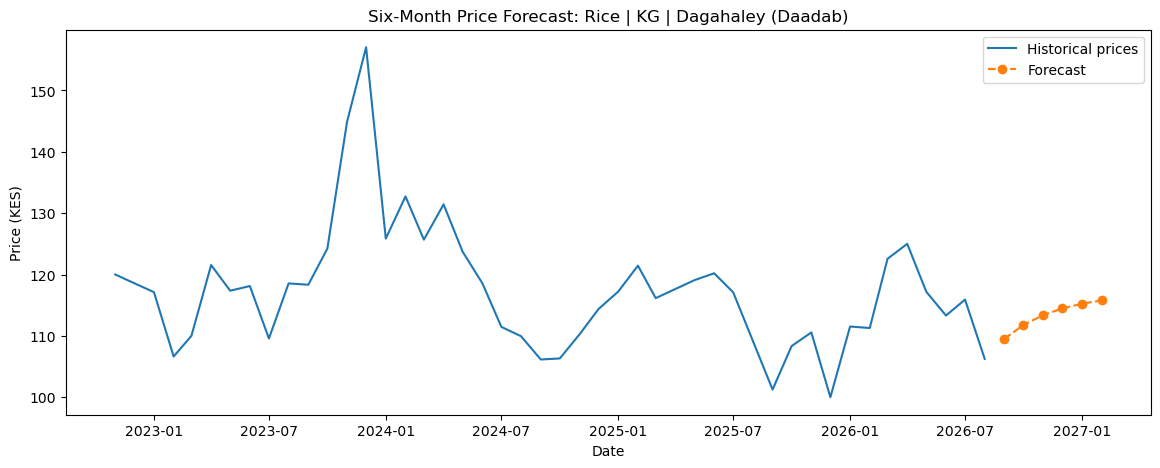

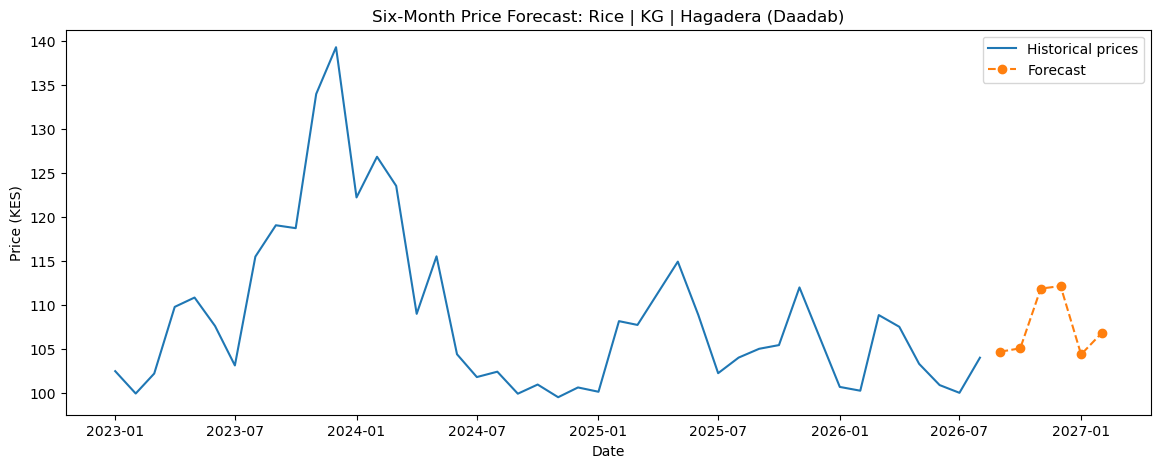

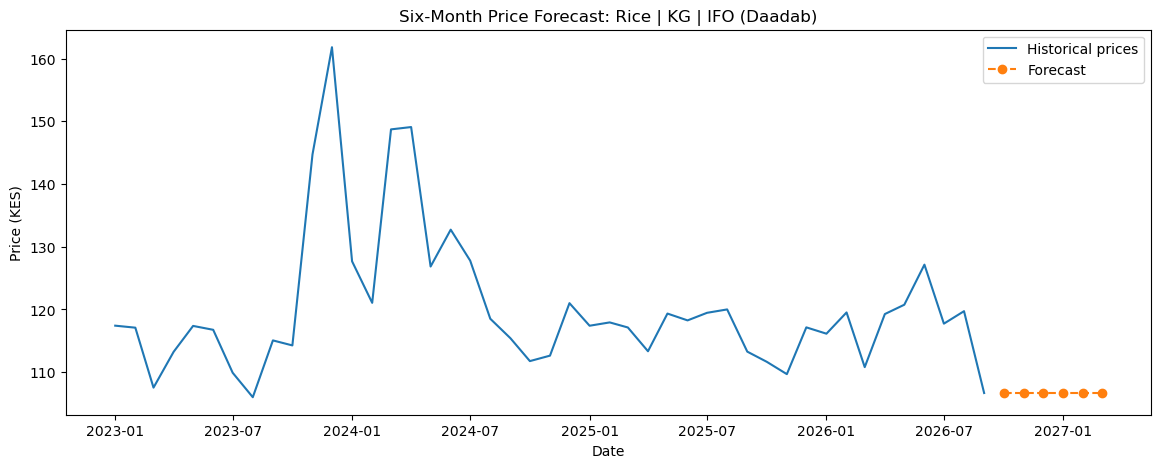

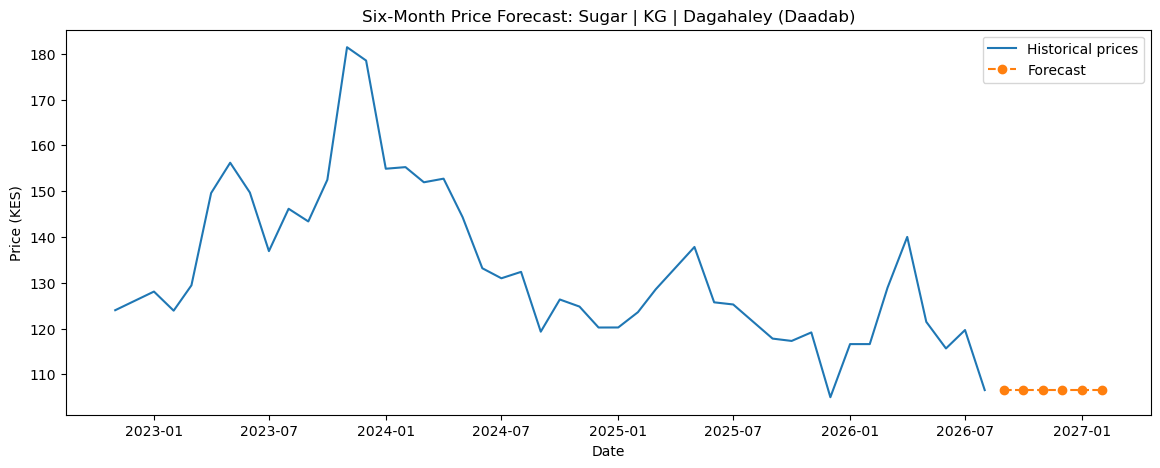

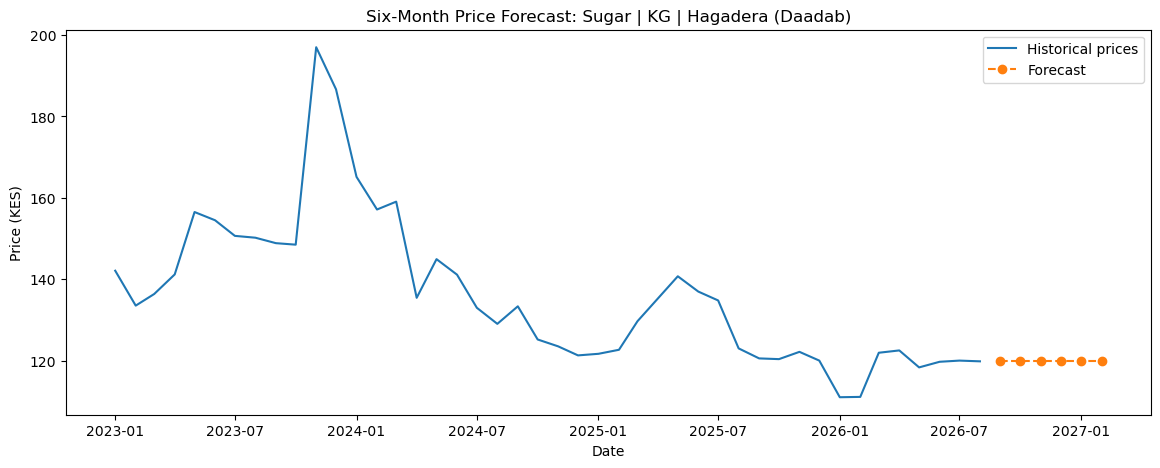

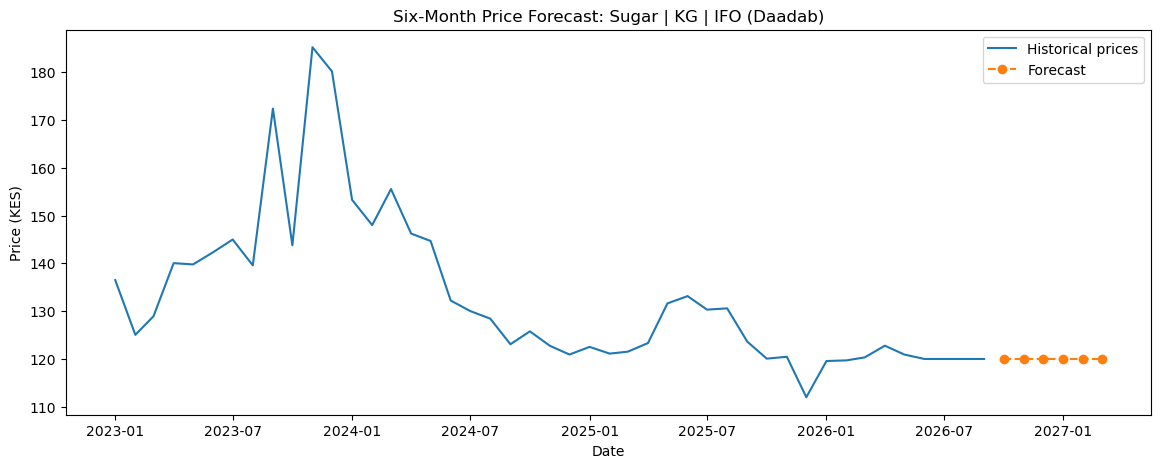

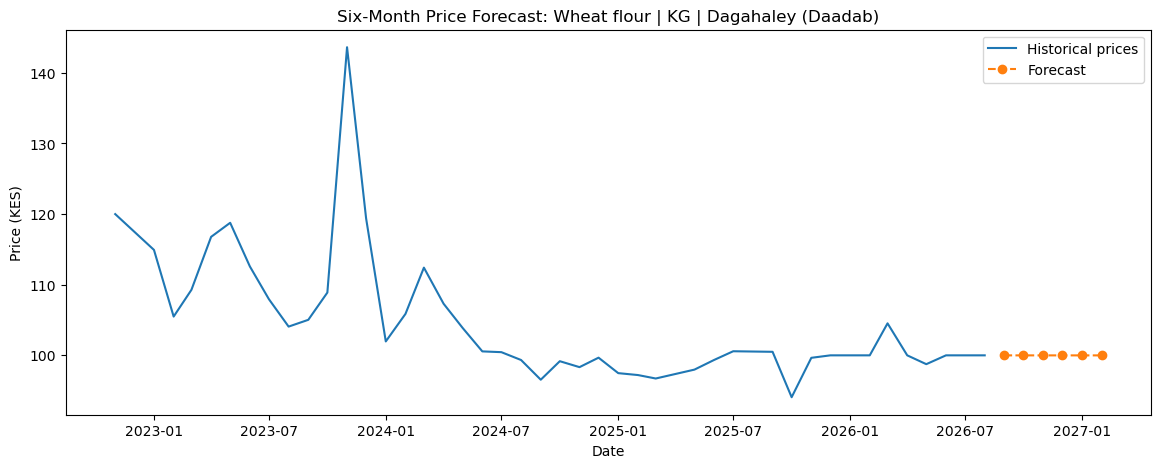

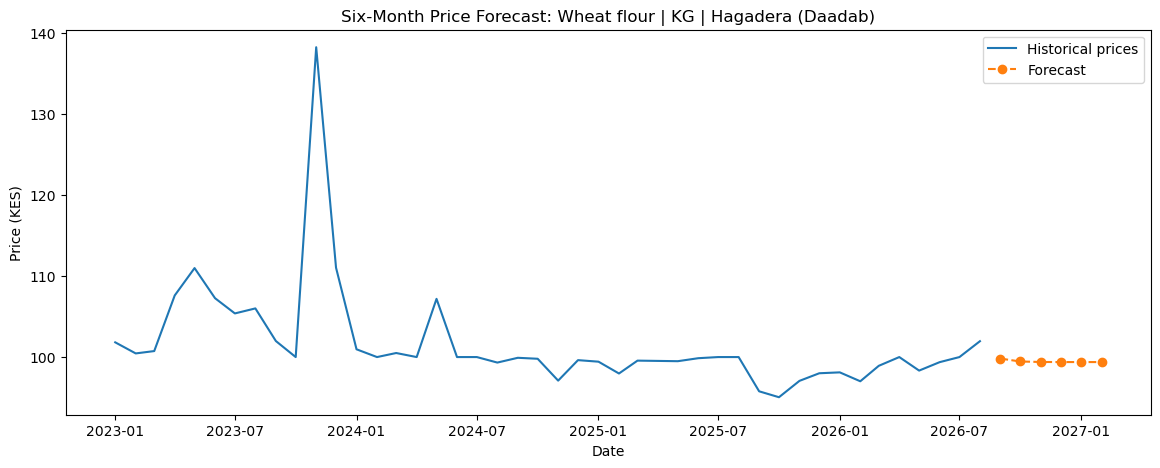

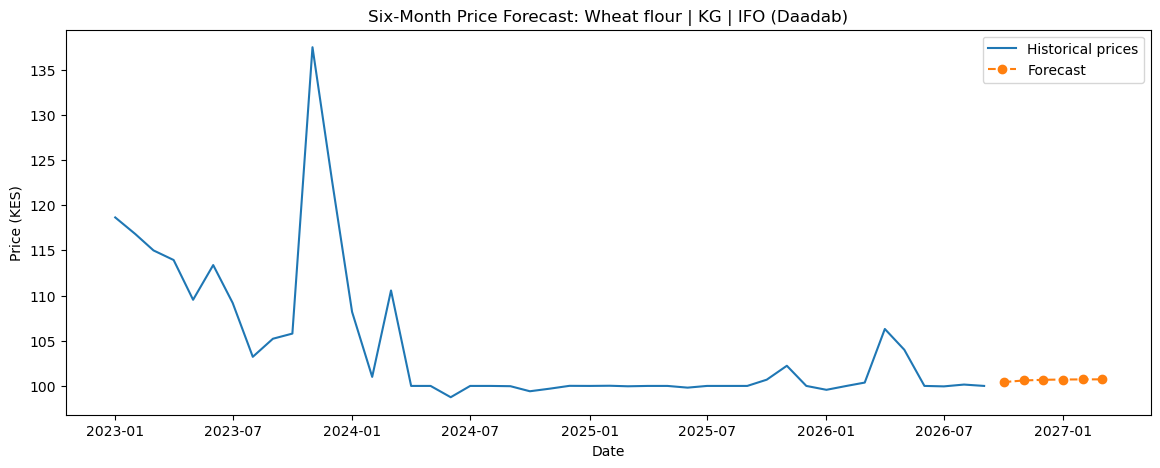

In [100]:
for column in monthly_clean.columns:

    history = monthly_clean[column].dropna()

    forecast = future_forecasts_df[
        future_forecasts_df["series"] == column
    ]

    if forecast.empty:
        continue

    plt.figure(figsize=(14, 5))

    plt.plot(
        history.index,
        history.values,
        label="Historical prices"
    )

    plt.plot(
        forecast["forecast_date"],
        forecast["predicted_price"],
        marker="o",
        linestyle="--",
        label="Forecast"
    )

    plt.title(f"Six-Month Price Forecast: {column}")
    plt.xlabel("Date")
    plt.ylabel("Price (KES)")
    plt.legend()
    plt.show()